# 🪸 Coral Reef Health Classification — Final Benchmark Pipeline
### 4 Transfer-Learning CNNs · SE-ResNet CNN from scratch · DINOv2 Vision Transformer
**Dataset:** `jxwleong/coral-reef-dataset` (Kaggle) · **Task:** 3-class benthic health — `Healthy Coral` · `Dead / Degraded` · `Substrate / CCA`

This notebook merges the three Review-2 notebooks (transfer learning, CNN-from-scratch + Grad-CAM, DINOv2 point-crop + sliding window) into **one like-for-like pipeline**.
Every model is trained and evaluated on the **same point-centred 224×224 crops** and the **same grouped-by-image split**, then compared under two protocols:

| Protocol | What is measured |
|---|---|
| **A. Point-crop** | Accuracy, balanced accuracy, macro/weighted F1, ROC-AUC, PR-AP, κ, ECE on held-out expert points (crop centred on each point) |
| **B. Sliding window** | 224×224 window slid over whole held-out quadrats, Gaussian-blended into a dense health map → accuracy / F1 **at the expert points**, live-coral **cover error (MAE / r)**, and ms per quadrat |
| **Efficiency** | Params, size, GFLOPs, GPU latency (mean/p50/p95/p99), CPU latency, throughput |
| **Explainability** | Grad-CAM for the **best transfer-learning model**, the **SE-CNN** and the **DINOv2 ViT**, plus quantitative checks (centre-mass, pointing-game, deletion test) |

**What was improved over Review 2** (so every model reaches its best level):
1. All six models now train on **24 000 class-balanced point crops** (instead of 1.7 k whole images) → clean labels, 14× more data.
2. **Zero-CPU-bottleneck data pipeline** – crops cached as `uint8` arrays, augmentation (dihedral flips/rot90, affine, colour jitter) runs **on the GPU** (Colab has only 2 CPU cores; the old DINOv2 run needed ~190 s/epoch).
3. Per-model tuned recipes: AdamW + differential LR (backbone vs head) + OneCycle + label smoothing + AMP; DINOv2 gets its top-4 blocks unfrozen with a small LR.
4. **Checkpoint chosen on validation macro-F1** (natural class distribution), not accuracy.
5. **Prior-shift correction (logit adjustment) with τ tuned on the validation set** – replaces the fixed Bayesian prior that hurt Dead-class recall; plus optional 4-fold TTA.
6. Corrupt images are dropped (the old code silently created black crops for them).

> **Runtime:** use **Runtime → Change runtime type → T4 GPU**. Profile `full` (default) fits the free tier (est. 1.5–2.5 h incl. the 18 GB dataset download); `fast` ≈ 40–60 min. Everything is saved under `/content/coral_final/` and zipped for download at the end.


## 1 · Setup, configuration & hardware check
Pick the **profile** here (`full` = recommended on a free T4; `fast` ≈ 40-60 min; `cpu` for a CPU-only runtime). Set `USE_DRIVE = True` if you want outputs mirrored to Google Drive.

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 1 · SETUP · CONFIG · HARDWARE
# ═══════════════════════════════════════════════════════════════════════════
import os, sys, subprocess, importlib, importlib.util, time, json, math, random, shutil, warnings, zipfile, copy, threading, queue, textwrap
warnings.filterwarnings('ignore')

def _pip(*pkgs):
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *pkgs], check=False)

_need = {'kagglehub': 'kagglehub', 'timm': 'timm', 'opencv-python-headless': 'cv2', 'seaborn': 'seaborn'}
_missing = [p for p, m in _need.items() if importlib.util.find_spec(m) is None]
if _missing:
    print('Installing:', _missing); _pip(*_missing)

import numpy as np
import pandas as pd
import matplotlib
IN_COLAB = 'google.colab' in sys.modules
try:
    from IPython import get_ipython
    _IN_NB = get_ipython() is not None and 'IPKernelApp' in get_ipython().config
except Exception:
    _IN_NB = False
if not _IN_NB:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import cv2
from PIL import Image, ImageFile
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor
try:
    from IPython.display import display
except Exception:
    display = print

import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_recall_fscore_support,
                             confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             cohen_kappa_score, matthews_corrcoef, auc as sk_auc)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize

Image.MAX_IMAGE_PIXELS = None
ImageFile.LOAD_TRUNCATED_IMAGES = True      # rescue partially-truncated JPEGs instead of dropping them

# ───────────────────────────── CONFIG ─────────────────────────────────────
PROFILE   = os.environ.get('CORAL_PROFILE', 'full')   # 'full' (T4, recommended) | 'fast' | 'cpu' | 'smoke' (code test only)
USE_DRIVE = False        # True → write outputs to Google Drive (survives a disconnect). A permission pop-up will appear.
PRETRAINED = os.environ.get('CORAL_PRETRAINED', '1') == '1'
SEED = 42
CROP = 224; HALF = CROP // 2
APPLY_FILTER = True      # gray-world white balance + LAB-CLAHE underwater correction (same for all models)
FORCE_RETRAIN = False    # True → ignore saved checkpoints and retrain everything

PROFILES = {
  #           train crops/class, val pts, test pts, epochs {TL, CNN, ViT},   SW quadrats, SW batch, batch
  'full':  dict(train_pc=8000, val_n=5000, test_n=6000, ep=dict(TL=12, CNN=40, ViT=10), sw_images=150, sw_vis=4, stride_imgs=20, bs=64),
  'fast':  dict(train_pc=3000, val_n=2500, test_n=3000, ep=dict(TL=6,  CNN=20, ViT=5),  sw_images=50,  sw_vis=4, stride_imgs=10, bs=64),
  'cpu':   dict(train_pc=1000, val_n=1200, test_n=1500, ep=dict(TL=4,  CNN=10, ViT=2),  sw_images=6,   sw_vis=3, stride_imgs=3,  bs=32),
  'smoke': dict(train_pc=48,   val_n=96,   test_n=96,   ep=dict(TL=1,  CNN=1,  ViT=1),  sw_images=3,   sw_vis=2, stride_imgs=2,  bs=16),
}
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cpu' and PROFILE in ('full', 'fast'):
    print(f'⚠️  No GPU detected – switching profile {PROFILE!r} → \'cpu\'. (Runtime → Change runtime type → T4 GPU for the full run.)')
    PROFILE = 'cpu'
P = PROFILES[PROFILE]
AMP = DEVICE.type == 'cuda'

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False      # window batches have varying shapes → keep autotuner off
    torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True

# ───────────────────────────── PATHS ──────────────────────────────────────
if USE_DRIVE and IN_COLAB:
    from google.colab import drive; drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/coral_final'
else:
    OUT_DIR = '/content/coral_final' if os.path.isdir('/content') else os.path.abspath(os.environ.get('CORAL_OUT', 'coral_final'))
CACHE_DIR = '/content/coral_cache' if os.path.isdir('/content') else os.path.abspath(os.environ.get('CORAL_CACHE', 'coral_cache'))
FIG_DIR, TAB_DIR, MOD_DIR, LOG_DIR = [os.path.join(OUT_DIR, d) for d in ('figures', 'tables', 'models', 'logs')]
for d in (OUT_DIR, FIG_DIR, TAB_DIR, MOD_DIR, LOG_DIR, CACHE_DIR): os.makedirs(d, exist_ok=True)

print('=' * 72)
print(f'Profile        : {PROFILE}   {P}')
print(f'Device         : {DEVICE}' + (f'  ({torch.cuda.get_device_name(0)}, {torch.cuda.get_device_properties(0).total_memory/2**30:.1f} GB)' if DEVICE.type == 'cuda' else ''))
print(f'PyTorch        : {torch.__version__} | AMP: {AMP} | CPU cores: {os.cpu_count()}')
print(f'Outputs        : {OUT_DIR}')
print(f'Crop cache     : {CACHE_DIR}')
print('=' * 72)


Profile        : full   {'train_pc': 8000, 'val_n': 5000, 'test_n': 6000, 'ep': {'TL': 12, 'CNN': 40, 'ViT': 10}, 'sw_images': 150, 'sw_vis': 4, 'stride_imgs': 20, 'bs': 64}
Device         : cuda  (Tesla T4, 14.6 GB)
PyTorch        : 2.11.0+cu130 | AMP: True | CPU cores: 2
Outputs        : /content/coral_final
Crop cache     : /content/coral_cache


## 2 · Dataset download
`kagglehub` fetches the public Kaggle dataset (≈18 GB; no `kaggle.json` needed – the cell asks for it only if the anonymous download fails).

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 2 · DATASET ACQUISITION (kagglehub – public dataset, no kaggle.json needed)
# ═══════════════════════════════════════════════════════════════════════════
import zipfile as _zf

DATASET_PATH = os.environ.get('CORAL_DATASET_PATH')            # optional override (local copy of the dataset)
if not DATASET_PATH:
    import kagglehub
    print("Downloading 'jxwleong/coral-reef-dataset' (≈18 GB, 3–15 min on Colab) …")
    try:
        DATASET_PATH = kagglehub.dataset_download('jxwleong/coral-reef-dataset')
    except Exception as e:
        print('kagglehub anonymous download failed:', repr(e)[:200])
        print('→ Upload your kaggle.json (Kaggle → Settings → API → Create New Token).')
        from google.colab import files
        up = files.upload(); os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)
        open(os.path.expanduser('~/.kaggle/kaggle.json'), 'wb').write(up['kaggle.json']); os.chmod(os.path.expanduser('~/.kaggle/kaggle.json'), 0o600)
        DATASET_PATH = kagglehub.dataset_download('jxwleong/coral-reef-dataset')
print('Dataset path :', DATASET_PATH)

# unpack nested archives if any
for root, _, fs in os.walk(DATASET_PATH):
    for f in fs:
        if f.endswith('.zip') and not f.startswith('._') and f != 'combined_annotations_remapped.csv.zip':
            try: _zf.ZipFile(os.path.join(root, f)).extractall(root)
            except Exception: pass

CSV_PATH = None
for root, _, fs in os.walk(DATASET_PATH):
    for f in fs:
        if f == 'combined_annotations_remapped.csv' or (f.endswith('.csv') and 'annotation' in f.lower()):
            CSV_PATH = os.path.join(root, f); break
    if CSV_PATH: break

IMAGES_DIR, best = None, 0
for root, _, fs in os.walk(DATASET_PATH):
    n = sum(f.lower().endswith(('.png', '.jpg', '.jpeg')) for f in fs)
    if n > best: best, IMAGES_DIR = n, root
assert CSV_PATH and IMAGES_DIR, 'Could not locate annotations CSV / images folder'
print(f'Annotation CSV : {CSV_PATH}')
print(f'Images folder  : {IMAGES_DIR}  ({best:,} images)')


100%|██████████| 18.3G/18.3G [13:45<00:00, 23.8MB/s]

Extracting files...


Dataset path : /root/.cache/kagglehub/datasets/jxwleong/coral-reef-dataset/versions/2
Annotation CSV : /root/.cache/kagglehub/datasets/jxwleong/coral-reef-dataset/versions/2/combined_annotations_remapped.csv
Images folder  : /root/.cache/kagglehub/datasets/jxwleong/coral-reef-dataset/versions/2/images/images  (4,505 images)


## 3 · Utilities – figure saving and report-table rendering

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 3 · PLOTTING + REPORT-TABLE UTILITIES (everything is saved to disk for the report)
# ═══════════════════════════════════════════════════════════════════════════
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 200, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.labelsize': 10,
                     'legend.fontsize': 9, 'font.size': 10})
CLASS_NAMES  = ['Healthy Coral', 'Dead / Degraded', 'Substrate / CCA']
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}
NUM_CLASSES  = 3
HEALTH_COLORS = {'Healthy Coral': '#2ecc71', 'Dead / Degraded': '#e74c3c', 'Substrate / CCA': '#3498db'}
CLS_COL = [HEALTH_COLORS[c] for c in CLASS_NAMES]
FAMILY_COL = {'Transfer learning': '#e67e22', 'CNN from scratch': '#8e44ad', 'Vision Transformer': '#16a085'}
SAVED_FIGS, SAVED_TABLES = [], []

def save_fig(fig, name, dpi=200, show=True):
    path = os.path.join(FIG_DIR, name if name.endswith('.png') else name + '.png')
    fig.savefig(path, dpi=dpi, bbox_inches='tight', facecolor='white')
    SAVED_FIGS.append(path)
    if show: plt.show()
    plt.close(fig)
    return path

def _fmt_cell(v, f=None):
    if f is not None and isinstance(v, (int, float, np.floating, np.integer)) and not (isinstance(v, float) and np.isnan(v)):
        return f.format(v)
    if isinstance(v, (float, np.floating)):
        if np.isnan(v): return '–'
        return f'{v:.4f}' if abs(v) < 100 else f'{v:,.1f}'
    if isinstance(v, (int, np.integer)): return f'{v:,}'
    return str(v)

def table_png(df, name, title=None, fmt=None, best_max=(), best_min=(), index=False, font=10, min_col_w=1.15):
    """Render a DataFrame as a report-ready PNG (best value per column highlighted) and save CSV next to it."""
    d = df.reset_index() if index else df.copy()
    fmt = fmt or {}
    cells = [[_fmt_cell(v, fmt.get(c)) for c, v in zip(d.columns, row)] for row in d.values]
    nr, nc = d.shape
    widths = [max(len(str(c)), *(len(r[j]) for r in cells)) if nr else len(str(c)) for j, c in enumerate(d.columns)]
    fig_w = max(5.5, min(26, sum(max(min_col_w, 0.115 * w + 0.5) for w in widths)))
    fig_h = 0.42 * (nr + 1) + (0.7 if title else 0.25)
    fig, ax = plt.subplots(figsize=(fig_w, fig_h)); ax.axis('off'); ax.grid(False)
    tb = ax.table(cellText=cells, colLabels=[str(c) for c in d.columns], loc='center', cellLoc='center')
    tb.auto_set_font_size(False); tb.set_fontsize(font); tb.scale(1, 1.45)
    tb.auto_set_column_width(col=list(range(nc)))
    for j in range(nc):
        c = tb[0, j]; c.set_facecolor('#1f3a5f'); c.get_text().set_color('white'); c.get_text().set_fontweight('bold')
    for i in range(nr):
        for j in range(nc):
            tb[i + 1, j].set_facecolor('#f4f6f8' if i % 2 == 0 else 'white')
            tb[i + 1, j].set_edgecolor('#d5d8dc')
    for cols, fn in ((best_max, np.nanargmax), (best_min, np.nanargmin)):
        for col in cols:
            if col in d.columns:
                vals = pd.to_numeric(d[col], errors='coerce').values.astype(float)
                if np.isfinite(vals).any():
                    i = int(fn(np.where(np.isfinite(vals), vals, np.nan)))
                    j = list(d.columns).index(col)
                    tb[i + 1, j].set_facecolor('#d4efdf'); tb[i + 1, j].get_text().set_fontweight('bold')
    if title: ax.set_title(title, fontsize=13, fontweight='bold', pad=8)
    png = os.path.join(TAB_DIR, name + '.png'); fig.savefig(png, dpi=200, bbox_inches='tight', facecolor='white')
    d.to_csv(os.path.join(TAB_DIR, name + '.csv'), index=False)
    SAVED_TABLES.append(png)
    plt.show() if _IN_NB else None
    plt.close(fig)
    return d

def jdump(obj, path):
    def _c(o):
        if isinstance(o, (np.floating,)): return float(o)
        if isinstance(o, (np.integer,)): return int(o)
        if isinstance(o, np.ndarray): return o.tolist()
        return str(o)
    with open(path, 'w') as f: json.dump(obj, f, indent=2, default=_c)

def safe(name): return name.replace('/', '-').replace(' ', '_')
def hdr(t): print('\n' + '─' * 78 + f'\n{t}\n' + '─' * 78)


## 4 · Label taxonomy + grouped train/val/test split
40 raw CoralNet labels → 3 health classes. The split is by **quadrat image** so no reef photo leaks across splits.

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 4 · TAXONOMY MAPPING (40 raw labels → 3 health classes) + GROUPED SPLIT
# ═══════════════════════════════════════════════════════════════════════════
HEALTH_MAPPING = {
    # Healthy live coral
    'porites':'Healthy Coral','pocillopora':'Healthy Coral','montipora':'Healthy Coral','pavona':'Healthy Coral','acropora':'Healthy Coral',
    'millepora':'Healthy Coral','montastraea':'Healthy Coral','leptastrea':'Healthy Coral','goniastrea':'Healthy Coral','fungia':'Healthy Coral',
    'astreopora':'Healthy Coral','gardineroseris':'Healthy Coral','herpolitha':'Healthy Coral','lobophyllia':'Healthy Coral','favia':'Healthy Coral',
    'soft_coral':'Healthy Coral','soft':'Healthy Coral','platygyra':'Healthy Coral','echinopora':'Healthy Coral','cyphastrea':'Healthy Coral',
    'acanthastrea':'Healthy Coral','psammocora':'Healthy Coral','stylophora':'Healthy Coral','favites':'Healthy Coral','leptoseris':'Healthy Coral',
    'sandolitha':'Healthy Coral','tuba':'Healthy Coral',
    # Substrate / CCA
    'crustose_coralline_algae':'Substrate / CCA','hard_substrate':'Substrate / CCA','rock':'Substrate / CCA','sand':'Substrate / CCA',
    # Dead / degraded
    'dead_coral':'Dead / Degraded','broken_coral_rubble':'Dead / Degraded','turf':'Dead / Degraded','macroalgae':'Dead / Degraded',
    'algae':'Dead / Degraded','green_fleshy_algae':'Dead / Degraded',
    # noise
    'off':'Ignore','bad':'Ignore','dark':'Ignore',
}
if zipfile.is_zipfile(CSV_PATH):
    with zipfile.ZipFile(CSV_PATH) as z:
        df_raw = pd.read_csv(z.open([f for f in z.namelist() if f.endswith('.csv')][0]))
else:
    df_raw = pd.read_csv(CSV_PATH)

df = df_raw.dropna(subset=['Name', 'Label']).copy()
for c in ('Row', 'Column'): df[c] = pd.to_numeric(df[c], errors='coerce')
df = df.dropna(subset=['Row', 'Column']); df['Row'] = df['Row'].astype(int); df['Column'] = df['Column'].astype(int)
df['Label'] = df['Label'].astype(str).str.strip()
unmapped = df.loc[~df['Label'].isin(HEALTH_MAPPING), 'Label'].value_counts()
df['Health_Category'] = df['Label'].map(HEALTH_MAPPING).fillna('Ignore')
on_disk = set(os.listdir(IMAGES_DIR))
n_missing_img = (~df['Name'].isin(on_disk)).sum()
df_clean = df[(df['Health_Category'] != 'Ignore') & df['Name'].isin(on_disk)].reset_index(drop=True)

print(f'Raw annotation rows          : {len(df_raw):,}')
print(f'Dropped (off/bad/dark/unmapped): {(df["Health_Category"]=="Ignore").sum():,}   | unmapped labels: {len(unmapped)}')
print(f'Dropped (image not on disk)  : {n_missing_img:,}')
print(f'Valid point annotations      : {len(df_clean):,} on {df_clean["Name"].nunique():,} quadrat images')
print(df_clean['Health_Category'].value_counts().to_string())

# ── Grouped, stratified split by QUADRAT IMAGE (70/15/15) → no spatial leakage between splits ──
quad = df_clean.groupby('Name')['Health_Category'].agg(lambda s: s.value_counts().idxmax()).reset_index()
tr_q, tmp_q = train_test_split(quad, test_size=0.30, random_state=SEED, stratify=quad['Health_Category'])
va_q, te_q  = train_test_split(tmp_q, test_size=0.50, random_state=SEED, stratify=tmp_q['Health_Category'])
SPLIT_OF = {n: 'train' for n in tr_q['Name']}; SPLIT_OF.update({n: 'val' for n in va_q['Name']}); SPLIT_OF.update({n: 'test' for n in te_q['Name']})
df_clean['split'] = df_clean['Name'].map(SPLIT_OF)
train_df, val_df, test_df = [df_clean[df_clean['split'] == s].reset_index(drop=True) for s in ('train', 'val', 'test')]
print(f'\nGrouped split → train {len(train_df):,} pts / {len(tr_q):,} imgs | val {len(val_df):,} / {len(va_q):,} | test {len(test_df):,} / {len(te_q):,}')
assert not (set(tr_q['Name']) & set(te_q['Name'])) and not (set(tr_q['Name']) & set(va_q['Name'])), 'leakage!'

# natural class prior of the TRAIN split – used for prior-shift correction (never looks at val/test labels)
NAT_PRIOR = train_df['Health_Category'].value_counts(normalize=True).reindex(CLASS_NAMES).values
TRAIN_PRIOR = np.ones(3) / 3                      # balanced training crops
PRIOR_RATIO = NAT_PRIOR / TRAIN_PRIOR
print('Natural prior (train split):', dict(zip(CLASS_NAMES, np.round(NAT_PRIOR, 3))))


Raw annotation rows          : 418,310
Dropped (off/bad/dark/unmapped): 14,055   | unmapped labels: 0
Dropped (image not on disk)  : 0
Valid point annotations      : 404,255 on 2,455 quadrat images
Health_Category
Substrate / CCA    267007
Dead / Degraded     68828
Healthy Coral       68420

Grouped split → train 285,305 pts / 1,718 imgs | val 59,434 / 368 | test 59,516 / 369
Natural prior (train split): {'Healthy Coral': np.float64(0.17), 'Dead / Degraded': np.float64(0.168), 'Substrate / CCA': np.float64(0.662)}


## 5 · EDA (1/3) – annotation statistics
Class balance, label composition, **label purity** (the motivation for point-centred crops), spatial layout and co-occurrence.


──────────────────────────────────────────────────────────────────────────────
EDA 1 · class distribution (points vs images)
──────────────────────────────────────────────────────────────────────────────


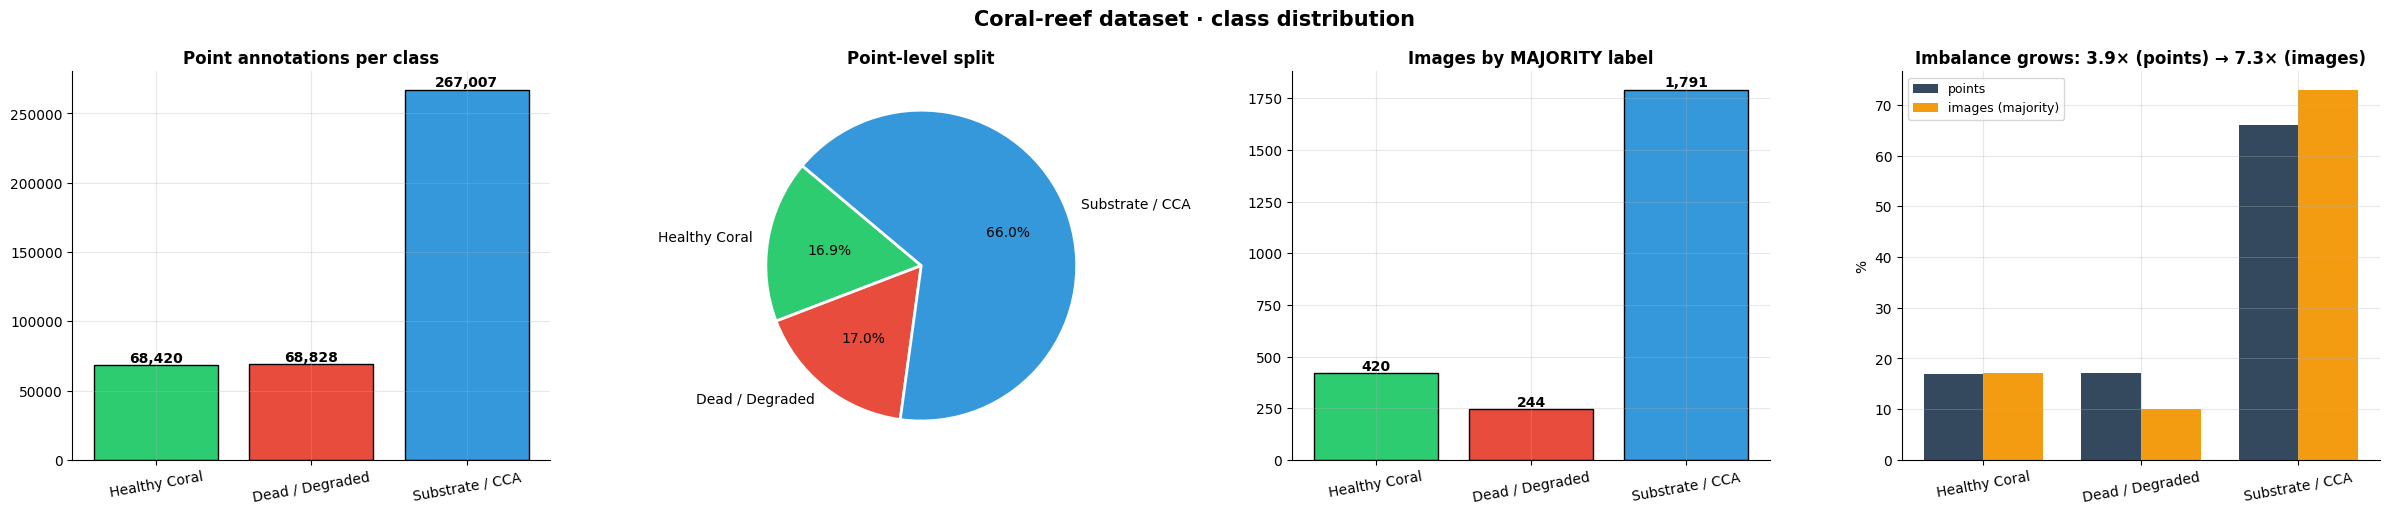


──────────────────────────────────────────────────────────────────────────────
EDA 2 · raw-label composition of each health class
──────────────────────────────────────────────────────────────────────────────


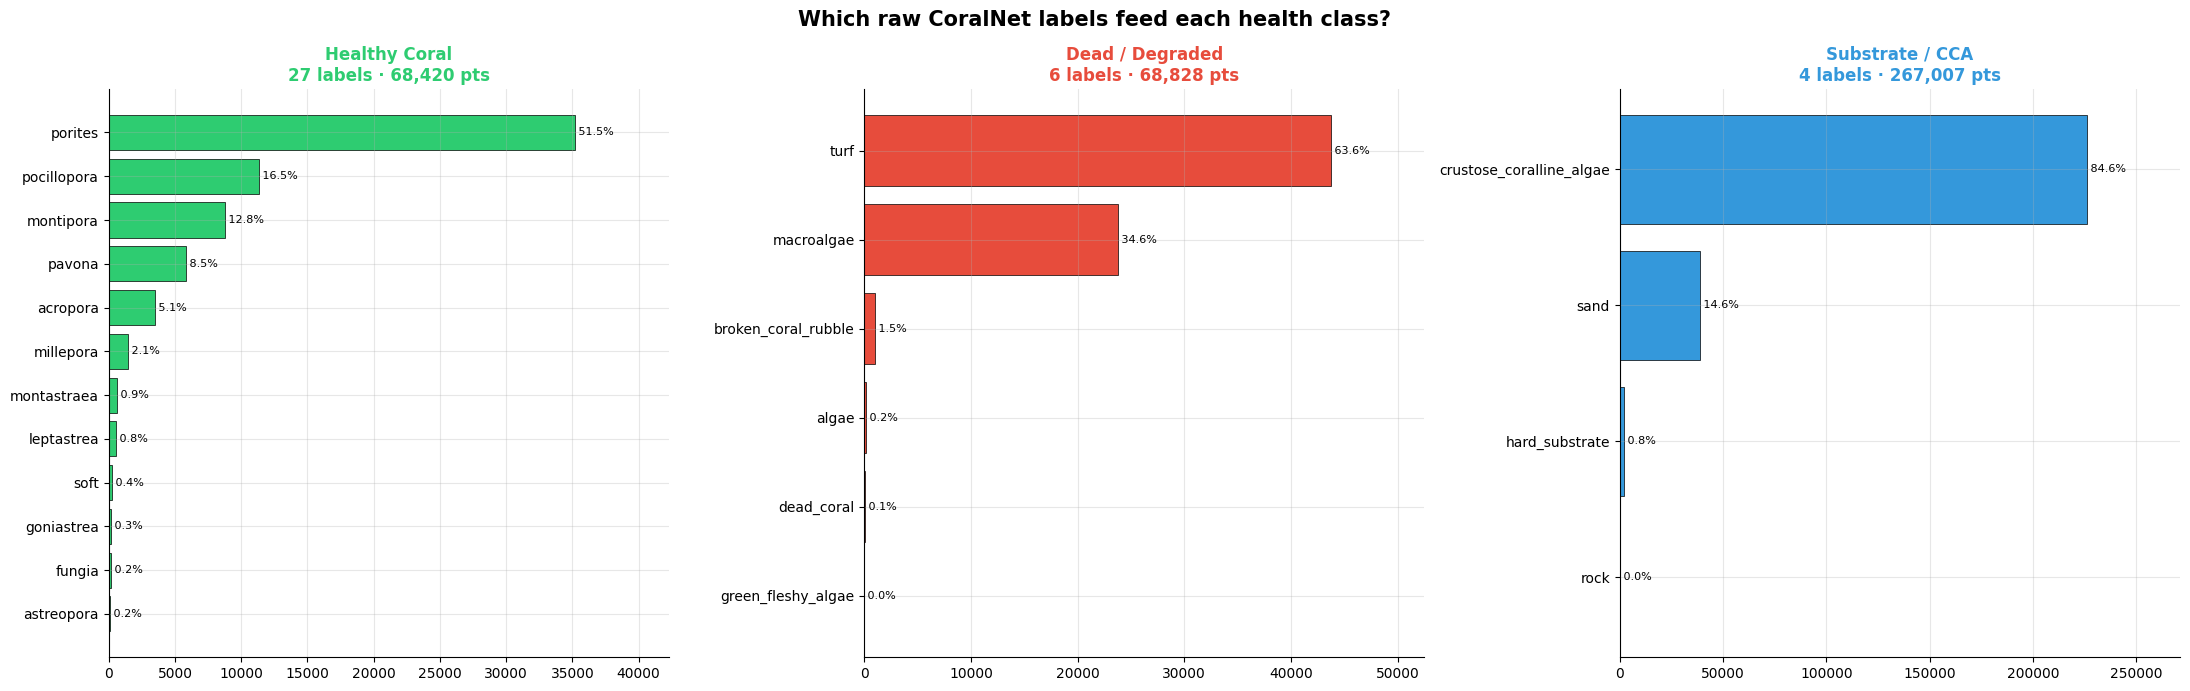


──────────────────────────────────────────────────────────────────────────────
EDA 3 · label purity – the case for point-centred crops
──────────────────────────────────────────────────────────────────────────────


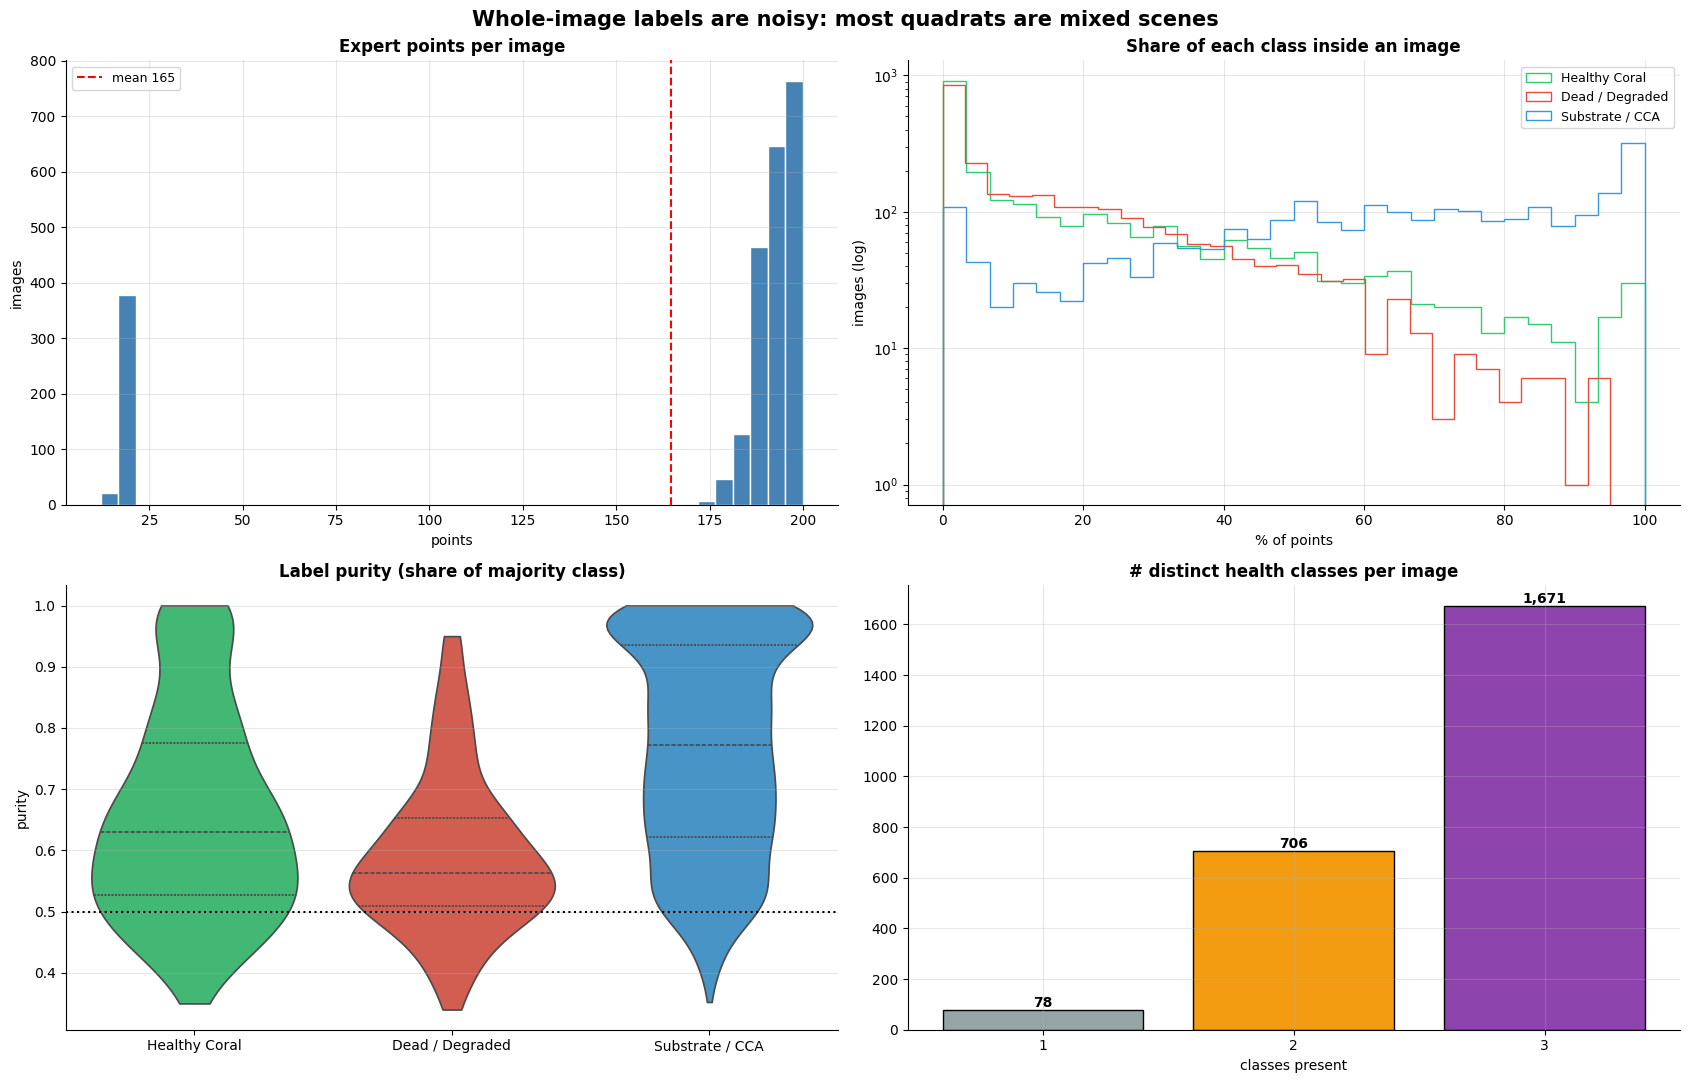

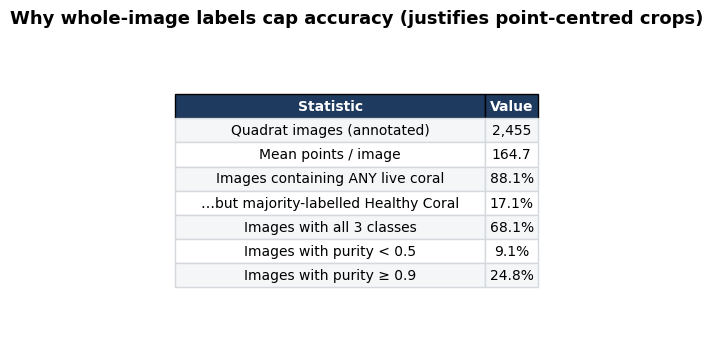


──────────────────────────────────────────────────────────────────────────────
EDA 4 · spatial layout of point annotations
──────────────────────────────────────────────────────────────────────────────


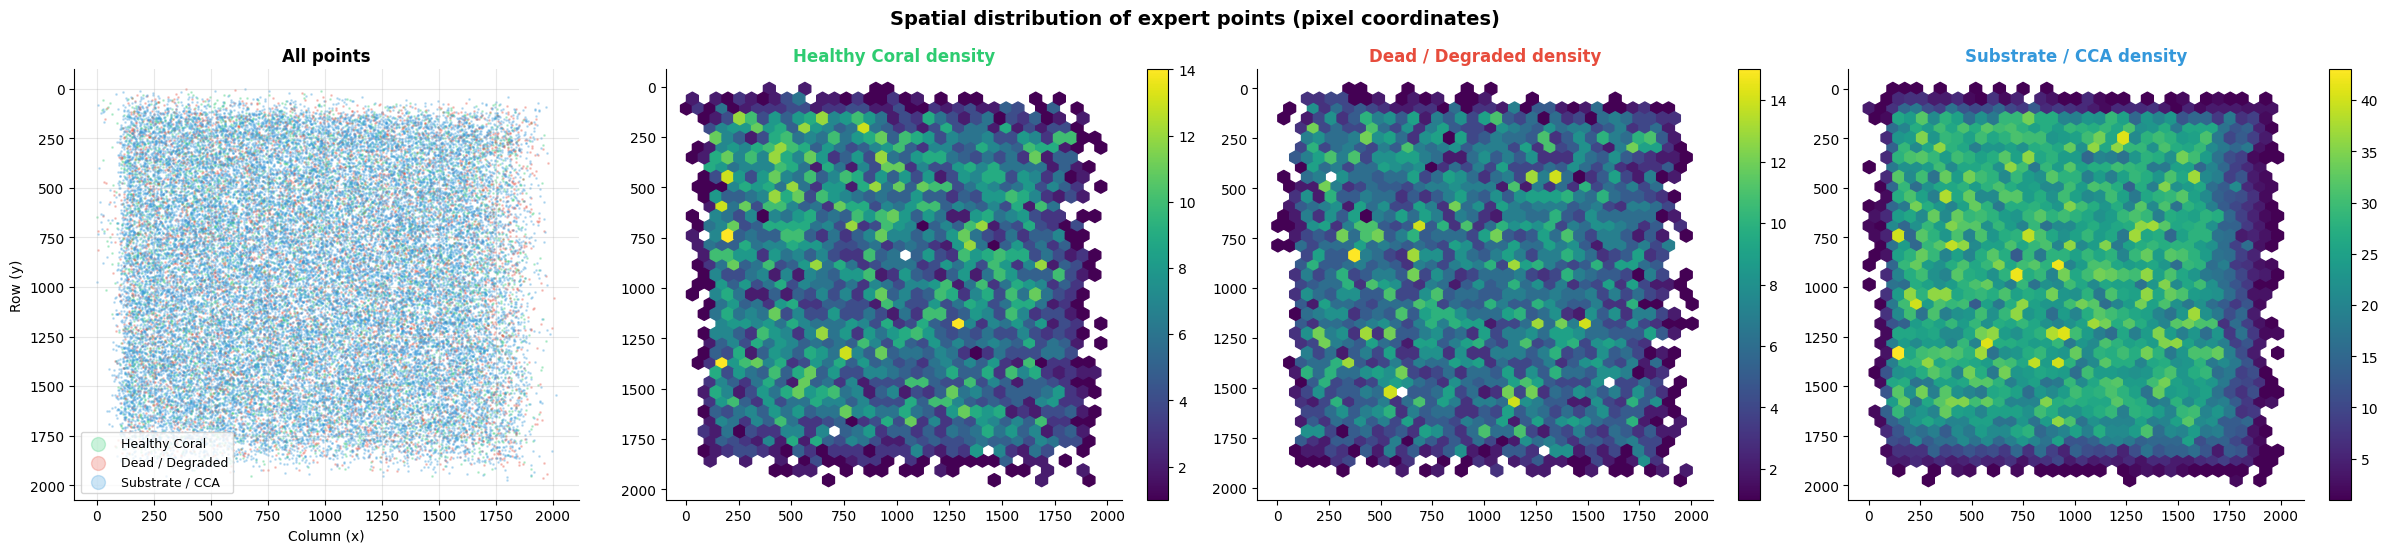


──────────────────────────────────────────────────────────────────────────────
EDA 5 · label co-occurrence
──────────────────────────────────────────────────────────────────────────────


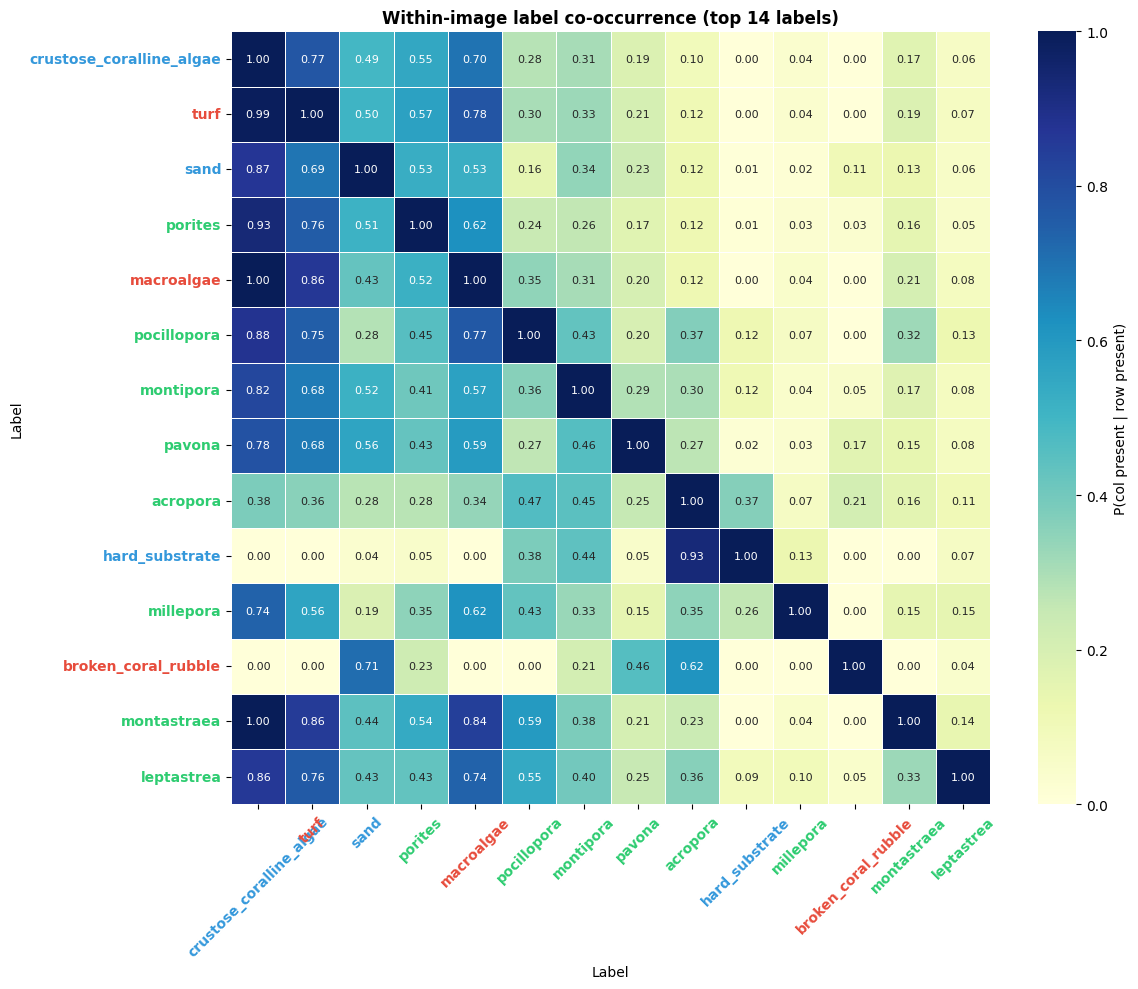

'/content/coral_final/figures/eda_05_cooccurrence.png'

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 5 · EDA (1/3) · POINT-LEVEL & IMAGE-LEVEL STATISTICS  → why point-centred crops?
# ═══════════════════════════════════════════════════════════════════════════
hdr('EDA 1 · class distribution (points vs images)')
vc_pts = df_clean['Health_Category'].value_counts().reindex(CLASS_NAMES)
comp_counts = pd.crosstab(df_clean['Name'], df_clean['Health_Category']).reindex(columns=CLASS_NAMES, fill_value=0)
comp_frac = comp_counts.div(comp_counts.sum(1), axis=0)
img_stats = pd.DataFrame({'n_points': comp_counts.sum(1), 'majority': comp_frac.idxmax(1), 'purity': comp_frac.max(1),
                          'coral_frac': comp_frac['Healthy Coral'], 'dead_frac': comp_frac['Dead / Degraded'],
                          'sub_frac': comp_frac['Substrate / CCA'], 'n_classes': (comp_counts > 0).sum(1)})
vc_img = img_stats['majority'].value_counts().reindex(CLASS_NAMES)

fig, ax = plt.subplots(1, 4, figsize=(24, 5.2))
fig.suptitle('Coral-reef dataset · class distribution', fontsize=15, fontweight='bold')
ax[0].bar(CLASS_NAMES, vc_pts.values, color=CLS_COL, edgecolor='black'); ax[0].set_title('Point annotations per class')
for i, v in enumerate(vc_pts.values): ax[0].text(i, v, f'{v:,}', ha='center', va='bottom', fontweight='bold')
ax[1].pie(vc_pts.values, labels=CLASS_NAMES, colors=CLS_COL, autopct='%1.1f%%', startangle=140, wedgeprops=dict(edgecolor='white', linewidth=2))
ax[1].set_title('Point-level split')
ax[2].bar(CLASS_NAMES, vc_img.values, color=CLS_COL, edgecolor='black'); ax[2].set_title('Images by MAJORITY label')
for i, v in enumerate(vc_img.values): ax[2].text(i, v, f'{v:,}', ha='center', va='bottom', fontweight='bold')
x = np.arange(3); w = 0.38
ax[3].bar(x - w/2, vc_pts.values / vc_pts.sum() * 100, w, label='points', color='#34495e')
ax[3].bar(x + w/2, vc_img.values / vc_img.sum() * 100, w, label='images (majority)', color='#f39c12')
ax[3].set_xticks(x); ax[3].set_xticklabels(CLASS_NAMES, rotation=10); ax[3].set_ylabel('%'); ax[3].legend()
ax[3].set_title(f'Imbalance grows: {vc_pts.max()/vc_pts.min():.1f}× (points) → {vc_img.max()/max(vc_img.min(),1):.1f}× (images)')
for a in ax[[0, 2]]: a.tick_params(axis='x', rotation=10)
plt.tight_layout(); save_fig(fig, 'eda_01_class_distribution')

hdr('EDA 2 · raw-label composition of each health class')
fig, axes = plt.subplots(1, 3, figsize=(22, 7))
fig.suptitle('Which raw CoralNet labels feed each health class?', fontsize=15, fontweight='bold')
for ax_, cat in zip(axes, CLASS_NAMES):
    labs = df_clean.loc[df_clean['Health_Category'] == cat, 'Label'].value_counts(); top = labs.head(12)
    ax_.barh(top.index[::-1], top.values[::-1], color=HEALTH_COLORS[cat], edgecolor='black', linewidth=0.5)
    for y, (v, s) in enumerate(zip(top.values[::-1], (top / labs.sum() * 100).values[::-1])): ax_.text(v, y, f' {s:.1f}%', va='center', fontsize=8)
    ax_.set_title(f'{cat}\n{len(labs)} labels · {labs.sum():,} pts', color=HEALTH_COLORS[cat]); ax_.set_xlim(0, top.max() * 1.2)
plt.tight_layout(); save_fig(fig, 'eda_02_label_composition')

hdr('EDA 3 · label purity – the case for point-centred crops')
fig, axes = plt.subplots(2, 2, figsize=(17, 11))
fig.suptitle('Whole-image labels are noisy: most quadrats are mixed scenes', fontsize=15, fontweight='bold')
ax = axes[0, 0]; ax.hist(img_stats['n_points'], bins=40, color='steelblue', edgecolor='white')
ax.axvline(img_stats['n_points'].mean(), color='red', ls='--', label=f"mean {img_stats['n_points'].mean():.0f}"); ax.legend()
ax.set_title('Expert points per image'); ax.set_xlabel('points'); ax.set_ylabel('images')
ax = axes[0, 1]
for col, cat in zip(['coral_frac', 'dead_frac', 'sub_frac'], CLASS_NAMES):
    ax.hist(img_stats[col] * 100, bins=30, histtype='step', lw=2.5, color=HEALTH_COLORS[cat], label=cat)
ax.set_yscale('log'); ax.set_title('Share of each class inside an image'); ax.set_xlabel('% of points'); ax.set_ylabel('images (log)'); ax.legend()
ax = axes[1, 0]
sns.violinplot(data=img_stats, x='majority', y='purity', hue='majority', order=CLASS_NAMES, hue_order=CLASS_NAMES, palette=HEALTH_COLORS,
               legend=False, ax=ax, cut=0, inner='quartile'); ax.axhline(0.5, color='k', ls=':')
ax.set_title('Label purity (share of majority class)'); ax.set_xlabel('')
ax = axes[1, 1]; nc = img_stats['n_classes'].value_counts().sort_index()
ax.bar(nc.index.astype(str), nc.values, color=['#95a5a6', '#f39c12', '#8e44ad'][:len(nc)], edgecolor='black')
for i, v in enumerate(nc.values): ax.text(i, v, f'{v:,}', ha='center', va='bottom', fontweight='bold')
ax.set_title('# distinct health classes per image'); ax.set_xlabel('classes present')
plt.tight_layout(); save_fig(fig, 'eda_03_label_purity')
purity_tbl = pd.DataFrame({
    'Statistic': ['Quadrat images (annotated)', 'Mean points / image', 'Images containing ANY live coral', '…but majority-labelled Healthy Coral',
                  'Images with all 3 classes', 'Images with purity < 0.5', 'Images with purity ≥ 0.9'],
    'Value': [f'{len(img_stats):,}', f"{img_stats['n_points'].mean():.1f}", f"{(img_stats['coral_frac']>0).mean()*100:.1f}%",
              f"{(img_stats['majority']=='Healthy Coral').mean()*100:.1f}%", f"{(img_stats['n_classes']==3).mean()*100:.1f}%",
              f"{(img_stats['purity']<0.5).mean()*100:.1f}%", f"{(img_stats['purity']>=0.9).mean()*100:.1f}%"]})
table_png(purity_tbl, 'table_01_label_purity', 'Why whole-image labels cap accuracy (justifies point-centred crops)')

hdr('EDA 4 · spatial layout of point annotations')
pts = df_clean.sample(min(40000, len(df_clean)), random_state=SEED)
fig, axes = plt.subplots(1, 4, figsize=(24, 5.6))
fig.suptitle('Spatial distribution of expert points (pixel coordinates)', fontsize=14, fontweight='bold')
for cat in CLASS_NAMES:
    s = pts[pts['Health_Category'] == cat]; axes[0].scatter(s['Column'], s['Row'], s=1, alpha=0.25, color=HEALTH_COLORS[cat], label=cat)
axes[0].invert_yaxis(); axes[0].legend(markerscale=10); axes[0].set_title('All points'); axes[0].set_xlabel('Column (x)'); axes[0].set_ylabel('Row (y)')
for a, cat in zip(axes[1:], CLASS_NAMES):
    s = pts[pts['Health_Category'] == cat]; hb = a.hexbin(s['Column'], s['Row'], gridsize=35, cmap='viridis', mincnt=1)
    a.invert_yaxis(); a.set_title(f'{cat} density', color=HEALTH_COLORS[cat]); plt.colorbar(hb, ax=a, fraction=0.046); a.grid(False)
plt.tight_layout(); save_fig(fig, 'eda_04_spatial_points')

hdr('EDA 5 · label co-occurrence')
top_lbls = df_clean['Label'].value_counts().head(14).index
pres = (pd.crosstab(df_clean['Name'], df_clean['Label'])[top_lbls] > 0).astype(int); co = pres.T @ pres; cond = co.div(np.diag(co), axis=0)
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(cond, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, linewidths=0.4, annot_kws={'size': 8}, ax=ax, cbar_kws={'label': 'P(col present | row present)'})
for t in ax.get_xticklabels() + ax.get_yticklabels(): t.set_color(HEALTH_COLORS[HEALTH_MAPPING[t.get_text()]]); t.set_fontweight('bold')
ax.set_title('Within-image label co-occurrence (top 14 labels)'); ax.tick_params(axis='x', rotation=45); ax.grid(False)
plt.tight_layout(); save_fig(fig, 'eda_05_cooccurrence')


## 6 · Underwater colour correction & point-centred crop demo (EDA 2/3)

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 6 · UNDERWATER FILTER + POINT-CENTRED CROP EXTRACTOR  (+ EDA 2/3)
# ═══════════════════════════════════════════════════════════════════════════
def load_rgb(path):
    try:
        with Image.open(path) as im: return np.asarray(im.convert('RGB'))
    except Exception:
        return None

def apply_underwater_filter(rgb, clip=1.5):
    """Gray-world white balance (per-channel LUT) + CLAHE on the LAB L-channel. uint8 RGB → uint8 RGB."""
    m = cv2.mean(rgb)[:3]; gray = sum(m) / 3.0
    out = np.empty_like(rgb)
    for c in range(3):
        g = float(np.clip(gray / (m[c] + 1e-6), 0.5, 2.5))
        lut = np.clip(np.arange(256) * g, 0, 255).astype(np.uint8)
        out[..., c] = cv2.LUT(np.ascontiguousarray(rgb[..., c]), lut)
    lab = cv2.cvtColor(out, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=clip, tileGridSize=(8, 8)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def pad_reflect(img): return cv2.copyMakeBorder(img, HALF, HALF, HALF, HALF, cv2.BORDER_REFLECT)
def crop_at(padded, row, col):             # padded image → CROP×CROP patch centred at original (row, col)
    return padded[row:row + CROP, col:col + CROP]

hdr('EDA 6 · underwater colour correction (before / after)')
_demo_name = tr_q['Name'].iloc[0]
raw_demo = load_rgb(os.path.join(IMAGES_DIR, _demo_name)); flt_demo = apply_underwater_filter(raw_demo)
fig = plt.figure(figsize=(18, 9)); gs = fig.add_gridspec(2, 4)
ax1 = fig.add_subplot(gs[0, :2]); ax1.imshow(raw_demo); ax1.set_title('Raw quadrat (blue-green attenuation)'); ax1.axis('off')
ax2 = fig.add_subplot(gs[0, 2:]); ax2.imshow(flt_demo); ax2.set_title('Gray-world WB + LAB-CLAHE', color='#27ae60'); ax2.axis('off')
for k, (im_, ttl) in enumerate(((raw_demo, 'Raw RGB histogram'), (flt_demo, 'Filtered RGB histogram'))):
    a = fig.add_subplot(gs[1, 2 * k:2 * k + 2])
    for ci, col in enumerate(('red', 'green', 'blue')):
        h, b = np.histogram(im_[..., ci], bins=50, range=(0, 256), density=True); a.plot(b[:-1], h, color=col, lw=2, label=col)
    a.set_title(ttl); a.set_xlabel('intensity'); a.legend()
plt.tight_layout(); save_fig(fig, 'eda_06_underwater_filter')

hdr('EDA 7 · whole quadrat → point-centred 224×224 crops')
_cand = df_clean[(df_clean['split'] == 'train')].groupby('Name')['Health_Category'].nunique()
_demo_q = (_cand[_cand == 3].index[0] if (_cand == 3).any() else _cand.index[0])
_q = df_clean[df_clean['Name'] == _demo_q]
_img = load_rgb(os.path.join(IMAGES_DIR, _demo_q)); _fimg = apply_underwater_filter(_img) if APPLY_FILTER else _img; _pad = pad_reflect(_fimg)
fig = plt.figure(figsize=(18, 11)); gs = fig.add_gridspec(2, 6, height_ratios=[2.3, 1])
ax = fig.add_subplot(gs[0, :]); ax.imshow(_fimg)
rng_ = np.random.RandomState(SEED); chosen = []
for cat in CLASS_NAMES:
    sub = _q[_q['Health_Category'] == cat]
    if len(sub): chosen += [sub.iloc[i] for i in rng_.choice(len(sub), size=min(2, len(sub)), replace=False)]
ax.scatter(_q['Column'], _q['Row'], s=10, c=_q['Health_Category'].map(HEALTH_COLORS), edgecolors='white', linewidths=0.4, alpha=0.8)
for r in chosen:
    ax.add_patch(mpatches.Rectangle((r['Column'] - HALF, r['Row'] - HALF), CROP, CROP, fill=False, ec=HEALTH_COLORS[r['Health_Category']], lw=2.5))
ax.set_title(f'{_demo_q} · {len(_q)} expert points · boxes = 224×224 crops'); ax.axis('off'); ax.grid(False)
ax.legend(handles=[mpatches.Patch(color=HEALTH_COLORS[c], label=c) for c in CLASS_NAMES], loc='lower right')
for j in range(6):
    a = fig.add_subplot(gs[1, j]); a.axis('off')
    if j < len(chosen):
        r = chosen[j]; a.imshow(crop_at(_pad, int(r['Row']), int(r['Column']))); a.plot(HALF, HALF, 'w+', ms=14, mew=2)
        a.set_title(f"{r['Label']}\n→ {r['Health_Category']}", fontsize=9, color=HEALTH_COLORS[r['Health_Category']], fontweight='bold')
plt.tight_layout(); save_fig(fig, 'eda_07_point_crop_demo')


This cell output is too large and can only be displayed while logged in.


## 7 · Build the crop cache
Each annotated quadrat is decoded and colour-corrected **once**; 224×224 crops (reflection-padded at the borders) are stored as `uint8` memory-maps. Unreadable images are dropped.

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 7 · BUILD THE CROP CACHE  (uint8 .npy memmaps; each quadrat is decoded + filtered exactly once)
# ═══════════════════════════════════════════════════════════════════════════
def balanced_sample(d, n_per_class):
    parts = []
    for cat in CLASS_NAMES:
        s = d[d['Health_Category'] == cat]
        parts.append(s.sample(n_per_class, replace=len(s) < n_per_class, random_state=SEED))
    return pd.concat(parts).sample(frac=1.0, random_state=SEED).reset_index(drop=True)

SPLIT_PTS = {
    'train': balanced_sample(train_df, P['train_pc']),                                         # class-balanced
    'val':   val_df.sample(min(P['val_n'],  len(val_df)),  random_state=SEED).reset_index(drop=True),   # natural distribution
    'test':  test_df.sample(min(P['test_n'], len(test_df)), random_state=SEED).reset_index(drop=True),  # natural distribution
}
CACHE_KEY = dict(profile=PROFILE, crop=CROP, filt=APPLY_FILTER, n={k: len(v) for k, v in SPLIT_PTS.items()}, seed=SEED, ds=os.path.basename(str(IMAGES_DIR)))
KEY_FILE = os.path.join(CACHE_DIR, 'cache_key.json')

def extract_split(split):
    pts = SPLIT_PTS[split]; N = len(pts)
    arr = np.lib.format.open_memmap(os.path.join(CACHE_DIR, f'{split}_x.npy'), mode='w+', dtype=np.uint8, shape=(N, CROP, CROP, 3))
    ok = np.zeros(N, dtype=bool); groups = pts.groupby('Name').indices
    rows, cols = pts['Row'].values, pts['Column'].values
    def work(item):
        name, idxs = item
        img = load_rgb(os.path.join(IMAGES_DIR, name))
        if img is None: return name, 0
        if APPLY_FILTER: img = apply_underwater_filter(img)
        H, W = img.shape[:2]; pad = pad_reflect(img)
        for i in idxs:
            arr[i] = crop_at(pad, int(np.clip(rows[i], 0, H - 1)), int(np.clip(cols[i], 0, W - 1))); ok[i] = True
        return name, len(idxs)
    bad = []
    with ThreadPoolExecutor(max_workers=min(8, 2 * (os.cpu_count() or 2))) as ex:
        for name, n in tqdm(ex.map(work, groups.items()), total=len(groups), desc=f'crops[{split}]', unit='img'):
            if n == 0: bad.append(name)
    arr.flush(); del arr
    return ok, bad

def compact_split(split, ok):
    """drop crops of unreadable images (rewrite the memmap compactly)"""
    pts = SPLIT_PTS[split]
    if ok.all(): return
    src = np.load(os.path.join(CACHE_DIR, f'{split}_x.npy'), mmap_mode='r'); keep = np.where(ok)[0]
    dst = np.lib.format.open_memmap(os.path.join(CACHE_DIR, f'{split}_x_c.npy'), mode='w+', dtype=np.uint8, shape=(len(keep), CROP, CROP, 3))
    for i in range(0, len(keep), 2000): dst[i:i + 2000] = src[keep[i:i + 2000]]
    dst.flush(); del dst, src
    os.replace(os.path.join(CACHE_DIR, f'{split}_x_c.npy'), os.path.join(CACHE_DIR, f'{split}_x.npy'))
    SPLIT_PTS[split] = pts[ok].reset_index(drop=True)

cache_ok = False
if os.path.exists(KEY_FILE):
    try: cache_ok = json.load(open(KEY_FILE)) == json.loads(json.dumps(CACHE_KEY)) and all(os.path.exists(os.path.join(CACHE_DIR, f'{s}_x.npy')) and os.path.exists(os.path.join(CACHE_DIR, f'{s}_meta.csv')) for s in SPLIT_PTS)
    except Exception: cache_ok = False
BAD_IMAGES = []
if cache_ok:
    print('✓ Re-using crop cache from', CACHE_DIR)
    for s in SPLIT_PTS: SPLIT_PTS[s] = pd.read_csv(os.path.join(CACHE_DIR, f'{s}_meta.csv'))
else:
    t0 = time.time()
    for s in ('train', 'val', 'test'):
        ok, bad = extract_split(s); BAD_IMAGES += bad
        n_drop = int((~ok).sum()); compact_split(s, ok)
        SPLIT_PTS[s].to_csv(os.path.join(CACHE_DIR, f'{s}_meta.csv'), index=False)
        print(f'  {s:5s}: {len(SPLIT_PTS[s]):6,} crops cached' + (f'  (dropped {n_drop} crops from {len(bad)} unreadable images)' if n_drop else ''))
    json.dump(CACHE_KEY, open(KEY_FILE, 'w')); print(f'Crop cache built in {(time.time()-t0)/60:.1f} min')
if BAD_IMAGES: print('Unreadable images skipped:', BAD_IMAGES[:5], '…' if len(BAD_IMAGES) > 5 else '')

DATA = {}
for s in ('train', 'val', 'test'):
    x = np.load(os.path.join(CACHE_DIR, f'{s}_x.npy'), mmap_mode='r')
    if s == 'train' and x.nbytes < 5.5e9: x = np.ascontiguousarray(x)          # keep train set in RAM (≤ 5.5 GB)
    meta = SPLIT_PTS[s]; assert len(meta) == len(x), f'{s}: meta/array length mismatch'
    DATA[s] = dict(x=x, y=meta['Health_Category'].map(CLASS_TO_IDX).values.astype(np.int64), meta=meta)
    print(f'{s:5s}: x{tuple(x.shape)} | class counts {np.bincount(DATA[s]["y"], minlength=3).tolist()}')


crops[train]:   0%|          | 0/1685 [00:00<?, ?img/s]

  train: 24,000 crops cached


crops[val]:   0%|          | 0/356 [00:00<?, ?img/s]

  val  :  5,000 crops cached


crops[test]:   0%|          | 0/366 [00:00<?, ?img/s]

  test :  6,000 crops cached
Crop cache built in 6.8 min
train: x(24000, 224, 224, 3) | class counts [8000, 8000, 8000]
val  : x(5000, 224, 224, 3) | class counts [885, 913, 3202]
test : x(6000, 224, 224, 3) | class counts [928, 1031, 4041]


## 8 · EDA (3/3) – the crop dataset

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 8 · EDA (3/3) · THE CROP DATASET  (before vs after balancing, samples, colour statistics, split summary)
# ═══════════════════════════════════════════════════════════════════════════
hdr('EDA 8 · before vs after point-crop balancing')
tr_nat = train_df['Health_Category'].value_counts().reindex(CLASS_NAMES)
tr_bal = pd.Series(np.bincount(DATA['train']['y'], minlength=3), index=CLASS_NAMES)
va_nat = pd.Series(np.bincount(DATA['val']['y'], minlength=3), index=CLASS_NAMES)
te_nat = pd.Series(np.bincount(DATA['test']['y'], minlength=3), index=CLASS_NAMES)
fig, ax = plt.subplots(1, 4, figsize=(24, 5))
fig.suptitle('Training crops are class-balanced; val / test keep the natural reef distribution', fontsize=14, fontweight='bold')
for a, s, ttl in zip(ax, (tr_nat, tr_bal, va_nat, te_nat), ('Train split – natural (all points)', 'Train crops – balanced (used for training)', 'Validation crops – natural', 'Test crops – natural')):
    a.bar(CLASS_NAMES, s.values, color=CLS_COL, edgecolor='black'); a.set_title(ttl, fontsize=11); a.tick_params(axis='x', rotation=10)
    for i, v in enumerate(s.values): a.text(i, v, f'{v:,}\n({v/s.sum()*100:.0f}%)', ha='center', va='bottom', fontsize=9, fontweight='bold')
    a.set_ylim(0, s.max() * 1.25)
plt.tight_layout(); save_fig(fig, 'eda_08_before_after_balancing')

hdr('EDA 9 · training-crop gallery')
fig, axes = plt.subplots(3, 10, figsize=(24, 8)); fig.suptitle('Point-centred 224×224 training crops (white + = expert point)', fontsize=14, fontweight='bold')
rs = np.random.RandomState(SEED)
for r_, cat in enumerate(CLASS_NAMES):
    ids = np.where(DATA['train']['y'] == r_)[0]; ids = rs.choice(ids, size=min(10, len(ids)), replace=False)
    for c_ in range(10):
        a = axes[r_, c_]; a.axis('off'); a.grid(False)
        if c_ < len(ids):
            a.imshow(DATA['train']['x'][ids[c_]]); a.plot(HALF, HALF, 'w+', ms=10, mew=1.5)
            a.set_title(DATA['train']['meta']['Label'].iloc[ids[c_]], fontsize=8, color=HEALTH_COLORS[cat], fontweight='bold')
    axes[r_, 0].text(-0.08, 0.5, cat, transform=axes[r_, 0].transAxes, rotation=90, va='center', ha='right', fontsize=12, fontweight='bold', color=HEALTH_COLORS[cat])
plt.tight_layout(); save_fig(fig, 'eda_09_crop_gallery')

hdr('EDA 10 · colour / texture statistics of the crops (class shortcuts?)')
rows = []
for r_ in range(3):
    ids = np.where(DATA['train']['y'] == r_)[0]; ids = np.random.RandomState(SEED).choice(ids, size=min(400, len(ids)), replace=False)
    for i in ids:
        a = DATA['train']['x'][i]; g = cv2.cvtColor(a, cv2.COLOR_RGB2GRAY).astype(np.float32); hsv = cv2.cvtColor(a, cv2.COLOR_RGB2HSV)
        lap = cv2.Laplacian(g, cv2.CV_32F).var(); m = a.reshape(-1, 3).mean(0)
        rows.append(dict(cls=CLASS_NAMES[r_], R=m[0], G=m[1], B=m[2], brightness=g.mean(), contrast=g.std(), saturation=hsv[..., 1].mean(),
                         sharpness=lap, blue_green=m[2] / (m[1] + 1e-6)))
prop = pd.DataFrame(rows)
fig, axes = plt.subplots(2, 4, figsize=(24, 10)); fig.suptitle('Crop property analysis by class', fontsize=15, fontweight='bold')
for a, col, ttl in zip(axes.flat[:6], ['brightness', 'contrast', 'saturation', 'sharpness', 'blue_green', 'G'],
                        ['Brightness (luma)', 'Contrast (luma std)', 'Saturation (HSV-S)', 'Sharpness (Laplacian var)', 'Blue / Green ratio', 'Mean green']):
    sns.violinplot(data=prop, x='cls', y=col, hue='cls', order=CLASS_NAMES, hue_order=CLASS_NAMES, palette=HEALTH_COLORS, legend=False, ax=a, cut=0, inner='quartile')
    a.set_title(ttl); a.set_xlabel(''); a.tick_params(axis='x', rotation=10)
ax = axes.flat[6]; rgb_m = prop.groupby('cls')[['R', 'G', 'B']].mean().reindex(CLASS_NAMES); xx = np.arange(3)
for k, (ch, c) in enumerate(zip('RGB', ['#c0392b', '#27ae60', '#2980b9'])): ax.bar(xx + (k - 1) * 0.26, rgb_m[ch], 0.26, color=c, edgecolor='black', label=ch)
ax.set_xticks(xx); ax.set_xticklabels(CLASS_NAMES, rotation=10); ax.set_title('Mean RGB per class'); ax.legend()
ax = axes.flat[7]; ax.axis('off'); ax.grid(False)
for k, r_ in enumerate(range(3)):
    ids = np.where(DATA['train']['y'] == r_)[0][:300]; mimg = DATA['train']['x'][ids].astype(np.float32).mean(0).astype(np.uint8)
    ins = ax.inset_axes([k / 3, 0.15, 0.31, 0.7]); ins.imshow(mimg); ins.axis('off'); ins.set_title(CLASS_NAMES[r_].split()[0], fontsize=9, color=CLS_COL[r_], fontweight='bold')
ax.set_title('Mean crop per class')
plt.tight_layout(); save_fig(fig, 'eda_10_crop_properties')
table_png(prop.groupby('cls').mean().reindex(CLASS_NAMES).round(2).reset_index().rename(columns={'cls': 'Class'}), 'table_02_crop_properties', 'Mean crop statistics per class (train crops)', fmt={c: '{:.2f}' for c in prop.columns if c != 'cls'})

hdr('EDA 11 · dataset & split summary')
split_tbl = pd.DataFrame({
    'Split': ['Train', 'Val', 'Test'],
    'Quadrat images': [len(tr_q), len(va_q), len(te_q)],
    'All valid points': [len(train_df), len(val_df), len(test_df)],
    'Crops used': [len(DATA[s]['y']) for s in ('train', 'val', 'test')],
    'Healthy': [int((DATA[s]['y'] == 0).sum()) for s in ('train', 'val', 'test')],
    'Dead/Degraded': [int((DATA[s]['y'] == 1).sum()) for s in ('train', 'val', 'test')],
    'Substrate/CCA': [int((DATA[s]['y'] == 2).sum()) for s in ('train', 'val', 'test')],
    'Distribution': ['balanced', 'natural', 'natural']})
table_png(split_tbl, 'table_03_split_summary', 'Grouped-by-image split (no quadrat appears in two splits)')
fig, ax = plt.subplots(figsize=(10, 5)); bottom = np.zeros(3)
for k, cat in enumerate(CLASS_NAMES):
    vals = split_tbl[['Healthy', 'Dead/Degraded', 'Substrate/CCA'][k]].values; ax.bar(split_tbl['Split'], vals, bottom=bottom, color=HEALTH_COLORS[cat], edgecolor='black', label=cat)
    for i, v in enumerate(vals): ax.text(i, bottom[i] + v / 2, f'{v:,}', ha='center', va='center', color='white', fontweight='bold')
    bottom += vals
ax.set_title('Crops per split and class'); ax.legend(); ax.set_ylabel('crops')
save_fig(fig, 'eda_11_split_distribution')


This cell output is too large and can only be displayed while logged in.


## 9 · GPU data pipeline
Colab has only 2 CPU cores – augmentation therefore runs **on the GPU** (dihedral flips/rot90, small affine with reflection padding, colour jitter).

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 9 · GPU DATA PIPELINE  (background-thread batch gather → augmentation on the GPU, zero CPU workers)
# ═══════════════════════════════════════════════════════════════════════════
class BatchLoader:
    """Yields (uint8 NCHW cuda tensor, int64 labels). Batches are gathered from the cached array by a prefetch thread."""
    def __init__(self, x, y, bs, shuffle=False, drop_last=False, prefetch=4, seed=0):
        self.x, self.y, self.bs, self.shuffle, self.drop_last, self.prefetch = x, y, bs, shuffle, drop_last, prefetch
        self.rng = np.random.RandomState(seed)
    def __len__(self):
        n = len(self.y); return n // self.bs if self.drop_last else math.ceil(n / self.bs)
    def __iter__(self):
        n = len(self.y); idx = self.rng.permutation(n) if self.shuffle else np.arange(n)
        batches = [idx[i:i + self.bs] for i in range(0, n, self.bs)]
        if self.drop_last and len(batches[-1]) < self.bs: batches = batches[:-1]
        q = queue.Queue(maxsize=self.prefetch)
        def producer():
            for b in batches:
                b = np.sort(b)
                xb = torch.from_numpy(np.ascontiguousarray(self.x[b])); yb = torch.from_numpy(self.y[b])
                q.put((xb.pin_memory() if DEVICE.type == 'cuda' else xb, yb))
            q.put(None)
        threading.Thread(target=producer, daemon=True).start()
        while True:
            item = q.get()
            if item is None: break
            xb, yb = item
            yield xb.to(DEVICE, non_blocking=True).permute(0, 3, 1, 2), yb.to(DEVICE, non_blocking=True)

@torch.no_grad()
def gpu_augment(xb):
    """uint8 NCHW → float [0,1] NCHW with dihedral flips/rot90, small affine (reflect-padded) and colour jitter. Benthic imagery is
    orientation-invariant, so rotations / flips are label-preserving; the point label sits at the crop centre → only small shifts."""
    B = xb.shape[0]; dev = xb.device
    x = xb.float().div_(255.0)
    x = torch.where((torch.rand(B, device=dev) < 0.5).view(B, 1, 1, 1), x.flip(3), x)
    x = torch.where((torch.rand(B, device=dev) < 0.5).view(B, 1, 1, 1), x.flip(2), x)
    k = torch.randint(0, 4, (B,), device=dev)
    for kk in (1, 2, 3):
        m = k == kk
        if m.any(): x[m] = torch.rot90(x[m], kk, dims=(2, 3))
    ang = (torch.rand(B, device=dev) * 2 - 1) * math.radians(20); sc = 1 + (torch.rand(B, device=dev) * 2 - 1) * 0.15
    tx = (torch.rand(B, device=dev) * 2 - 1) * 0.06; ty = (torch.rand(B, device=dev) * 2 - 1) * 0.06
    c, s = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([c, -s, tx], 1), torch.stack([s, c, ty], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, list(x.shape), align_corners=False), mode='bilinear', padding_mode='reflection', align_corners=False)
    u = lambda lo, hi: (torch.rand(B, 1, 1, 1, device=dev) * (hi - lo) + lo)
    x = x * u(0.8, 1.2)                                                           # brightness
    mean = x.mean(dim=(1, 2, 3), keepdim=True); x = (x - mean) * u(0.8, 1.2) + mean  # contrast
    gray = (0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]); x = (x - gray) * u(0.8, 1.25) + gray  # saturation
    x = x * (1 + (torch.rand(B, 3, 1, 1, device=dev) * 2 - 1) * 0.05)           # per-channel gain (colour cast)
    return x.clamp_(0, 1)

# preview
_ids = np.random.RandomState(1).choice(len(DATA['train']['y']), 6, replace=False)
_xb = torch.from_numpy(DATA['train']['x'][np.sort(_ids)]).to(DEVICE).permute(0, 3, 1, 2)
fig, axes = plt.subplots(4, 6, figsize=(18, 12.5)); fig.suptitle('GPU augmentation preview (row 1 original · rows 2-4 three random augmentations)', fontsize=14, fontweight='bold')
for j in range(6):
    axes[0, j].imshow(_xb[j].permute(1, 2, 0).cpu().numpy()); axes[0, j].set_title('original', fontsize=9)
for r_ in range(1, 4):
    aug = gpu_augment(_xb).permute(0, 2, 3, 1).cpu().numpy()
    for j in range(6): axes[r_, j].imshow(aug[j])
for a in axes.flat: a.axis('off'); a.grid(False)
plt.tight_layout(); save_fig(fig, 'eda_12_augmentation_preview'); del _xb


This cell output is too large and can only be displayed while logged in.


## 10 · Model zoo
MobileNetV2 · ResNet18 · EfficientNet-B0 · ShuffleNetV2 (ImageNet) · CoralCNN-SE (random init) · DINOv2 ViT-S/14 (self-supervised, top-4 blocks fine-tuned).

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 10 · MODEL ZOO  (4 transfer-learning CNNs · SE-ResNet from scratch · DINOv2 ViT-S/14)
#      The source is kept as a string so it is ALSO written to coral_model_defs.py (needed to reload the saved weights).
# ═══════════════════════════════════════════════════════════════════════════
MODEL_DEFS_SRC = r'''
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision.models as tvm

CLASS_NAMES = ['Healthy Coral', 'Dead / Degraded', 'Substrate / CCA']
IMAGENET_MEAN = (0.485, 0.456, 0.406); IMAGENET_STD = (0.229, 0.224, 0.225)
TL_NAMES = ['MobileNetV2', 'ResNet18', 'EfficientNet-B0', 'ShuffleNetV2']
MODEL_ORDER = TL_NAMES + ['CoralCNN-SE', 'DINOv2-ViT-S/14']

class NormWrap(nn.Module):
    """Input: RGB float tensor in [0,1].  Normalisation (mean/std buffers) is part of the model → weights are self-contained."""
    def __init__(self, net, mean, std, channels_last=False):
        super().__init__()
        self.net = net
        self.register_buffer('mean', torch.tensor(list(mean), dtype=torch.float32).view(1, 3, 1, 1))
        self.register_buffer('std',  torch.tensor(list(std),  dtype=torch.float32).view(1, 3, 1, 1))
        self.channels_last = channels_last
    def forward(self, x):
        x = (x - self.mean) / self.std
        if self.channels_last: x = x.contiguous(memory_format=torch.channels_last)
        return self.net(x)

# ───────────────────────── CNN from scratch: residual + Squeeze-Excitation ─────────────────────────
class ConvBNAct(nn.Sequential):
    def __init__(self, cin, cout, k=3, s=1):
        super().__init__(nn.Conv2d(cin, cout, k, s, k // 2, bias=False), nn.BatchNorm2d(cout), nn.SiLU())
class SEBlock(nn.Module):
    def __init__(self, c, r=8):
        super().__init__()
        self.fc = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(c, c // r, 1), nn.SiLU(), nn.Conv2d(c // r, c, 1), nn.Sigmoid())
    def forward(self, x): return x * self.fc(x)
class ResBlock(nn.Module):
    def __init__(self, cin, cout, stride=1, drop_path=0.0):
        super().__init__()
        self.conv1 = ConvBNAct(cin, cout, 3, stride)
        self.conv2 = nn.Sequential(nn.Conv2d(cout, cout, 3, 1, 1, bias=False), nn.BatchNorm2d(cout))
        self.se = SEBlock(cout)
        self.short = nn.Identity() if (cin == cout and stride == 1) else nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
        self.act = nn.SiLU(); self.drop_path = drop_path
    def forward(self, x):
        out = self.se(self.conv2(self.conv1(x)))
        if self.training and self.drop_path > 0:                      # stochastic depth
            keep = (torch.rand(x.shape[0], 1, 1, 1, device=x.device) >= self.drop_path).to(out.dtype)
            out = out * keep / (1 - self.drop_path)
        return self.act(out + self.short(x))
class CoralCNN(nn.Module):
    def __init__(self, num_classes=3, widths=(32, 64, 128, 192, 256), depths=(1, 2, 2, 2), dropout=0.3, drop_path=0.1):
        super().__init__()
        self.stem = nn.Sequential(ConvBNAct(3, widths[0] // 2, 3, 2), ConvBNAct(widths[0] // 2, widths[0], 3, 1))
        stages, cin = [], widths[0]
        for i, (cout, d) in enumerate(zip(widths[1:], depths)):
            blocks = [ResBlock(cin, cout, stride=2, drop_path=drop_path * i / 3)] + [ResBlock(cout, cout, 1, drop_path=drop_path * i / 3) for _ in range(d - 1)]
            stages.append(nn.Sequential(*blocks)); cin = cout
        self.stage1, self.stage2, self.stage3, self.stage4 = stages
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(cin, num_classes))
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d): nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear): nn.init.normal_(m.weight, 0, 0.01); nn.init.zeros_(m.bias)
        for m in self.modules():
            if isinstance(m, ResBlock): nn.init.zeros_(m.conv2[1].weight)
    def forward(self, x): return self.head(self.stage4(self.stage3(self.stage2(self.stage1(self.stem(x))))))

# ───────────────────────── Transfer learning backbones ─────────────────────────
def build_tl(name, n=3, pretrained=True):
    W = lambda enum: (enum.DEFAULT if pretrained else None)
    if name == 'MobileNetV2':
        m = tvm.mobilenet_v2(weights=W(tvm.MobileNet_V2_Weights)); m.classifier = nn.Sequential(nn.Dropout(0.2), nn.Linear(m.last_channel, n))
    elif name == 'ResNet18':
        m = tvm.resnet18(weights=W(tvm.ResNet18_Weights)); m.fc = nn.Sequential(nn.Dropout(0.2), nn.Linear(m.fc.in_features, n))
    elif name == 'EfficientNet-B0':
        m = tvm.efficientnet_b0(weights=W(tvm.EfficientNet_B0_Weights)); m.classifier = nn.Sequential(nn.Dropout(0.2), nn.Linear(m.classifier[1].in_features, n))
    elif name == 'ShuffleNetV2':
        m = tvm.shufflenet_v2_x1_0(weights=W(tvm.ShuffleNet_V2_X1_0_Weights)); m.fc = nn.Sequential(nn.Dropout(0.2), nn.Linear(m.fc.in_features, n))
    else:
        raise ValueError(name)
    return m

# ───────────────────────── DINOv2 ViT-S/14 (multi-layer pooled, partially unfrozen) ─────────────────────────
def load_dinov2_backbone(pretrained=True):
    try:
        return torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14', pretrained=pretrained, trust_repo=True), 'hub'
    except Exception as e:                                   # offline GitHub / hub cache problems → timm mirror of the same weights
        print('torch.hub DINOv2 failed (%s) → falling back to timm' % repr(e)[:100])
        import timm
        return timm.create_model('vit_small_patch14_dinov2.lvd142m', pretrained=pretrained, num_classes=0, img_size=224), 'timm'

class DINOv2Classifier(nn.Module):
    """Mean-pooled patch tokens of the last `n_pool` transformer blocks (4×384 = 1536-d) → MLP head. Top `unfreeze` blocks are fine-tuned."""
    def __init__(self, num_classes=3, n_pool=4, dropout=0.2, pretrained=True, unfreeze=4):
        super().__init__()
        self.backbone, self.kind = load_dinov2_backbone(pretrained)
        self.n_pool = n_pool; dim = self.backbone.embed_dim
        for p in self.backbone.parameters(): p.requires_grad = False
        if unfreeze > 0:
            for blk in list(self.backbone.blocks)[-unfreeze:]:
                for p in blk.parameters(): p.requires_grad = True
            for p in self.backbone.norm.parameters(): p.requires_grad = True
        self.head = nn.Sequential(nn.Linear(dim * n_pool, 256), nn.LayerNorm(256), nn.GELU(), nn.Dropout(dropout), nn.Linear(256, num_classes))
    def tokens(self, x):
        kw = {'norm': True} if self.kind == 'timm' else {}
        return self.backbone.get_intermediate_layers(x, n=self.n_pool, **kw)       # list of (B, 256, 384) patch-token maps
    def forward(self, x): return self.head(torch.cat([t.mean(1) for t in self.tokens(x)], dim=-1))

def build_model(name, pretrained=True, mean=(0.46, 0.54, 0.51), std=(0.22, 0.21, 0.21), unfreeze=4):
    """Returns a NormWrap model: input RGB in [0,1], output logits (B,3)."""
    if name in TL_NAMES:
        return NormWrap(build_tl(name, 3, pretrained), IMAGENET_MEAN, IMAGENET_STD, channels_last=True).to(memory_format=torch.channels_last)
    if name == 'CoralCNN-SE':
        return NormWrap(CoralCNN(3), mean, std, channels_last=True).to(memory_format=torch.channels_last)
    if name == 'DINOv2-ViT-S/14':
        return NormWrap(DINOv2Classifier(3, pretrained=pretrained, unfreeze=unfreeze), IMAGENET_MEAN, IMAGENET_STD, channels_last=False)
    raise ValueError(name)
'''
exec(MODEL_DEFS_SRC, globals())
open(os.path.join(OUT_DIR, 'coral_model_defs.py'), 'w').write(MODEL_DEFS_SRC)

FAMILY = {**{n: 'Transfer learning' for n in TL_NAMES}, 'CoralCNN-SE': 'CNN from scratch', 'DINOv2-ViT-S/14': 'Vision Transformer'}
MODEL_COL = dict(zip(MODEL_ORDER, ['#e67e22', '#d35400', '#f5b041', '#ba4a00', '#8e44ad', '#16a085']))
EP = P['ep']
# per-model recipes (AdamW + OneCycle; lr_bb = backbone / whole net, lr_head = classifier head)
MODEL_CFG = {
  'MobileNetV2':      dict(epochs=EP['TL'],  lr_bb=4e-4,  lr_head=2e-3,   wd=1e-2, patience=5, head='net.classifier'),
  'ResNet18':         dict(epochs=EP['TL'],  lr_bb=3e-4,  lr_head=1.5e-3, wd=1e-2, patience=5, head='net.fc'),
  'EfficientNet-B0':  dict(epochs=EP['TL'],  lr_bb=4e-4,  lr_head=2e-3,   wd=1e-2, patience=5, head='net.classifier'),
  'ShuffleNetV2':     dict(epochs=EP['TL'],  lr_bb=5e-4,  lr_head=2e-3,   wd=1e-2, patience=5, head='net.fc'),
  'CoralCNN-SE':      dict(epochs=EP['CNN'], lr_bb=2e-3,  lr_head=2e-3,   wd=2e-2, patience=12, head=None),
  'DINOv2-ViT-S/14':  dict(epochs=EP['ViT'], lr_bb=1.5e-5, lr_head=1e-3,  wd=5e-2, patience=4, head='net.head', unfreeze=4),
}
for c in MODEL_CFG.values(): c.update(bs=P['bs'], label_smoothing=0.1, clip=5.0, warmup_pct=0.2)

# dataset statistics for the scratch CNN (no ImageNet prior → use the train crops' own mean/std)
_ids = np.random.RandomState(SEED).choice(len(DATA['train']['y']), min(3000, len(DATA['train']['y'])), replace=False)
_s = DATA['train']['x'][np.sort(_ids)].astype(np.float32) / 255.0
DATA_MEAN, DATA_STD = _s.mean((0, 1, 2)).tolist(), _s.std((0, 1, 2)).tolist(); del _s
print('Crop mean/std (scratch CNN):', np.round(DATA_MEAN, 4), np.round(DATA_STD, 4), '| ImageNet:', IMAGENET_MEAN, IMAGENET_STD)

def new_model(name):
    return build_model(name, pretrained=PRETRAINED, mean=DATA_MEAN, std=DATA_STD, unfreeze=MODEL_CFG[name].get('unfreeze', 4)).to(DEVICE)

spec = []
for n_ in MODEL_ORDER:
    m_ = new_model(n_); tot = sum(p.numel() for p in m_.parameters()); trn = sum(p.numel() for p in m_.parameters() if p.requires_grad)
    spec.append(dict(Model=n_, Family=FAMILY[n_], Pretrained='ImageNet' if (n_ in TL_NAMES and PRETRAINED) else ('DINOv2 (LVD-142M)' if (n_.startswith('DINO') and PRETRAINED) else 'none (random init)'),
                     **{'Params (M)': tot / 1e6, 'Trainable (M)': trn / 1e6}))
    del m_
display(pd.DataFrame(spec))
if DEVICE.type == 'cuda': torch.cuda.empty_cache()


Crop mean/std (scratch CNN): [0.1115 0.1115 0.1115] [0.3338 0.3338 0.3338] | ImageNet: (0.485, 0.456, 0.406) (0.229, 0.224, 0.225)
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 190MB/s]


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 214MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 196MB/s]


Downloading: "https://download.pytorch.org/models/shufflenetv2_x1-5666bf0f80.pth" to /root/.cache/torch/hub/checkpoints/shufflenetv2_x1-5666bf0f80.pth


100%|██████████| 8.79M/8.79M [00:00<00:00, 69.6MB/s]


Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 259MB/s]


,Model,Family,Pretrained,Params (M),Trainable (M)
0,MobileNetV2,Transfer learning,ImageNet,2.227715,2.227715
1,ResNet18,Transfer learning,ImageNet,11.178051,11.178051
2,EfficientNet-B0,Transfer learning,ImageNet,4.011391,4.011391
3,ShuffleNetV2,Transfer learning,ImageNet,1.256679,1.256679
4,CoralCNN-SE,CNN from scratch,none (random init),4.157547,4.157547
5,DINOv2-ViT-S/14,Vision Transformer,DINOv2 (LVD-142M),22.451331,7.496451


## 11 · Train all six models
AdamW + OneCycle, label smoothing, AMP, gradient clipping; checkpoint = best **validation macro-F1**; early stopping; finished models are cached so a re-run skips them.

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 11 · TRAINING ENGINE  (AMP · OneCycle · label smoothing · best-checkpoint on val macro-F1 · early stopping · resumable)
# ═══════════════════════════════════════════════════════════════════════════
@torch.no_grad()
def infer_logits(model, x_arr, bs=256, tta=False):
    """uint8 NHWC array → logits (N,3) as numpy. With tta=True returns log of the 4-fold (id/h/v/hv flip) averaged probabilities."""
    model.eval(); out = []
    for i in range(0, len(x_arr), bs):
        xb = torch.from_numpy(np.ascontiguousarray(x_arr[i:i + bs])).to(DEVICE).permute(0, 3, 1, 2).float().div_(255.0)
        with torch.autocast(device_type=DEVICE.type, enabled=AMP):
            if tta:
                p = sum(torch.softmax(model(v).float(), 1) for v in (xb, xb.flip(3), xb.flip(2), xb.flip(2).flip(3))) / 4.0
                out.append(torch.log(p.clamp_min(1e-8)).cpu())
            else:
                out.append(model(xb).float().cpu())
    return torch.cat(out).numpy()

def softmax_np(z): z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

def eval_loss_acc_f1(model, split):
    z = infer_logits(model, DATA[split]['x']); y = DATA[split]['y']
    loss = F.cross_entropy(torch.from_numpy(z), torch.from_numpy(y)).item(); pr = z.argmax(1)
    return loss, accuracy_score(y, pr), f1_score(y, pr, average='macro')

def make_optim(model, cfg, total_steps):
    groups = {}
    for n_, p in model.named_parameters():
        if not p.requires_grad: continue
        is_head = cfg['head'] is not None and n_.startswith(cfg['head'])
        groups.setdefault((is_head, p.ndim > 1), []).append(p)
    pg, max_lrs = [], []
    for (is_head, decay), ps in groups.items():
        lr = cfg['lr_head'] if is_head else cfg['lr_bb']
        pg.append(dict(params=ps, lr=lr, weight_decay=cfg['wd'] if decay else 0.0)); max_lrs.append(lr)
    opt = torch.optim.AdamW(pg)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=max_lrs, total_steps=total_steps, pct_start=cfg['warmup_pct'],
                                                anneal_strategy='cos', div_factor=25, final_div_factor=1e3, cycle_momentum=False)
    return opt, sched

def ckpt_path(name): return os.path.join(MOD_DIR, safe(name) + '.pt')

def train_model(name):
    cfg = MODEL_CFG[name]; model = new_model(name); path = ckpt_path(name)
    n_params = sum(p.numel() for p in model.parameters())
    if os.path.exists(path) and not FORCE_RETRAIN:
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
        if ck.get('history', {}).get('finished') and ck.get('profile') == PROFILE:
            model.load_state_dict(ck['state_dict']); model.eval()
            print(f'✓ {name}: loaded finished checkpoint (best epoch {ck["history"]["best_epoch"]}, val F1 {ck["history"]["best_val_f1"]:.4f}) – skipping training')
            return model, ck['history']
    tr = DATA['train']; loader = BatchLoader(tr['x'], tr['y'], cfg['bs'], shuffle=True, drop_last=True, seed=SEED)
    steps = len(loader) * cfg['epochs']; opt, sched = make_optim(model, cfg, steps)
    scaler = torch.amp.GradScaler('cuda', enabled=AMP); crit = nn.CrossEntropyLoss(label_smoothing=cfg['label_smoothing'])
    H = dict(epoch=[], train_loss=[], train_acc=[], val_loss=[], val_acc=[], val_f1=[], lr=[], time_s=[])
    best_f1, best_ep, best_state, bad = -1.0, 0, None, 0
    print(f'\n{"═"*92}\n  {name}  [{FAMILY[name]}] · {n_params/1e6:.2f} M params · {cfg["epochs"]} epochs × {len(loader)} steps · bs {cfg["bs"]} · lr {cfg["lr_bb"]:.1e}/{cfg["lr_head"]:.1e}\n{"═"*92}')
    t_start = time.time()
    for ep in range(1, cfg['epochs'] + 1):
        t0 = time.time(); model.train(); tl = tc = tn = 0; lr_sum = 0.0
        for xb, yb in loader:
            x = gpu_augment(xb); opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=AMP):
                out = model(x); loss = crit(out.float(), yb)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), cfg['clip']); scaler.step(opt); scaler.update(); sched.step()
            lr_sum += opt.param_groups[0]['lr']
            tl += loss.item() * len(yb); tc += (out.argmax(1) == yb).sum().item(); tn += len(yb)
        lr_now = lr_sum / len(loader)                         # mean backbone LR over the epoch
        vl, va, vf = eval_loss_acc_f1(model, 'val')
        for k, v in zip(H, (ep, tl / tn, tc / tn, vl, va, vf, lr_now, time.time() - t0)): H[k].append(float(v))
        star = ''
        if vf > best_f1:
            best_f1, best_ep, bad = vf, ep, 0; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}; star = ' ★'
        else: bad += 1
        print(f'  ep {ep:02d}/{cfg["epochs"]} | train loss {tl/tn:.4f} acc {tc/tn*100:5.1f}% | val loss {vl:.4f} acc {va*100:5.1f}% macro-F1 {vf:.4f} | lr {lr_now:.1e} | {time.time()-t0:4.0f}s{star}')
        if bad >= cfg['patience']: print(f'  early stop (no val-F1 gain for {cfg["patience"]} epochs)'); break
    model.load_state_dict(best_state); model.eval()
    H.update(best_epoch=best_ep, best_val_f1=best_f1, train_time_s=time.time() - t_start, finished=True, params=n_params, epochs_run=len(H['epoch']))
    torch.save(dict(name=name, state_dict={k: v.cpu() for k, v in model.state_dict().items()}, history=H, cfg=cfg, class_names=CLASS_NAMES, profile=PROFILE,
                    data_mean=DATA_MEAN, data_std=DATA_STD), path)
    jdump(H, os.path.join(LOG_DIR, safe(name) + '_history.json'))
    print(f'  ► best epoch {best_ep} · val macro-F1 {best_f1:.4f} · total {H["train_time_s"]/60:.1f} min · saved {os.path.basename(path)}')
    return model, H

MODELS, HIST = {}, {}
for name in MODEL_ORDER:
    MODELS[name], HIST[name] = train_model(name)
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
print('\n✅ All models trained.')



════════════════════════════════════════════════════════════════════════════════════════════
  MobileNetV2  [Transfer learning] · 2.23 M params · 12 epochs × 375 steps · bs 64 · lr 4.0e-04/2.0e-03
════════════════════════════════════════════════════════════════════════════════════════════
  ep 01/12 | train loss 0.8331 acc  67.7% | val loss 0.6248 acc  74.5% macro-F1 0.6969 | lr 6.7e-05 |   50s ★
  ep 02/12 | train loss 0.6730 acc  77.8% | val loss 0.6146 acc  75.2% macro-F1 0.7148 | lr 2.8e-04 |   44s ★
  ep 03/12 | train loss 0.6260 acc  80.8% | val loss 0.5294 acc  78.9% macro-F1 0.7585 | lr 4.0e-04 |   46s ★
  ep 04/12 | train loss 0.6016 acc  82.0% | val loss 0.4650 acc  81.7% macro-F1 0.7744 | lr 3.9e-04 |   45s ★
  ep 05/12 | train loss 0.5811 acc  83.6% | val loss 0.4823 acc  81.3% macro-F1 0.7705 | lr 3.5e-04 |   45s
  ep 06/12 | train loss 0.5636 acc  84.2% | val loss 0.4710 acc  81.0% macro-F1 0.7579 | lr 3.0e-04 |   45s
  ep 07/12 | train loss 0.5454 acc  85.3% | val loss 

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main



════════════════════════════════════════════════════════════════════════════════════════════
  DINOv2-ViT-S/14  [Vision Transformer] · 22.45 M params · 10 epochs × 375 steps · bs 64 · lr 1.5e-05/1.0e-03
════════════════════════════════════════════════════════════════════════════════════════════
  ep 01/10 | train loss 0.7327 acc  73.5% | val loss 0.5341 acc  78.6% macro-F1 0.7496 | lr 3.2e-06 |   70s ★
  ep 02/10 | train loss 0.6234 acc  80.8% | val loss 0.4639 acc  80.7% macro-F1 0.7798 | lr 1.2e-05 |   70s ★
  ep 03/10 | train loss 0.5771 acc  83.4% | val loss 0.5189 acc  78.2% macro-F1 0.7733 | lr 1.5e-05 |   69s
  ep 04/10 | train loss 0.5483 acc  84.7% | val loss 0.4512 acc  82.7% macro-F1 0.7973 | lr 1.4e-05 |   70s ★
  ep 05/10 | train loss 0.5290 acc  86.1% | val loss 0.4801 acc  80.3% macro-F1 0.7888 | lr 1.2e-05 |   70s
  ep 06/10 | train loss 0.5137 acc  87.2% | val loss 0.4093 acc  83.1% macro-F1 0.8094 | lr 8.9e-06 |   69s ★
  ep 07/10 | train loss 0.4978 acc  87.9% | val

## 12 · Training curves & per-epoch tables

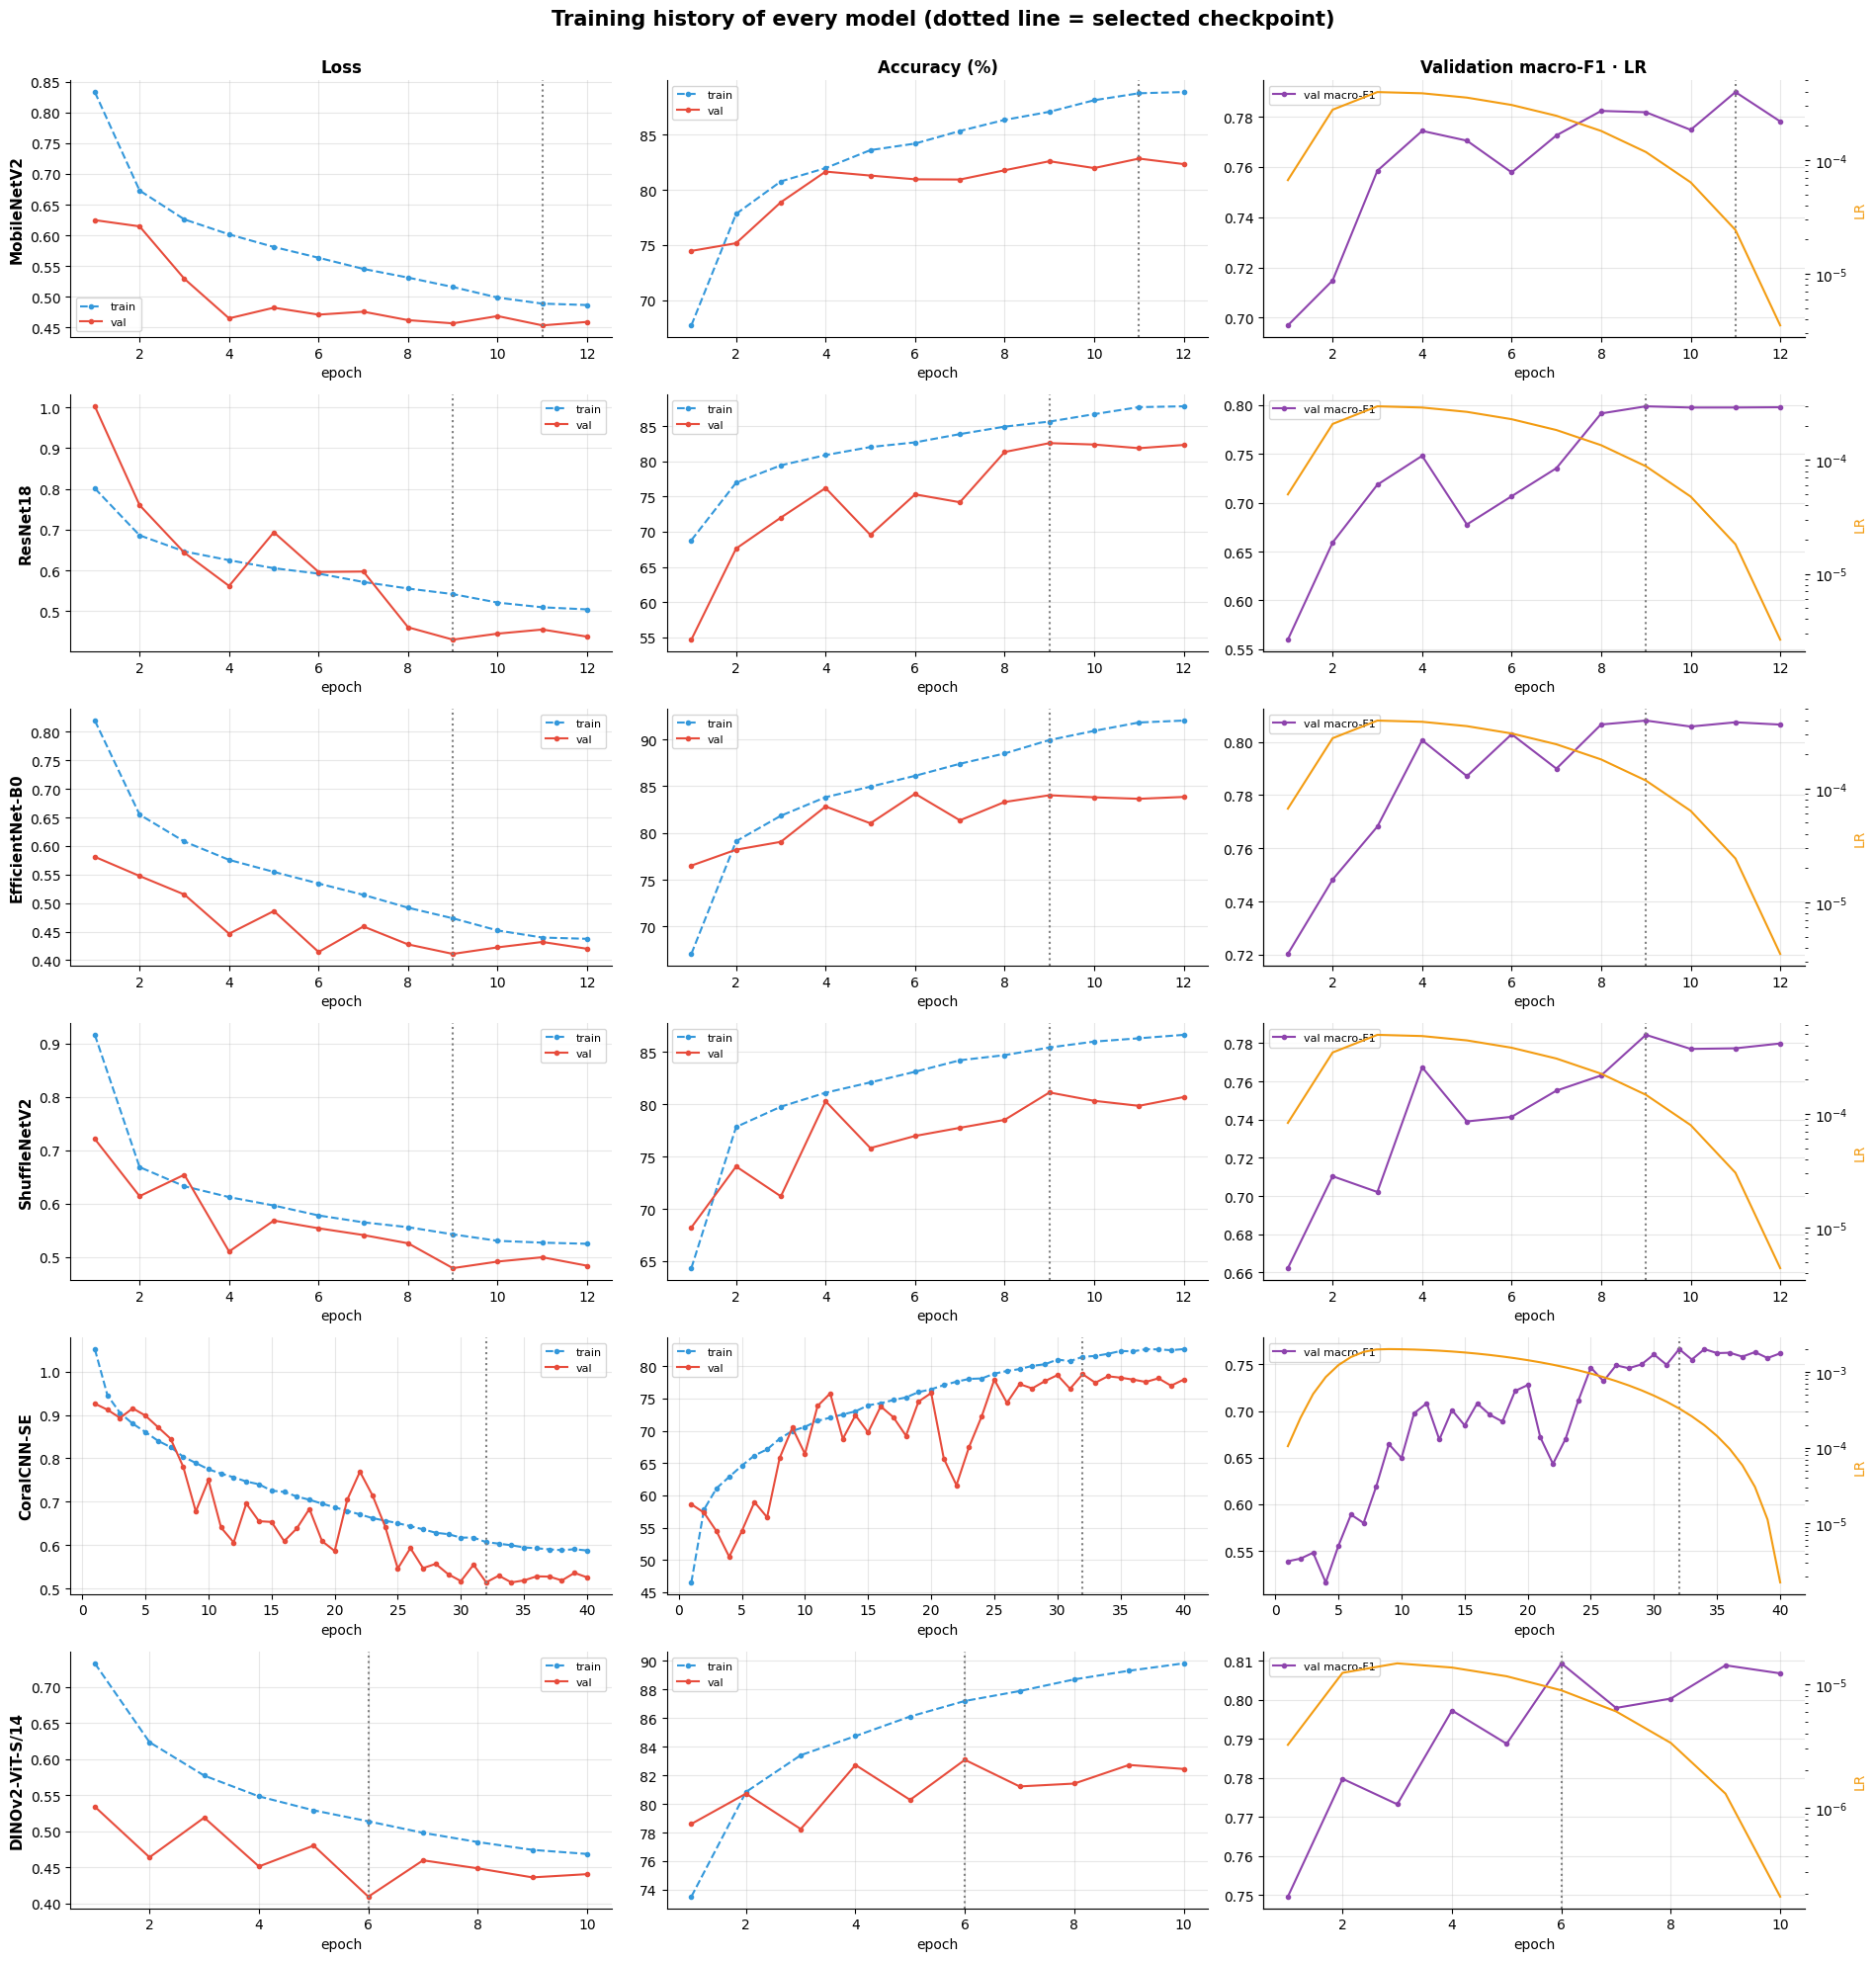

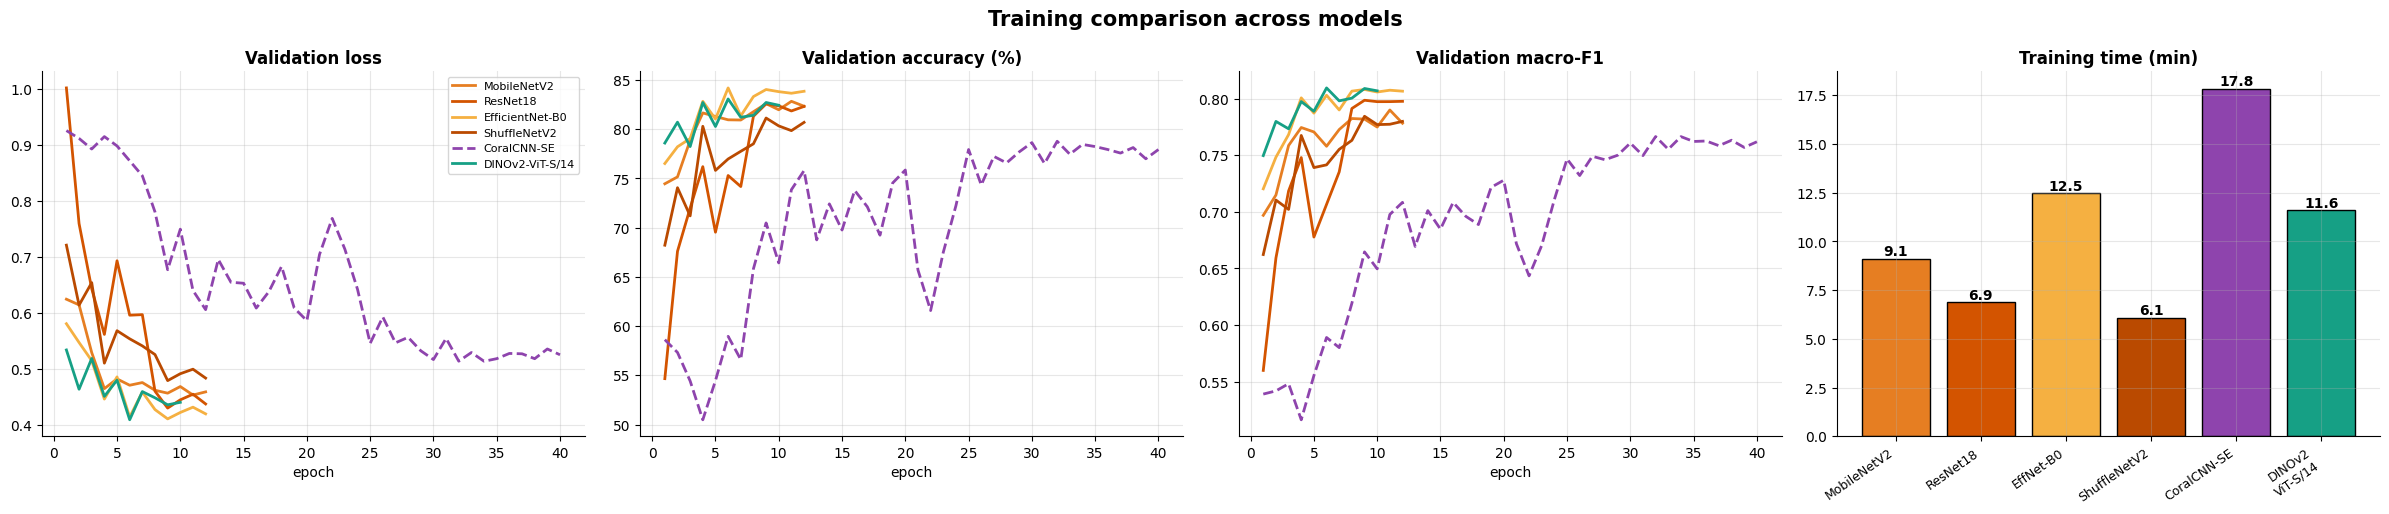


──────────────────────────────────────────────────────────────────────────────
Training summary table
──────────────────────────────────────────────────────────────────────────────


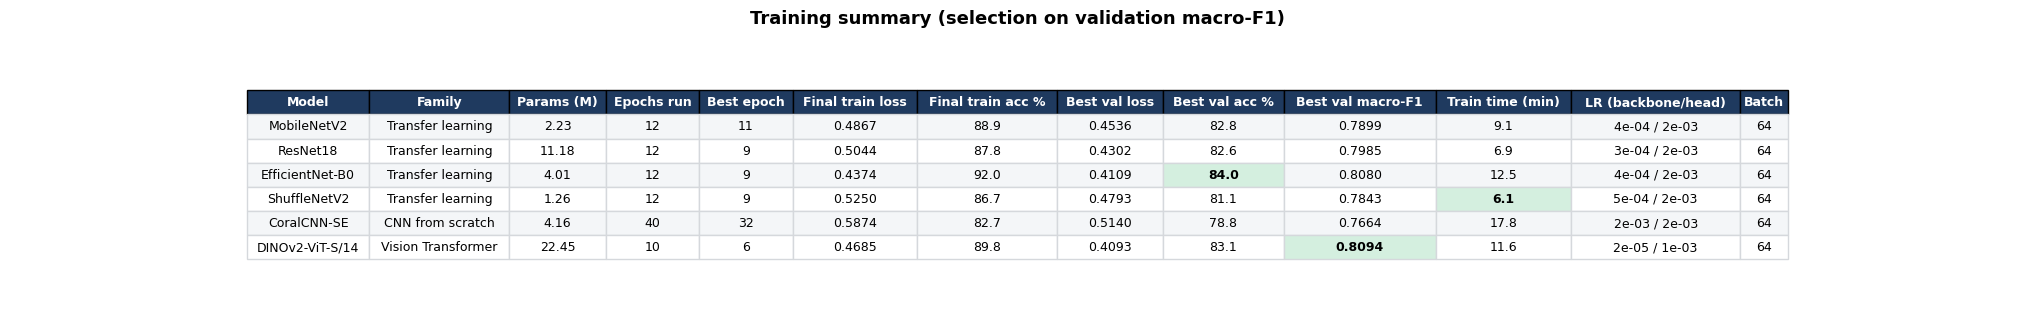

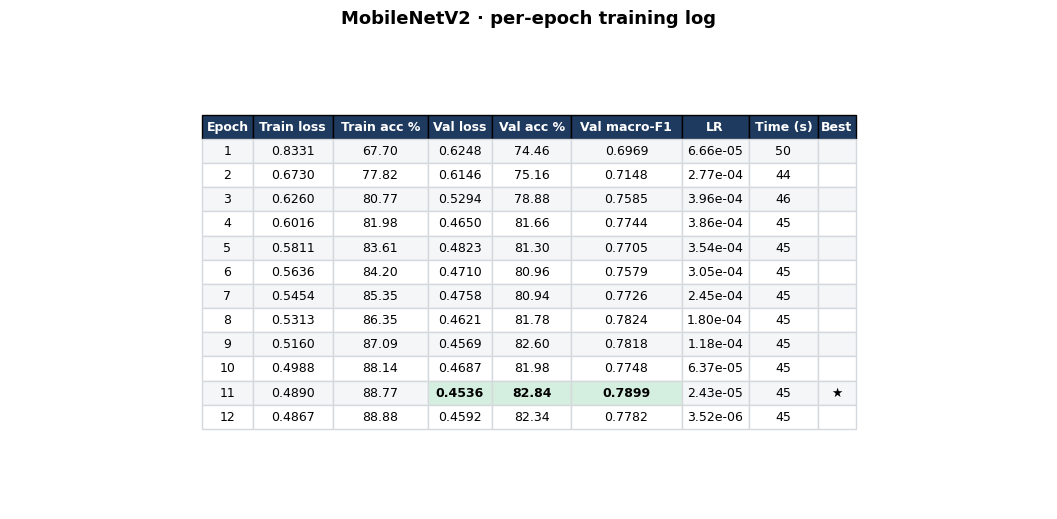

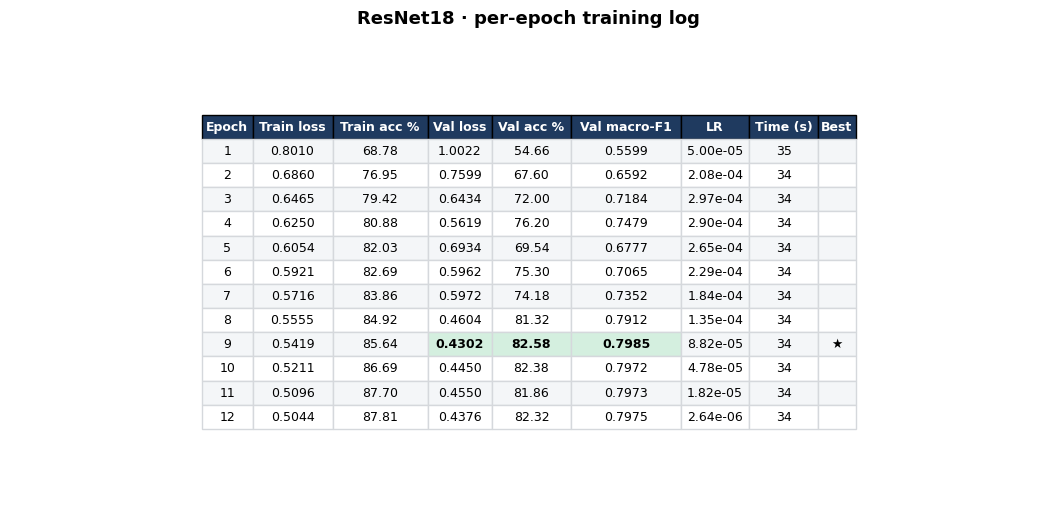

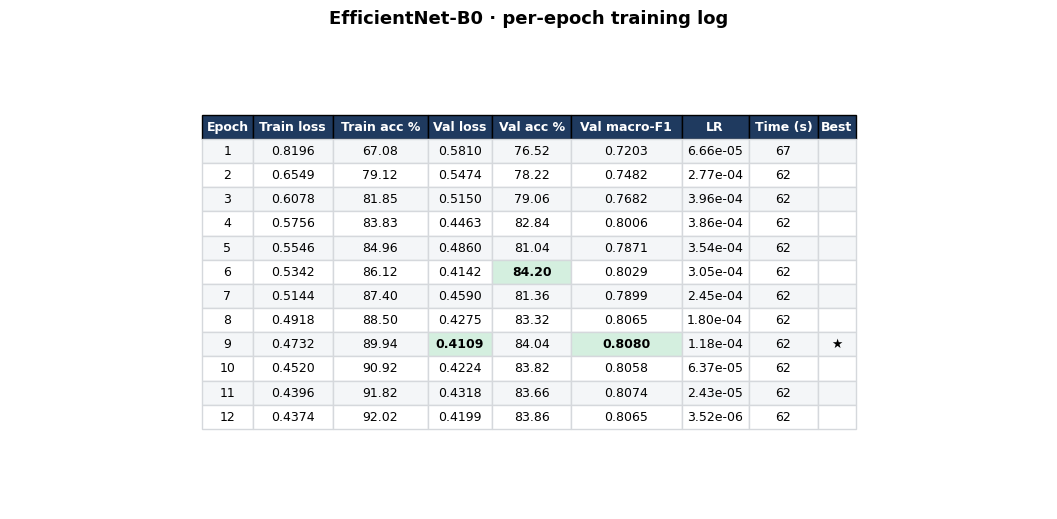

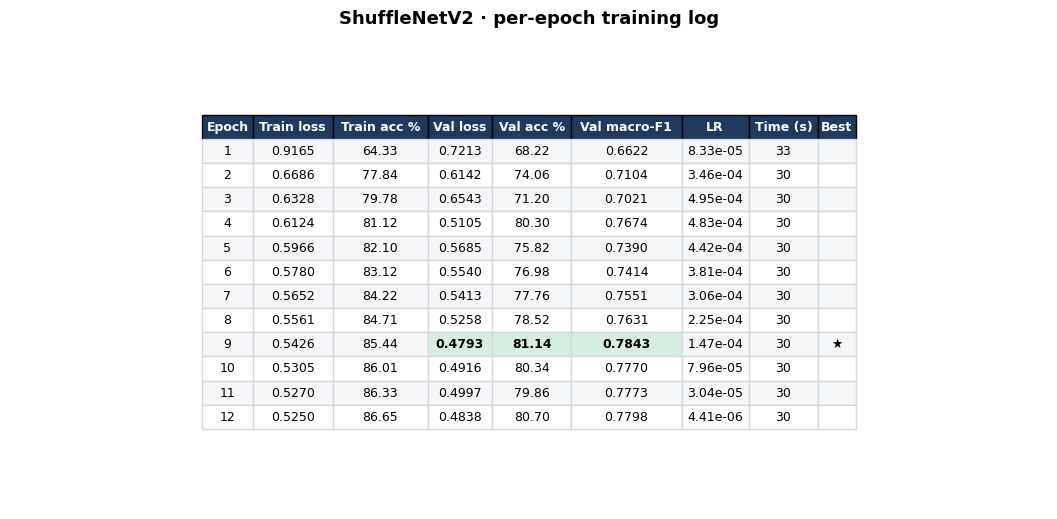

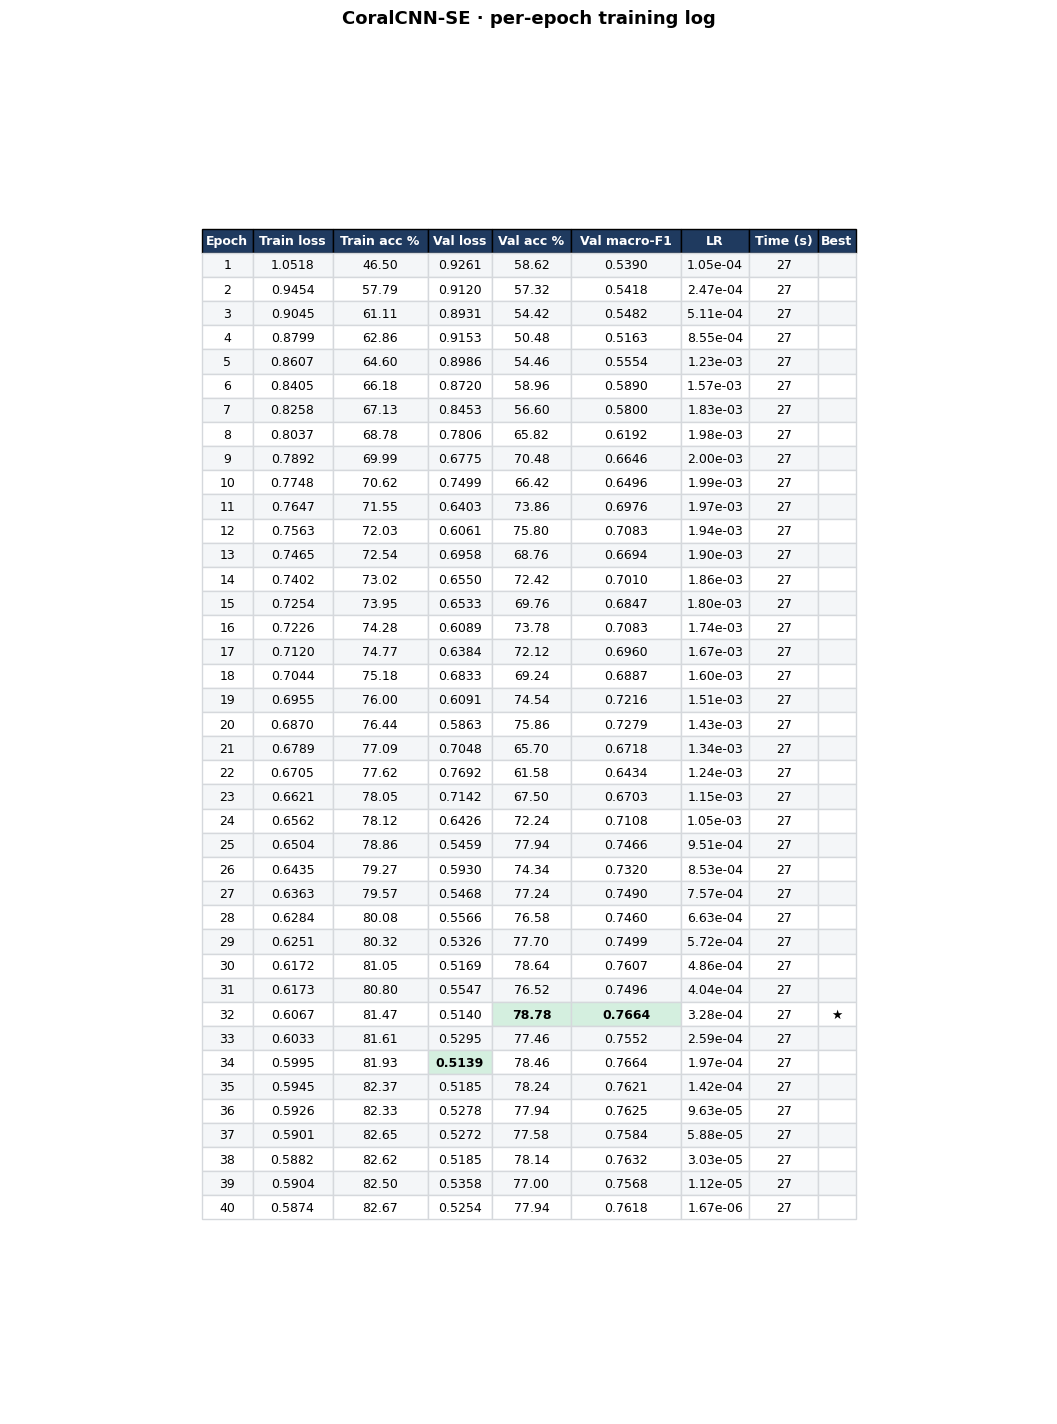

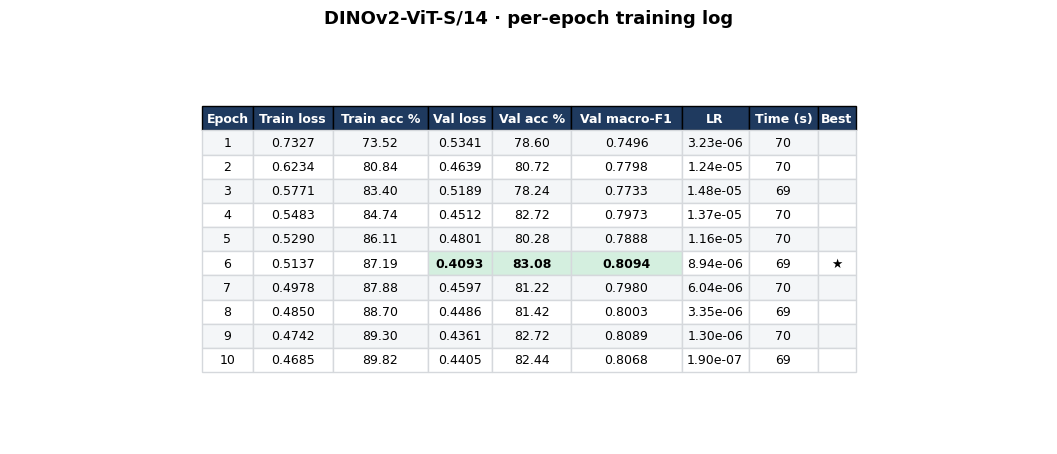

Per-epoch logs saved → /content/coral_final/logs/training_log_all_models.csv


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 12 · TRAINING REPORT · curves + per-epoch tables (all saved as PNG/CSV for the report)
# ═══════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(len(MODEL_ORDER), 3, figsize=(19, 3.3 * len(MODEL_ORDER)))
fig.suptitle('Training history of every model (dotted line = selected checkpoint)', fontsize=15, fontweight='bold', y=1.0)
for r_, name in enumerate(MODEL_ORDER):
    h = HIST[name]; ep = h['epoch']; be = h['best_epoch']
    a = axes[r_, 0]; a.plot(ep, h['train_loss'], '--o', ms=3, color='#3498db', label='train'); a.plot(ep, h['val_loss'], '-o', ms=3, color='#e74c3c', label='val'); a.set_ylabel(name, fontweight='bold', fontsize=11)
    a.set_title('Loss' if r_ == 0 else '');
    a = axes[r_, 1]; a.plot(ep, np.array(h['train_acc']) * 100, '--o', ms=3, color='#3498db', label='train'); a.plot(ep, np.array(h['val_acc']) * 100, '-o', ms=3, color='#e74c3c', label='val')
    a.set_title('Accuracy (%)' if r_ == 0 else '')
    a = axes[r_, 2]; a.plot(ep, h['val_f1'], '-o', ms=3, color='#8e44ad', label='val macro-F1'); a.set_title('Validation macro-F1 · LR' if r_ == 0 else '')
    a2 = a.twinx(); a2.plot(ep, h['lr'], color='#f39c12', lw=1.5, label='LR'); a2.set_yscale('log'); a2.grid(False); a2.set_ylabel('LR', color='#f39c12')
    for a in axes[r_]: a.axvline(be, color='gray', ls=':'); a.set_xlabel('epoch'); a.legend(loc='best', fontsize=8)
plt.tight_layout(); save_fig(fig, 'train_01_curves_per_model')

fig, ax = plt.subplots(1, 4, figsize=(24, 5.2)); fig.suptitle('Training comparison across models', fontsize=15, fontweight='bold')
for name in MODEL_ORDER:
    h = HIST[name]; ls = '-' if FAMILY[name] != 'CNN from scratch' else '--'
    ax[0].plot(h['epoch'], h['val_loss'], ls, lw=2, color=MODEL_COL[name], label=name); ax[1].plot(h['epoch'], np.array(h['val_acc']) * 100, ls, lw=2, color=MODEL_COL[name])
    ax[2].plot(h['epoch'], h['val_f1'], ls, lw=2, color=MODEL_COL[name])
for a, t in zip(ax[:3], ('Validation loss', 'Validation accuracy (%)', 'Validation macro-F1')): a.set_title(t); a.set_xlabel('epoch')
ax[0].legend(fontsize=8)
tmin = [HIST[n]['train_time_s'] / 60 for n in MODEL_ORDER]
bars = ax[3].bar(range(len(MODEL_ORDER)), tmin, color=[MODEL_COL[n] for n in MODEL_ORDER], edgecolor='black'); ax[3].set_xticks(range(len(MODEL_ORDER)))
ax[3].set_xticklabels([n.replace('DINOv2-ViT-S/14', 'DINOv2\nViT-S/14').replace('EfficientNet-B0', 'EffNet-B0') for n in MODEL_ORDER], rotation=35, ha='right', fontsize=9)
for b, t in zip(bars, tmin): ax[3].text(b.get_x() + b.get_width() / 2, t, f'{t:.1f}', ha='center', va='bottom', fontweight='bold')
ax[3].set_title('Training time (min)')
plt.tight_layout(); save_fig(fig, 'train_02_comparison')

hdr('Training summary table')
train_tbl = pd.DataFrame([dict(Model=n, Family=FAMILY[n], **{'Params (M)': HIST[n]['params'] / 1e6, 'Epochs run': HIST[n]['epochs_run'], 'Best epoch': HIST[n]['best_epoch'],
    'Final train loss': HIST[n]['train_loss'][-1], 'Final train acc %': HIST[n]['train_acc'][-1] * 100, 'Best val loss': HIST[n]['val_loss'][HIST[n]['best_epoch'] - 1] if HIST[n]['best_epoch'] <= len(HIST[n]['val_loss']) else np.nan,
    'Best val acc %': HIST[n]['val_acc'][HIST[n]['best_epoch'] - 1] * 100, 'Best val macro-F1': HIST[n]['best_val_f1'], 'Train time (min)': HIST[n]['train_time_s'] / 60,
    'LR (backbone/head)': f"{MODEL_CFG[n]['lr_bb']:.0e} / {MODEL_CFG[n]['lr_head']:.0e}", 'Batch': MODEL_CFG[n]['bs']}) for n in MODEL_ORDER])
table_png(train_tbl, 'table_04_training_summary', 'Training summary (selection on validation macro-F1)', fmt={'Params (M)': '{:.2f}', 'Final train loss': '{:.4f}', 'Final train acc %': '{:.1f}', 'Best val loss': '{:.4f}',
          'Best val acc %': '{:.1f}', 'Best val macro-F1': '{:.4f}', 'Train time (min)': '{:.1f}'}, best_max=['Best val acc %', 'Best val macro-F1'], best_min=['Train time (min)'], font=9)

all_logs = []
for name in MODEL_ORDER:
    h = HIST[name]
    df_e = pd.DataFrame({'Epoch': [int(e) for e in h['epoch']], 'Train loss': h['train_loss'], 'Train acc %': np.array(h['train_acc']) * 100, 'Val loss': h['val_loss'],
                         'Val acc %': np.array(h['val_acc']) * 100, 'Val macro-F1': h['val_f1'], 'LR': h['lr'], 'Time (s)': h['time_s']})
    df_e['Best'] = ['★' if int(e) == h['best_epoch'] else '' for e in h['epoch']]
    table_png(df_e, f'table_epochs_{safe(name)}', f'{name} · per-epoch training log', fmt={'Train loss': '{:.4f}', 'Val loss': '{:.4f}', 'Train acc %': '{:.2f}', 'Val acc %': '{:.2f}', 'Val macro-F1': '{:.4f}', 'LR': '{:.2e}', 'Time (s)': '{:.0f}'},
              best_max=['Val acc %', 'Val macro-F1'], best_min=['Val loss'], font=9)
    all_logs.append(df_e.assign(Model=name))
pd.concat(all_logs).to_csv(os.path.join(LOG_DIR, 'training_log_all_models.csv'), index=False)
print('Per-epoch logs saved →', os.path.join(LOG_DIR, 'training_log_all_models.csv'))


## 13 · Protocol A – point-crop evaluation
Raw → prior-corrected (τ tuned on validation) → +TTA. Metrics, confusion matrices, ROC/PR, per-class heat-maps, calibration.

evaluating:   0%|          | 0/6 [00:00<?, ?it/s]

Validation-tuned τ: {'MobileNetV2': 0.7, 'ResNet18': 0.5, 'EfficientNet-B0': 0.4, 'ShuffleNetV2': 0.4, 'CoralCNN-SE': 0.6, 'DINOv2-ViT-S/14': 0.8}

──────────────────────────────────────────────────────────────────────────────
Table · point-crop test metrics (headline = prior-corrected, single forward pass)
──────────────────────────────────────────────────────────────────────────────


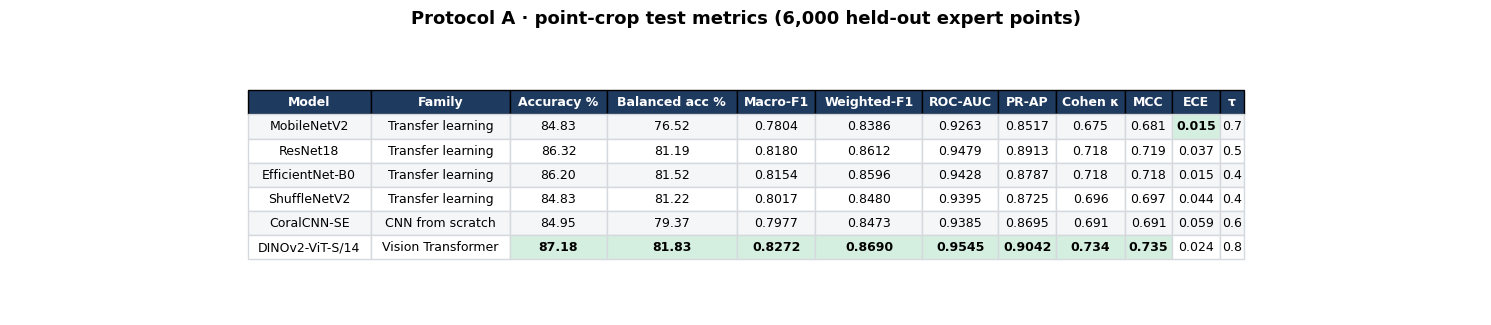

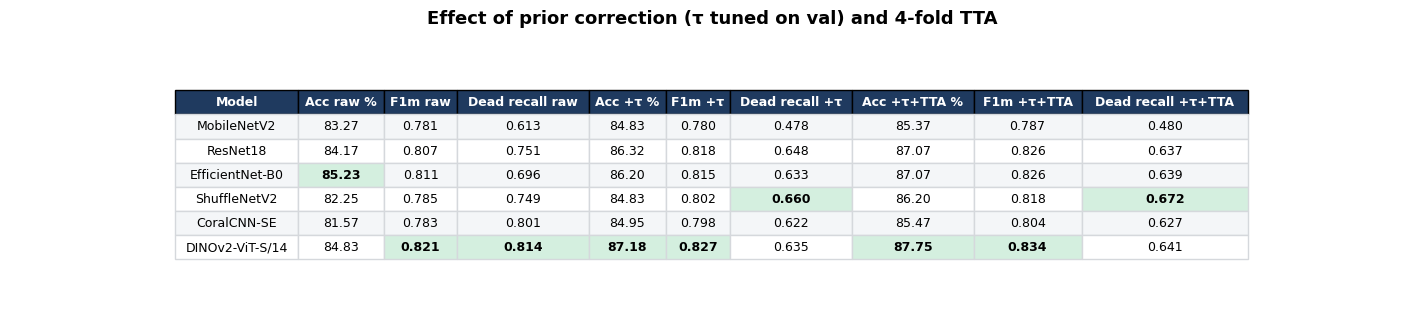

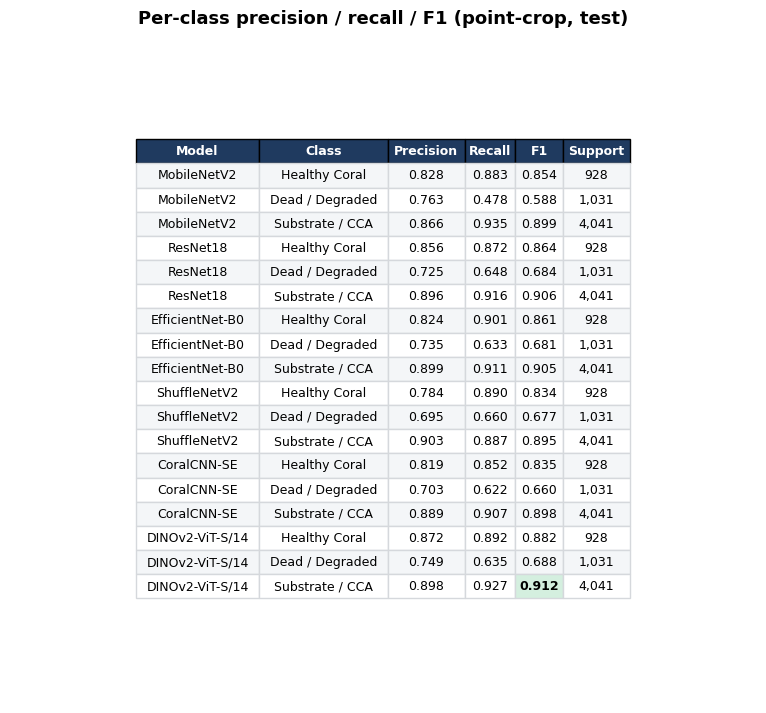

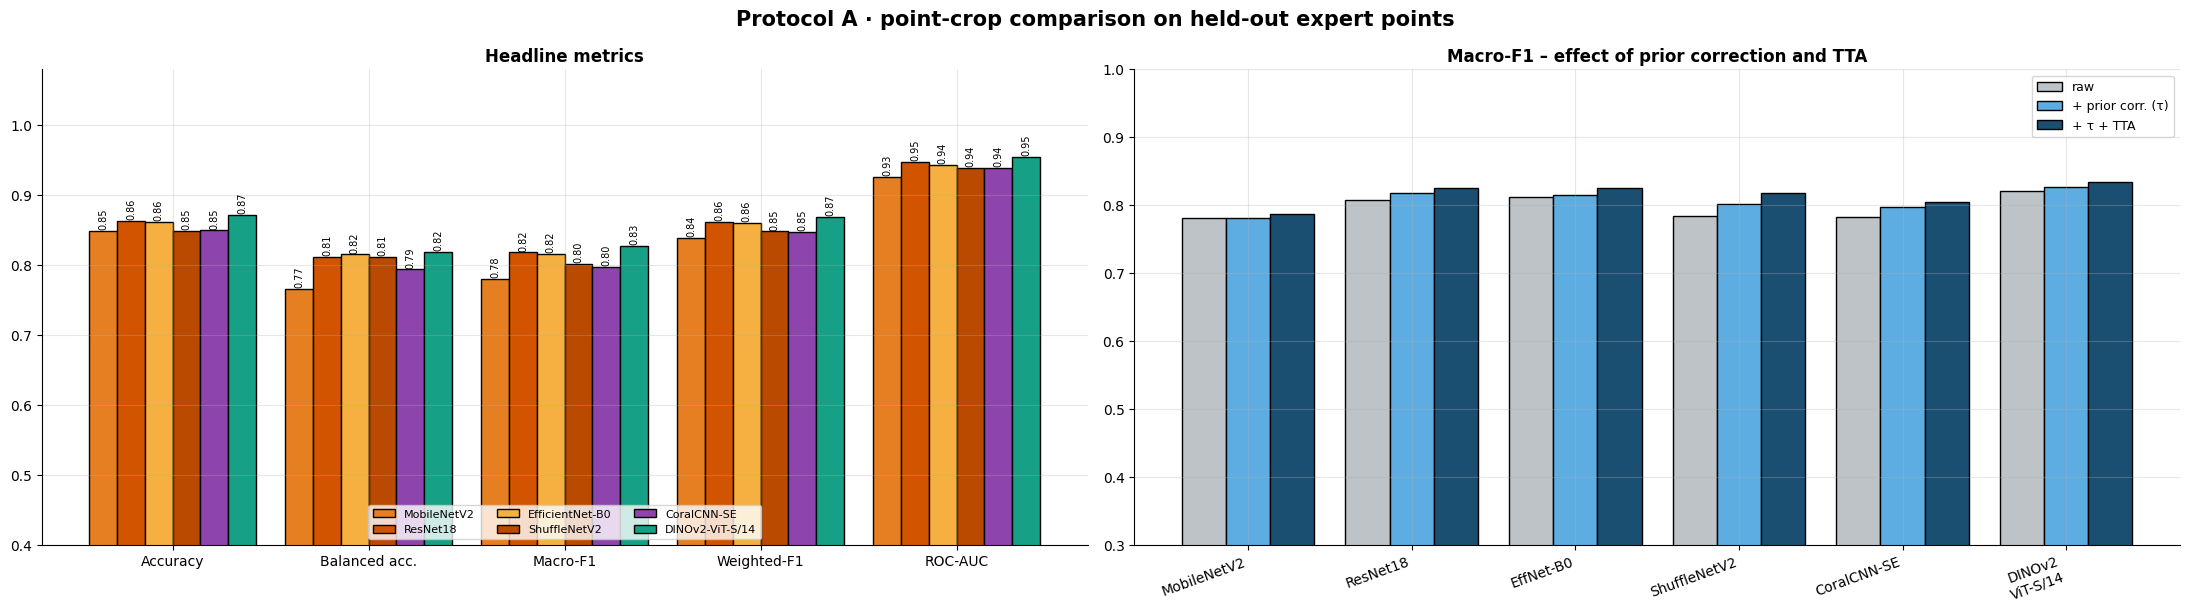

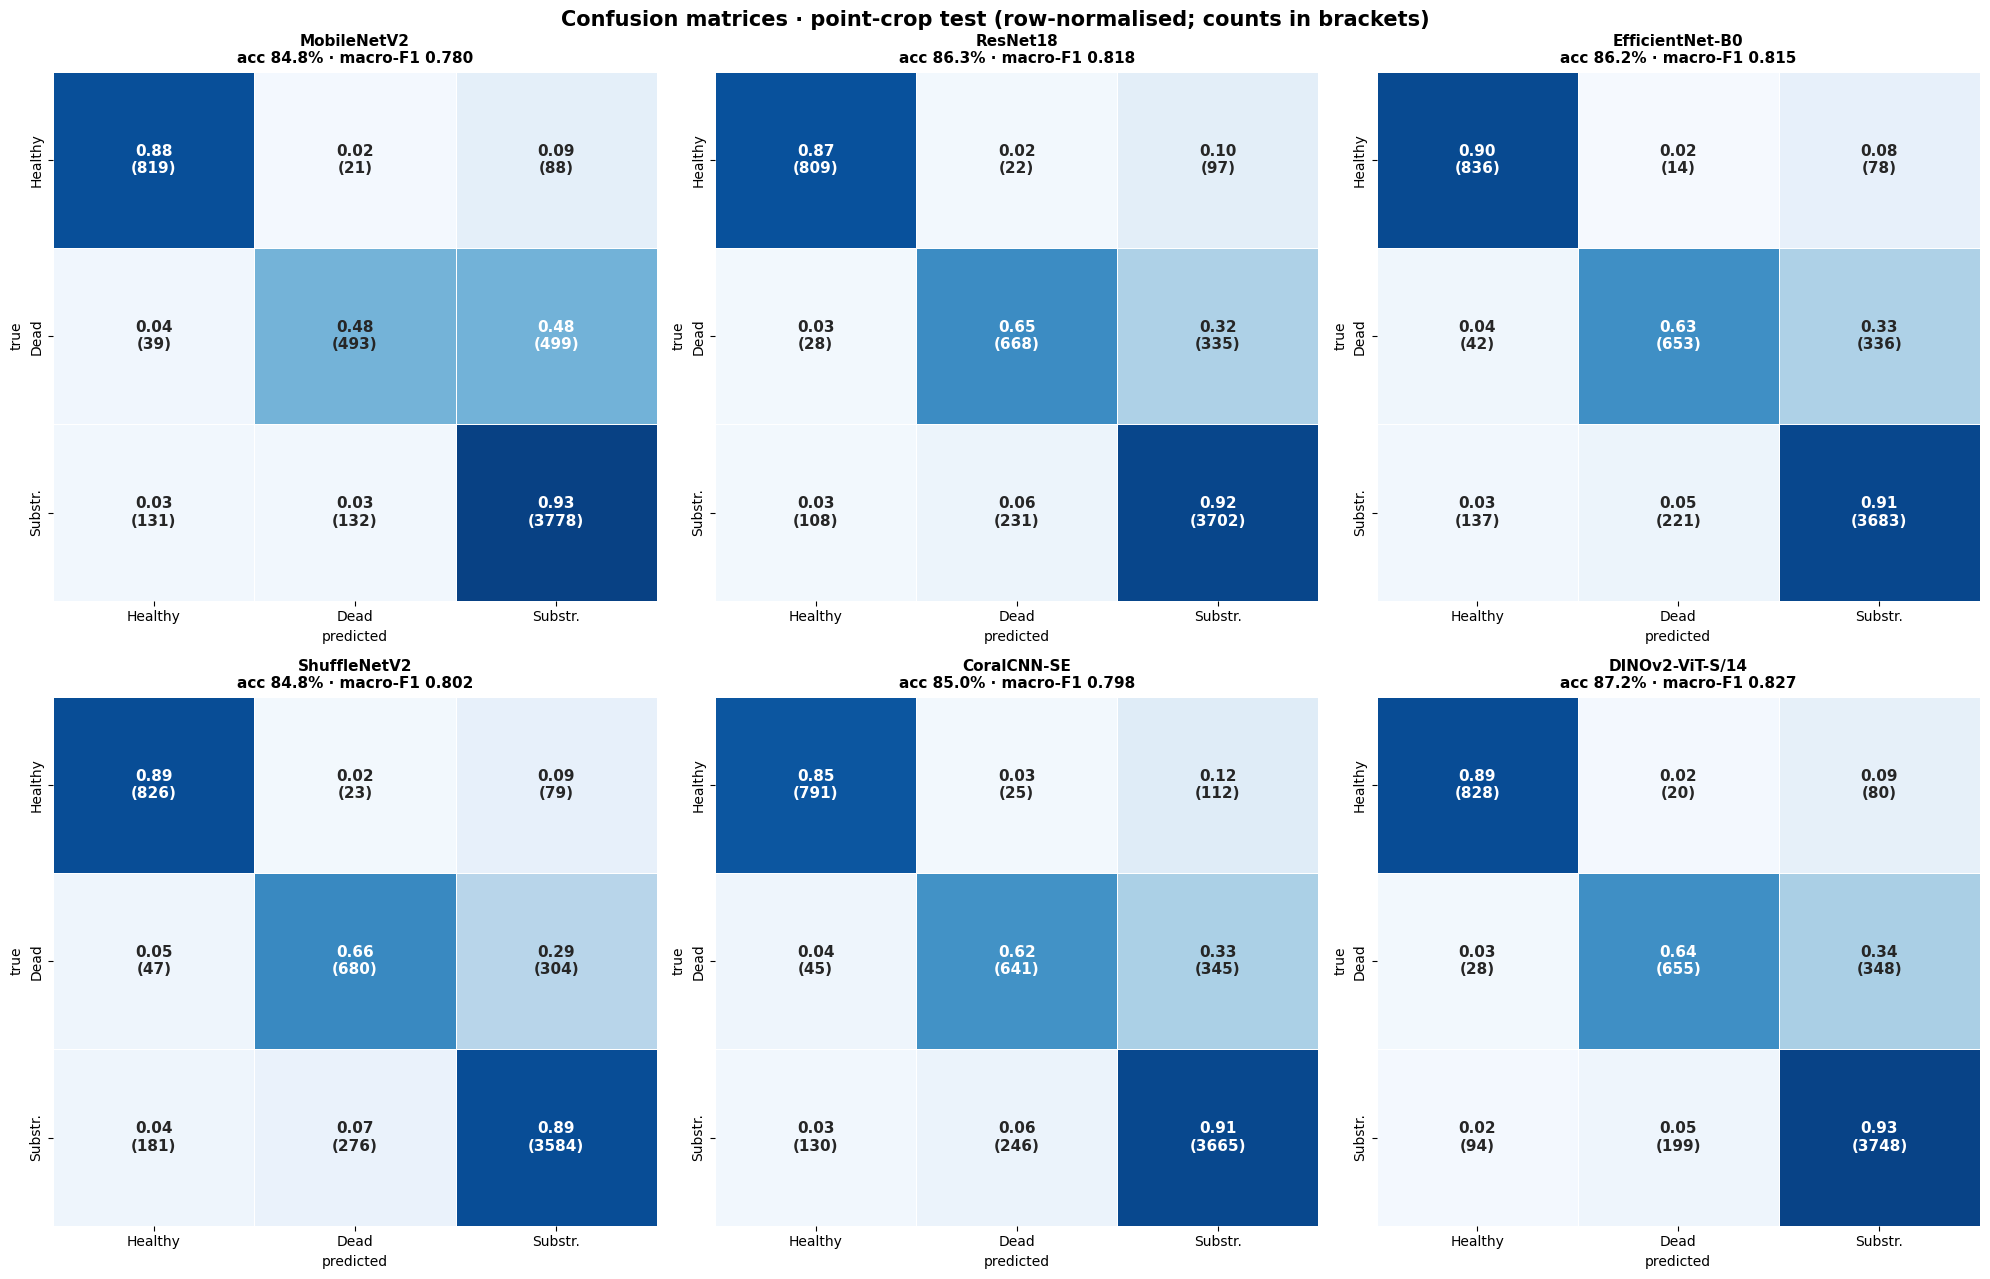

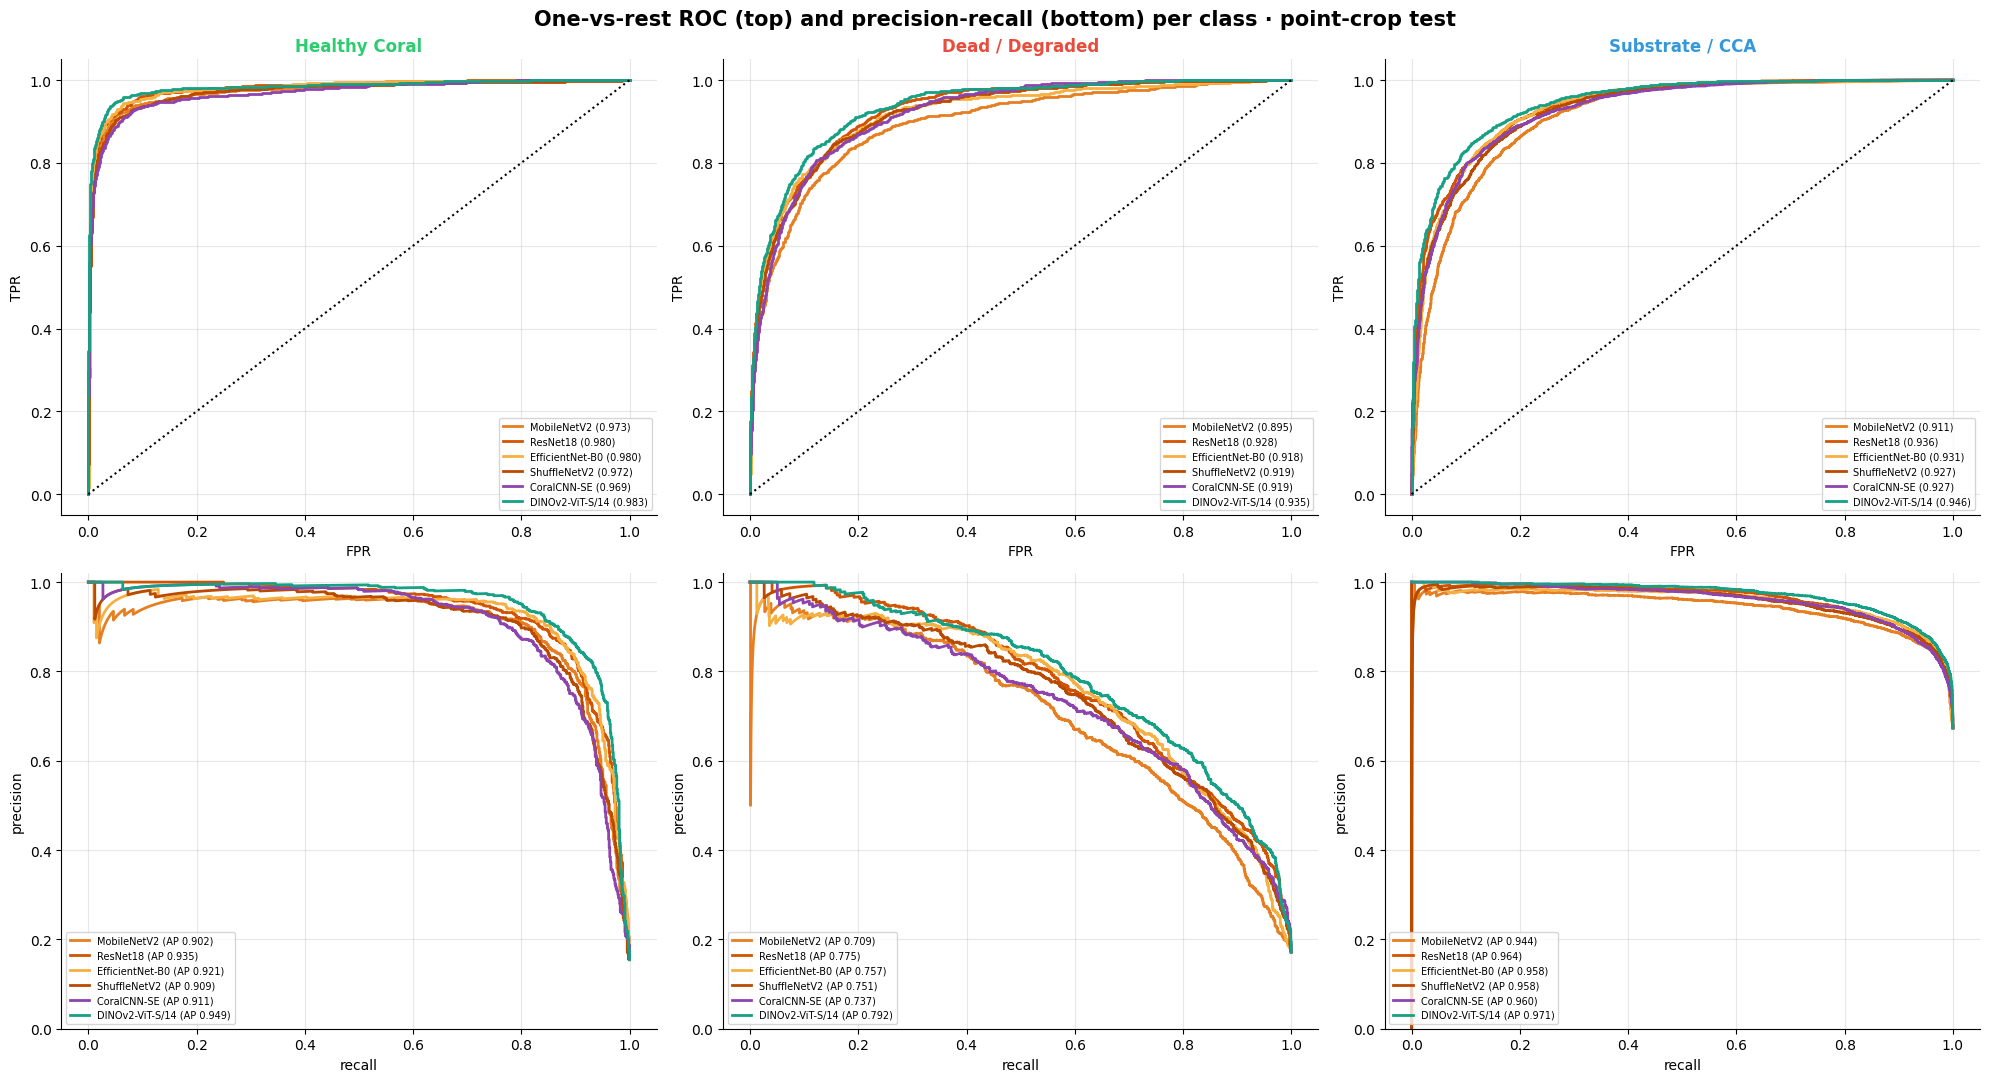

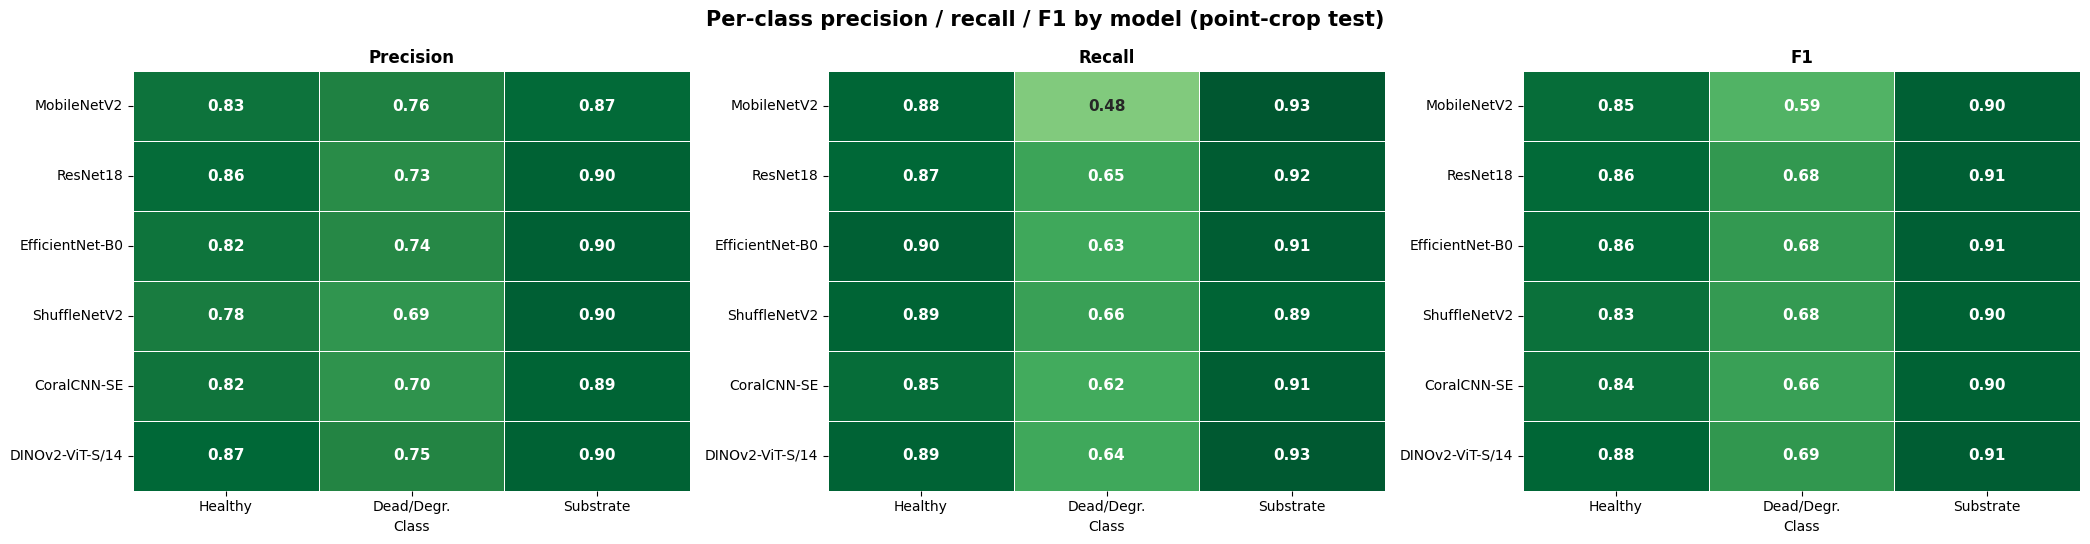

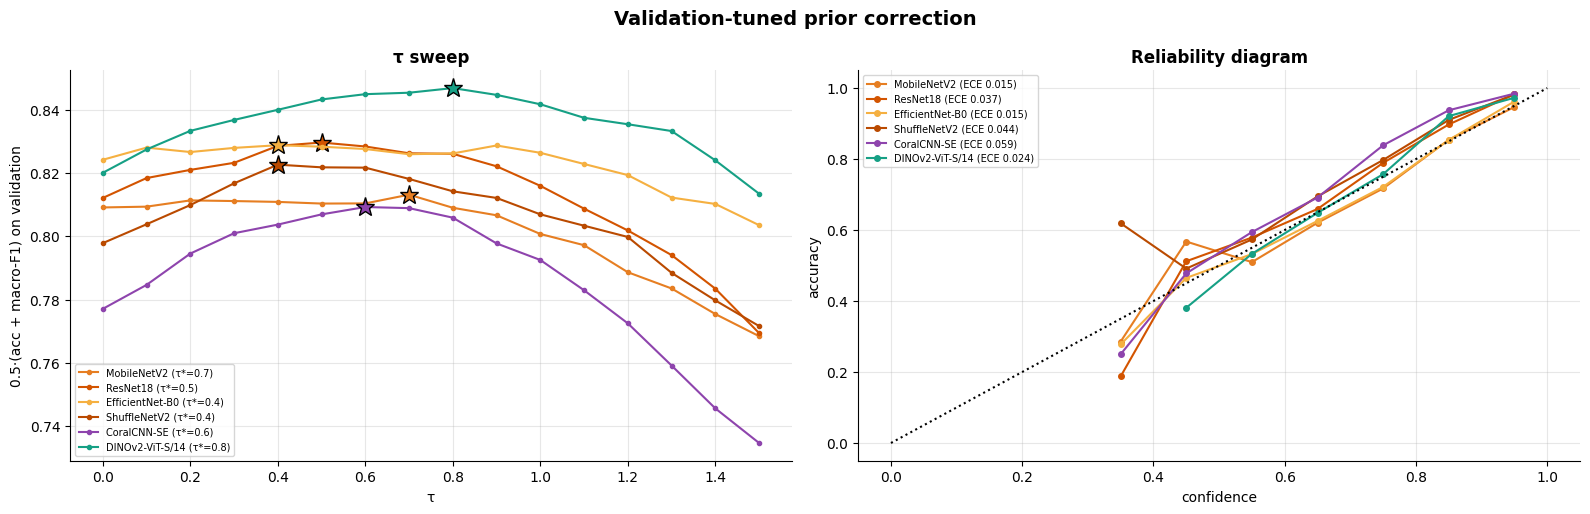

'/content/coral_final/figures/result_05_tau_and_calibration.png'

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 13 · PROTOCOL A · POINT-CROP EVALUATION  (test crops, natural distribution)
#      raw → prior-shift corrected (τ tuned on VAL) → + 4-fold TTA
# ═══════════════════════════════════════════════════════════════════════════
def adjust(probs, tau):
    """logit adjustment for prior shift: p ∝ p_model · (π_nat / π_train)^τ   (τ=0 → raw, τ=1 → full Bayes correction)"""
    q = probs * (PRIOR_RATIO ** tau); return q / q.sum(1, keepdims=True)

def ece_score(probs, y, bins=15):
    conf, pred = probs.max(1), probs.argmax(1); acc = (pred == y).astype(float); e = 0.0
    edges = np.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return e

def full_metrics(y, probs):
    pred = probs.argmax(1); p, r, f, s = precision_recall_fscore_support(y, pred, labels=[0, 1, 2], zero_division=0)
    yb = label_binarize(y, classes=[0, 1, 2])
    try: auc_m = roc_auc_score(yb, probs, average='macro')
    except Exception: auc_m = np.nan
    try: ap_m = average_precision_score(yb, probs, average='macro')
    except Exception: ap_m = np.nan
    return dict(acc=accuracy_score(y, pred), bal_acc=balanced_accuracy_score(y, pred), f1_macro=f1_score(y, pred, average='macro'), f1_weighted=f1_score(y, pred, average='weighted'),
                kappa=cohen_kappa_score(y, pred), mcc=matthews_corrcoef(y, pred), auc=auc_m, ap=ap_m, ece=ece_score(probs, y), prec=p, rec=r, f1=f, support=s,
                cm=confusion_matrix(y, pred, labels=[0, 1, 2]))

TAUS = np.round(np.arange(0, 1.51, 0.1), 2)
PRED, TAU, VAL_SCORE, MET = {}, {}, {}, {}
yv, yt = DATA['val']['y'], DATA['test']['y']
for name in tqdm(MODEL_ORDER, desc='evaluating'):
    m = MODELS[name]
    pv, pt = softmax_np(infer_logits(m, DATA['val']['x'])), softmax_np(infer_logits(m, DATA['test']['x']))
    pvt, ptt = softmax_np(infer_logits(m, DATA['val']['x'], tta=True)), softmax_np(infer_logits(m, DATA['test']['x'], tta=True))
    # τ chosen on VALIDATION only: maximise 0.5·(accuracy + macro-F1)  (ties → smaller τ)
    scores = [0.5 * (accuracy_score(yv, adjust(pv, t).argmax(1)) + f1_score(yv, adjust(pv, t).argmax(1), average='macro')) for t in TAUS]
    tau = float(TAUS[int(np.argmax(scores))]); TAU[name] = tau; VAL_SCORE[name] = float(max(scores))
    PRED[name] = dict(val=pv, test=pt, test_tta=ptt, val_tta=pvt, test_adj=adjust(pt, tau), test_tta_adj=adjust(ptt, tau), tau_curve=scores)
    MET[name] = dict(raw=full_metrics(yt, pt), tuned=full_metrics(yt, adjust(pt, tau)), tta=full_metrics(yt, adjust(ptt, tau)), tta_raw=full_metrics(yt, ptt))
MAIN = 'tuned'          # headline configuration = single forward pass + validation-tuned prior correction
print('Validation-tuned τ:', TAU)

hdr('Table · point-crop test metrics (headline = prior-corrected, single forward pass)')
main_tbl = pd.DataFrame([dict(Model=n, Family=FAMILY[n], **{'Accuracy %': MET[n][MAIN]['acc'] * 100, 'Balanced acc %': MET[n][MAIN]['bal_acc'] * 100, 'Macro-F1': MET[n][MAIN]['f1_macro'],
    'Weighted-F1': MET[n][MAIN]['f1_weighted'], 'ROC-AUC': MET[n][MAIN]['auc'], 'PR-AP': MET[n][MAIN]['ap'], 'Cohen κ': MET[n][MAIN]['kappa'], 'MCC': MET[n][MAIN]['mcc'],
    'ECE': MET[n][MAIN]['ece'], 'τ': TAU[n]}) for n in MODEL_ORDER])
table_png(main_tbl, 'table_05_point_crop_metrics', f'Protocol A · point-crop test metrics ({len(yt):,} held-out expert points)',
          fmt={'Accuracy %': '{:.2f}', 'Balanced acc %': '{:.2f}', 'Macro-F1': '{:.4f}', 'Weighted-F1': '{:.4f}', 'ROC-AUC': '{:.4f}', 'PR-AP': '{:.4f}', 'Cohen κ': '{:.3f}', 'MCC': '{:.3f}', 'ECE': '{:.3f}', 'τ': '{:.1f}'},
          best_max=['Accuracy %', 'Balanced acc %', 'Macro-F1', 'Weighted-F1', 'ROC-AUC', 'PR-AP', 'Cohen κ', 'MCC'], best_min=['ECE'], font=9)

abl = pd.DataFrame([dict(Model=n, **{'Acc raw %': MET[n]['raw']['acc'] * 100, 'F1m raw': MET[n]['raw']['f1_macro'], 'Dead recall raw': MET[n]['raw']['rec'][1],
    'Acc +τ %': MET[n]['tuned']['acc'] * 100, 'F1m +τ': MET[n]['tuned']['f1_macro'], 'Dead recall +τ': MET[n]['tuned']['rec'][1],
    'Acc +τ+TTA %': MET[n]['tta']['acc'] * 100, 'F1m +τ+TTA': MET[n]['tta']['f1_macro'], 'Dead recall +τ+TTA': MET[n]['tta']['rec'][1]}) for n in MODEL_ORDER])
table_png(abl, 'table_06_ablation_prior_tta', 'Effect of prior correction (τ tuned on val) and 4-fold TTA', fmt={c: ('{:.2f}' if '%' in c else '{:.3f}') for c in abl.columns if c != 'Model'},
          best_max=[c for c in abl.columns if c != 'Model'], font=9)

pcls = []
for n in MODEL_ORDER:
    for k, cn in enumerate(CLASS_NAMES):
        pcls.append(dict(Model=n, Class=cn, Precision=MET[n][MAIN]['prec'][k], Recall=MET[n][MAIN]['rec'][k], F1=MET[n][MAIN]['f1'][k], Support=int(MET[n][MAIN]['support'][k])))
pcls = pd.DataFrame(pcls); table_png(pcls, 'table_07_per_class_metrics', 'Per-class precision / recall / F1 (point-crop, test)', fmt={'Precision': '{:.3f}', 'Recall': '{:.3f}', 'F1': '{:.3f}'}, best_max=['F1'], font=9)

# ── plots ──
fig, axes = plt.subplots(1, 2, figsize=(22, 6.2)); fig.suptitle('Protocol A · point-crop comparison on held-out expert points', fontsize=15, fontweight='bold')
metrics_ = [('acc', 'Accuracy'), ('bal_acc', 'Balanced acc.'), ('f1_macro', 'Macro-F1'), ('f1_weighted', 'Weighted-F1'), ('auc', 'ROC-AUC')]
x = np.arange(len(metrics_)); w = 0.85 / len(MODEL_ORDER)
for k, n in enumerate(MODEL_ORDER):
    vals = [MET[n][MAIN][m] for m, _ in metrics_]; b = axes[0].bar(x + (k - len(MODEL_ORDER) / 2 + 0.5) * w, vals, w, color=MODEL_COL[n], edgecolor='black', label=n)
    for bi, v in zip(b, vals): axes[0].text(bi.get_x() + bi.get_width() / 2, v + 0.005, f'{v:.2f}', ha='center', fontsize=7, rotation=90)
axes[0].set_xticks(x); axes[0].set_xticklabels([t for _, t in metrics_]); axes[0].set_ylim(0.4, 1.08); axes[0].legend(ncol=3, fontsize=8, loc='lower center'); axes[0].set_title('Headline metrics')
cfgs = [('raw', 'raw'), ('tuned', '+ prior corr. (τ)'), ('tta', '+ τ + TTA')]; x = np.arange(len(MODEL_ORDER)); w = 0.27
for k, (c, lab) in enumerate(cfgs):
    axes[1].bar(x + (k - 1) * w, [MET[n][c]['f1_macro'] for n in MODEL_ORDER], w, label=lab, edgecolor='black', color=['#bdc3c7', '#5dade2', '#1b4f72'][k])
axes[1].set_xticks(x); axes[1].set_xticklabels([n.replace('DINOv2-ViT-S/14', 'DINOv2\nViT-S/14').replace('EfficientNet-B0', 'EffNet-B0') for n in MODEL_ORDER], rotation=20, ha='right')
axes[1].set_ylim(0.3, 1.0); axes[1].set_title('Macro-F1 – effect of prior correction and TTA'); axes[1].legend()
plt.tight_layout(); save_fig(fig, 'result_01_point_crop_metrics')

fig, axes = plt.subplots(2, 3, figsize=(20, 13)); fig.suptitle('Confusion matrices · point-crop test (row-normalised; counts in brackets)', fontsize=15, fontweight='bold')
for a, n in zip(axes.flat, MODEL_ORDER):
    cm = MET[n][MAIN]['cm']; cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    sns.heatmap(cmn, annot=np.array([[f'{cmn[i, j]:.2f}\n({cm[i, j]})' for j in range(3)] for i in range(3)]), fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False, ax=a,
                xticklabels=['Healthy', 'Dead', 'Substr.'], yticklabels=['Healthy', 'Dead', 'Substr.'], linewidths=0.5, annot_kws={'size': 11, 'weight': 'bold'})
    a.set_title(f'{n}\nacc {MET[n][MAIN]["acc"]*100:.1f}% · macro-F1 {MET[n][MAIN]["f1_macro"]:.3f}', fontsize=11); a.set_xlabel('predicted'); a.set_ylabel('true'); a.grid(False)
plt.tight_layout(); save_fig(fig, 'result_02_confusion_matrices')

fig, axes = plt.subplots(2, 3, figsize=(20, 11)); fig.suptitle('One-vs-rest ROC (top) and precision-recall (bottom) per class · point-crop test', fontsize=15, fontweight='bold')
yb = label_binarize(yt, classes=[0, 1, 2])
for k, cn in enumerate(CLASS_NAMES):
    for n in MODEL_ORDER:
        pr_ = PRED[n]['test_adj'][:, k]; fpr, tpr, _ = roc_curve(yb[:, k], pr_); axes[0, k].plot(fpr, tpr, lw=2, color=MODEL_COL[n], label=f'{n} ({sk_auc(fpr, tpr):.3f})')
        pc, rc, _ = precision_recall_curve(yb[:, k], pr_); axes[1, k].plot(rc, pc, lw=2, color=MODEL_COL[n], label=f'{n} (AP {average_precision_score(yb[:, k], pr_):.3f})')
    axes[0, k].plot([0, 1], [0, 1], 'k:'); axes[0, k].set_title(cn, color=CLS_COL[k]); axes[0, k].set_xlabel('FPR'); axes[0, k].set_ylabel('TPR'); axes[0, k].legend(fontsize=7, loc='lower right')
    axes[1, k].set_xlabel('recall'); axes[1, k].set_ylabel('precision'); axes[1, k].legend(fontsize=7, loc='lower left'); axes[1, k].set_ylim(0, 1.02)
plt.tight_layout(); save_fig(fig, 'result_03_roc_pr_curves')

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5)); fig.suptitle('Per-class precision / recall / F1 by model (point-crop test)', fontsize=15, fontweight='bold')
for a, col in zip(axes, ('Precision', 'Recall', 'F1')):
    piv = pcls.pivot(index='Model', columns='Class', values=col).reindex(MODEL_ORDER)[CLASS_NAMES]
    sns.heatmap(piv, annot=True, fmt='.2f', cmap='YlGn', vmin=0, vmax=1, ax=a, linewidths=0.5, cbar=False, annot_kws={'size': 11, 'weight': 'bold'}); a.set_title(col); a.set_ylabel(''); a.grid(False)
    a.set_xticklabels(['Healthy', 'Dead/Degr.', 'Substrate'], rotation=0)
plt.tight_layout(); save_fig(fig, 'result_04_per_class_heatmaps')

fig, ax = plt.subplots(1, 2, figsize=(16, 5.2)); fig.suptitle('Validation-tuned prior correction', fontsize=14, fontweight='bold')
for n in MODEL_ORDER: ax[0].plot(TAUS, PRED[n]['tau_curve'], '-o', ms=3, color=MODEL_COL[n], label=f'{n} (τ*={TAU[n]})'); ax[0].plot(TAU[n], VAL_SCORE[n], '*', ms=14, color=MODEL_COL[n], mec='k')
ax[0].set_xlabel('τ'); ax[0].set_ylabel('0.5·(acc + macro-F1) on validation'); ax[0].legend(fontsize=7); ax[0].set_title('τ sweep')
for n in MODEL_ORDER:
    p_ = PRED[n]['test_adj']; fr, mp = [], []
    edges = np.linspace(0, 1, 11)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m_ = (p_.max(1) > lo) & (p_.max(1) <= hi)
        if m_.sum() >= 10: fr.append((lo + hi) / 2); mp.append((p_.argmax(1)[m_] == yt[m_]).mean())
    ax[1].plot(fr, mp, '-o', ms=4, color=MODEL_COL[n], label=f'{n} (ECE {MET[n][MAIN]["ece"]:.3f})')
ax[1].plot([0, 1], [0, 1], 'k:'); ax[1].set_xlabel('confidence'); ax[1].set_ylabel('accuracy'); ax[1].set_title('Reliability diagram'); ax[1].legend(fontsize=7)
plt.tight_layout(); save_fig(fig, 'result_05_tau_and_calibration')


## 14 · Efficiency – parameters, FLOPs, GPU/CPU latency, throughput

latency:   0%|          | 0/6 [00:00<?, ?it/s]

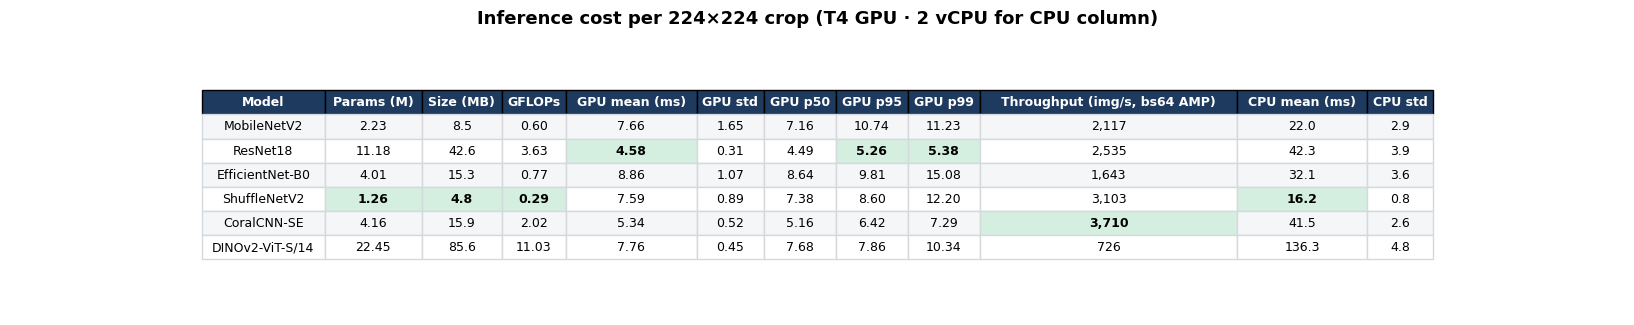

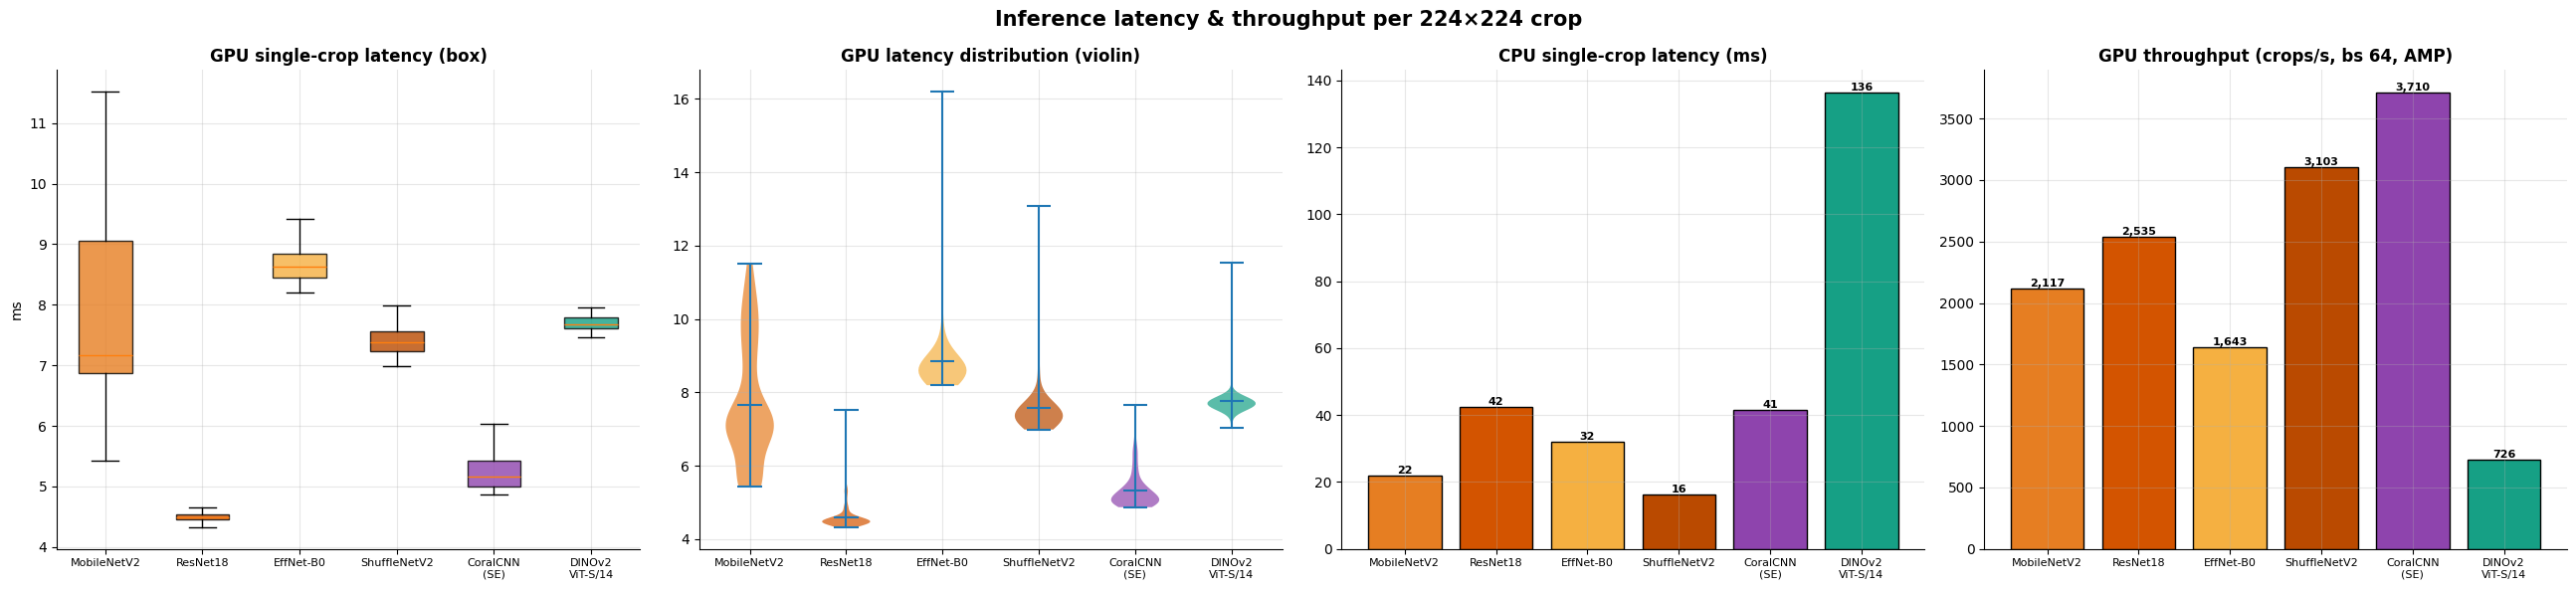

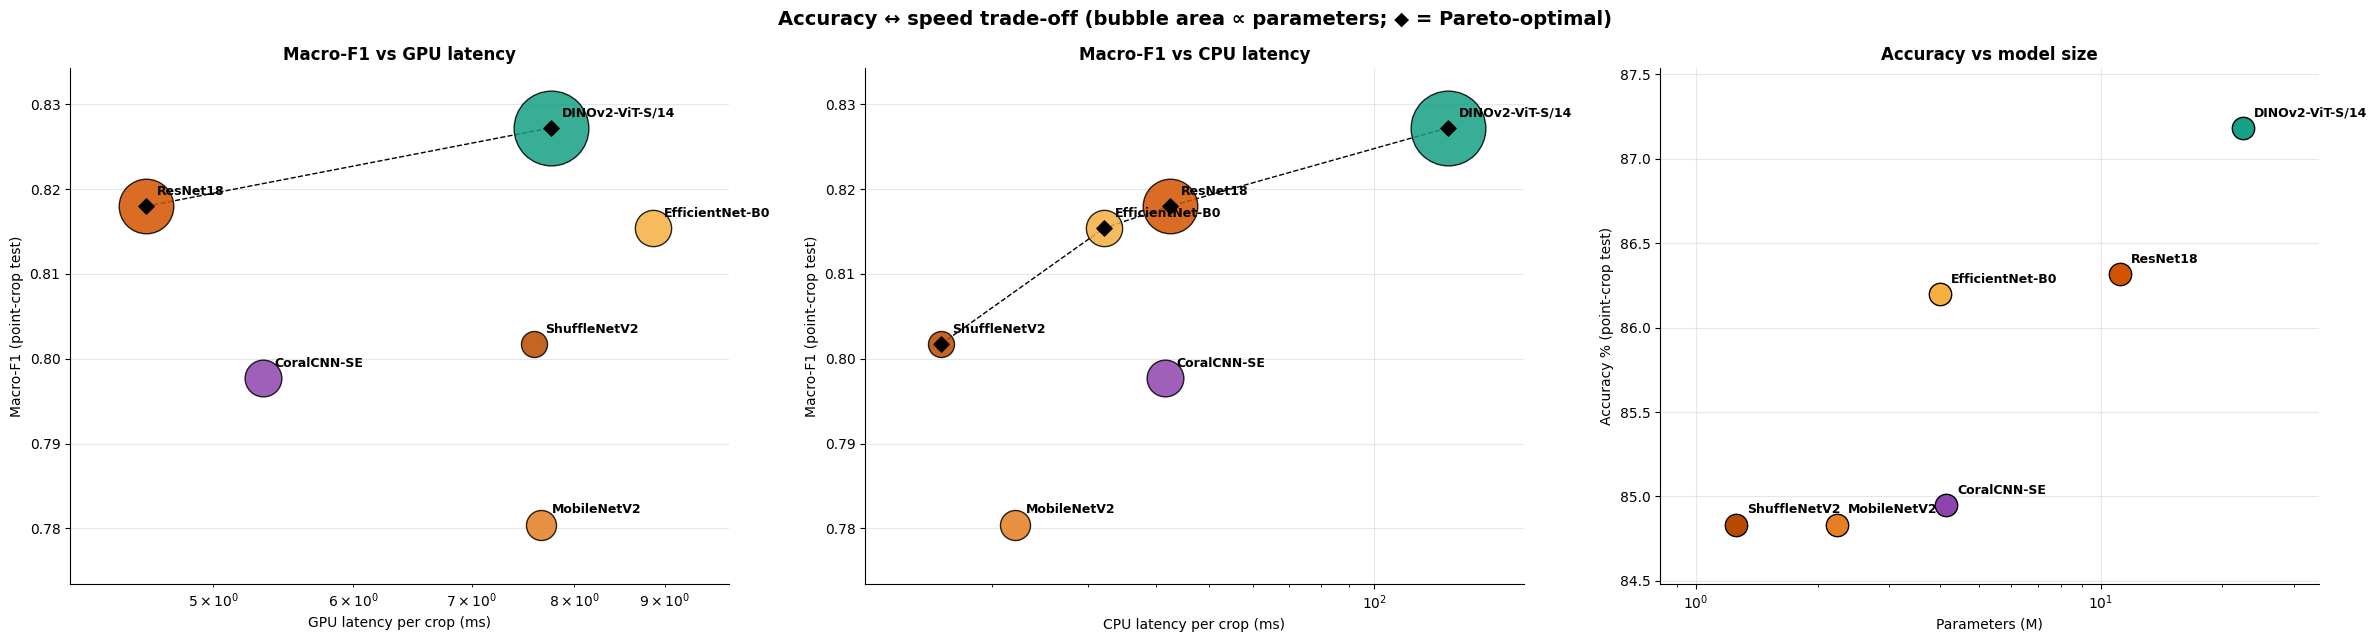

'/content/coral_final/figures/latency_02_tradeoff.png'

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 14 · EFFICIENCY · params · size · GFLOPs · GPU / CPU latency · throughput
# ═══════════════════════════════════════════════════════════════════════════
REPS_GPU, REPS_CPU, WARM = (200, 15, 30) if PROFILE in ('full', 'fast') else (20, 4, 5)
try:
    from torch.utils.flop_counter import FlopCounterMode
except Exception:
    FlopCounterMode = None

def gflops(model_cpu):
    if FlopCounterMode is None: return float('nan')
    try:
        with FlopCounterMode(display=False) as fc: model_cpu(torch.rand(1, 3, CROP, CROP))
        return fc.get_total_flops() / 1e9
    except Exception: return float('nan')

LAT = {}
x1 = torch.rand(1, 3, CROP, CROP, device=DEVICE); xB = torch.rand(64, 3, CROP, CROP, device=DEVICE)
for name in tqdm(MODEL_ORDER, desc='latency'):
    m = MODELS[name].eval(); ts = []
    with torch.no_grad():
        for _ in range(WARM): m(x1)
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        for _ in range(REPS_GPU):                          # single crop, fp32, synchronised → true end-to-end latency
            t0 = time.perf_counter(); m(x1)
            if DEVICE.type == 'cuda': torch.cuda.synchronize()
            ts.append((time.perf_counter() - t0) * 1000)
        tb = []                                            # batch-64 throughput with AMP (the setting used for sliding windows)
        for i in range(12):
            if DEVICE.type == 'cuda': torch.cuda.synchronize()
            t0 = time.perf_counter()
            with torch.autocast(device_type=DEVICE.type, enabled=AMP): m(xB)
            if DEVICE.type == 'cuda': torch.cuda.synchronize()
            if i >= 2: tb.append(time.perf_counter() - t0)
    mc = copy.deepcopy(m).to('cpu').float().eval(); xc = torch.rand(1, 3, CROP, CROP); tc = []
    with torch.no_grad():
        for _ in range(2): mc(xc)
        for _ in range(REPS_CPU): t0 = time.perf_counter(); mc(xc); tc.append((time.perf_counter() - t0) * 1000)
    LAT[name] = dict(gpu_ms=np.array(ts), gpu_mean=np.mean(ts), gpu_std=np.std(ts), gpu_p50=np.percentile(ts, 50), gpu_p95=np.percentile(ts, 95), gpu_p99=np.percentile(ts, 99),
                     thr=64 / np.mean(tb), cpu_ms=np.array(tc), cpu_mean=np.mean(tc), cpu_std=np.std(tc), gflops=gflops(mc),
                     params=sum(p.numel() for p in m.parameters()) / 1e6, size_mb=sum(p.numel() * 4 for p in m.parameters()) / 2**20)
    del mc
if DEVICE.type == 'cuda': torch.cuda.empty_cache()

lat_tbl = pd.DataFrame([dict(Model=n, Params_M=LAT[n]['params'], Size_MB=LAT[n]['size_mb'], GFLOPs=LAT[n]['gflops'], GPU_mean=LAT[n]['gpu_mean'], GPU_std=LAT[n]['gpu_std'], GPU_p50=LAT[n]['gpu_p50'],
    GPU_p95=LAT[n]['gpu_p95'], GPU_p99=LAT[n]['gpu_p99'], Thr=LAT[n]['thr'], CPU_mean=LAT[n]['cpu_mean'], CPU_std=LAT[n]['cpu_std']) for n in MODEL_ORDER])
lat_tbl.columns = ['Model', 'Params (M)', 'Size (MB)', 'GFLOPs', 'GPU mean (ms)', 'GPU std', 'GPU p50', 'GPU p95', 'GPU p99', 'Throughput (img/s, bs64 AMP)', 'CPU mean (ms)', 'CPU std']
table_png(lat_tbl, 'table_08_efficiency_latency', f'Inference cost per 224×224 crop ({"T4 GPU" if DEVICE.type=="cuda" else "CPU"} · {os.cpu_count()} vCPU for CPU column)',
          fmt={'Params (M)': '{:.2f}', 'Size (MB)': '{:.1f}', 'GFLOPs': '{:.2f}', 'GPU mean (ms)': '{:.2f}', 'GPU std': '{:.2f}', 'GPU p50': '{:.2f}', 'GPU p95': '{:.2f}', 'GPU p99': '{:.2f}',
               'Throughput (img/s, bs64 AMP)': '{:,.0f}', 'CPU mean (ms)': '{:.1f}', 'CPU std': '{:.1f}'},
          best_min=['Params (M)', 'Size (MB)', 'GFLOPs', 'GPU mean (ms)', 'GPU p95', 'GPU p99', 'CPU mean (ms)'], best_max=['Throughput (img/s, bs64 AMP)'], font=9)

short = lambda n: n.replace('DINOv2-ViT-S/14', 'DINOv2\nViT-S/14').replace('EfficientNet-B0', 'EffNet-B0').replace('CoralCNN-SE', 'CoralCNN\n(SE)')
fig, axes = plt.subplots(1, 4, figsize=(26, 6)); fig.suptitle('Inference latency & throughput per 224×224 crop', fontsize=15, fontweight='bold')
bp = axes[0].boxplot([LAT[n]['gpu_ms'] for n in MODEL_ORDER], patch_artist=True, notch=False, widths=0.55, showfliers=False)
for p_, n in zip(bp['boxes'], MODEL_ORDER): p_.set_facecolor(MODEL_COL[n]); p_.set_alpha(0.8)
axes[0].set_xticklabels([short(n) for n in MODEL_ORDER], fontsize=8); axes[0].set_ylabel('ms'); axes[0].set_title('GPU single-crop latency (box)')
vp = axes[1].violinplot([LAT[n]['gpu_ms'] for n in MODEL_ORDER], showmeans=True, showmedians=False)
for b_, n in zip(vp['bodies'], MODEL_ORDER): b_.set_facecolor(MODEL_COL[n]); b_.set_alpha(0.7)
axes[1].set_xticks(range(1, len(MODEL_ORDER) + 1)); axes[1].set_xticklabels([short(n) for n in MODEL_ORDER], fontsize=8); axes[1].set_title('GPU latency distribution (violin)')
for a, key, ttl, fmt_ in ((axes[2], 'cpu_mean', 'CPU single-crop latency (ms)', '{:.0f}'), (axes[3], 'thr', 'GPU throughput (crops/s, bs 64, AMP)', '{:,.0f}')):
    vals = [LAT[n][key] for n in MODEL_ORDER]; b = a.bar(range(len(MODEL_ORDER)), vals, color=[MODEL_COL[n] for n in MODEL_ORDER], edgecolor='black')
    a.set_xticks(range(len(MODEL_ORDER))); a.set_xticklabels([short(n) for n in MODEL_ORDER], fontsize=8); a.set_title(ttl)
    for bi, v in zip(b, vals): a.text(bi.get_x() + bi.get_width() / 2, v, fmt_.format(v), ha='center', va='bottom', fontsize=8, fontweight='bold')
plt.tight_layout(); save_fig(fig, 'latency_01_distribution_cpu_throughput')

def pareto_front(xs, ys):                      # minimise x, maximise y
    idx = [i for i in range(len(xs)) if not any((xs[j] <= xs[i] and ys[j] >= ys[i]) and (xs[j] < xs[i] or ys[j] > ys[i]) for j in range(len(xs)))]
    return sorted(idx, key=lambda i: xs[i])

fig, axes = plt.subplots(1, 3, figsize=(24, 6.5)); fig.suptitle('Accuracy ↔ speed trade-off (bubble area ∝ parameters; ◆ = Pareto-optimal)', fontsize=14, fontweight='bold')
for a, key, xl in ((axes[0], 'gpu_mean', 'GPU latency per crop (ms)'), (axes[1], 'cpu_mean', 'CPU latency per crop (ms)')):
    xs = [LAT[n][key] for n in MODEL_ORDER]; ys = [MET[n][MAIN]['f1_macro'] for n in MODEL_ORDER]
    for n, xv, yv_ in zip(MODEL_ORDER, xs, ys): a.scatter(xv, yv_, s=200 + 120 * LAT[n]['params'], color=MODEL_COL[n], edgecolor='k', alpha=0.85, zorder=3); a.annotate(n, (xv, yv_), xytext=(8, 8), textcoords='offset points', fontsize=9, fontweight='bold')
    pf = pareto_front(xs, ys); a.plot([xs[i] for i in pf], [ys[i] for i in pf], 'k--', lw=1, zorder=2)
    for i in pf: a.scatter(xs[i], ys[i], marker='D', s=60, color='k', zorder=4)
    a.set_xscale('log'); a.set_xlabel(xl); a.set_ylabel('Macro-F1 (point-crop test)'); a.margins(0.15)
axes[2].set_title('')
xs = [LAT[n]['params'] for n in MODEL_ORDER]; ys = [MET[n][MAIN]['acc'] * 100 for n in MODEL_ORDER]
for n, xv, yv_ in zip(MODEL_ORDER, xs, ys): axes[2].scatter(xv, yv_, s=260, color=MODEL_COL[n], edgecolor='k', zorder=3); axes[2].annotate(n, (xv, yv_), xytext=(8, 8), textcoords='offset points', fontsize=9, fontweight='bold')
axes[2].set_xscale('log'); axes[2].set_xlabel('Parameters (M)'); axes[2].set_ylabel('Accuracy % (point-crop test)'); axes[2].margins(0.15)
axes[0].set_title('Macro-F1 vs GPU latency'); axes[1].set_title('Macro-F1 vs CPU latency'); axes[2].set_title('Accuracy vs model size')
plt.tight_layout(); save_fig(fig, 'latency_02_tradeoff')


## 15 · Protocol B – sliding-window evaluation on whole held-out quadrats
Gaussian-blended dense health maps scored at every expert point and as live-coral cover.

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 15 · PROTOCOL B · SLIDING-WINDOW EVALUATION ON WHOLE HELD-OUT QUADRATS
#      224×224 window, stride 112 (50 % overlap) → per-window softmax (+ τ prior correction) → 2-D Gaussian blending
#      → dense health map.  Scored (i) at every expert point, (ii) as live-coral cover vs expert cover.
# ═══════════════════════════════════════════════════════════════════════════
SW_STRIDE, SW_DS = 112, 4                              # map is computed at 1/4 resolution (kernel 56 px, stride 28 px)
SW_BS = 128 if DEVICE.type == 'cuda' else 32
_KERN = {}
def gauss_kernel(k, sigma=0.35):
    if k not in _KERN:
        ax = torch.linspace(-1, 1, k, device=DEVICE); xx, yy = torch.meshgrid(ax, ax, indexing='ij')
        g = torch.exp(-(xx ** 2 + yy ** 2) / (2 * sigma ** 2)); _KERN[k] = g / g.max()
    return _KERN[k]

def make_windows(img, stride):
    """filtered RGB uint8 (H,W,3) → all stride-spaced 224×224 windows centred on a grid that covers the whole image (reflect-padded)."""
    t = torch.from_numpy(pad_reflect(img)).to(DEVICE).permute(2, 0, 1)
    u = t.unfold(1, CROP, stride).unfold(2, CROP, stride)                      # (3, ny, nx, 224, 224)
    ny, nx = u.shape[1], u.shape[2]
    return u.permute(1, 2, 0, 3, 4).reshape(ny * nx, 3, CROP, CROP), ny, nx

@torch.no_grad()
def predict_windows(model, win, tau):
    N, out = win.shape[0], []
    for i in range(0, N, SW_BS):
        ch = win[i:i + SW_BS]; n = ch.shape[0]
        if n < SW_BS: ch = torch.cat([ch, ch[-1:].expand(SW_BS - n, -1, -1, -1)])       # fixed batch shape
        with torch.autocast(device_type=DEVICE.type, enabled=AMP):
            out.append(torch.softmax(model(ch.float().div_(255.0)).float(), 1)[:n])
    q = torch.cat(out) * torch.tensor(PRIOR_RATIO ** tau, dtype=torch.float32, device=DEVICE)
    return q / q.sum(1, keepdim=True)

def blend(probs, ny, nx, stride):
    k, s, N = CROP // SW_DS, stride // SW_DS, probs.shape[0]; kern = gauss_kernel(k)
    contrib = (probs[:, :, None, None] * kern[None, None]).reshape(N, 3 * k * k).t().unsqueeze(0)
    OH, OW = (ny - 1) * s + k, (nx - 1) * s + k
    num = F.fold(contrib, (OH, OW), k, stride=s)
    den = F.fold(kern.reshape(1, k * k, 1).expand(1, k * k, N).contiguous(), (OH, OW), k, stride=s)
    return (num / den.clamp_min(1e-6))[0]                                            # (3, OH, OW) dense class probabilities

def sync():
    if DEVICE.type == 'cuda': torch.cuda.synchronize()

def read_quadrat(name, keep_raw=False):
    raw = load_rgb(os.path.join(IMAGES_DIR, name))
    if raw is None: return name, None, None
    return name, (apply_underwater_filter(raw) if APPLY_FILTER else raw), (raw[::SW_DS, ::SW_DS].copy() if keep_raw else None)

def score_dense(dense, rows, cols, H, W):
    """dense (3,OH,OW) → predicted class at expert points, healthy / dead cover (%) over the quadrat, segmentation map"""
    seg = dense.argmax(0); OH, OW = seg.shape
    yy = ((torch.as_tensor(rows, device=DEVICE) + HALF) // SW_DS).clamp(0, OH - 1); xx = ((torch.as_tensor(cols, device=DEVICE) + HALF) // SW_DS).clamp(0, OW - 1)
    pt_pred = seg[yy, xx].cpu().numpy()
    o = HALF // SW_DS; reg = seg[o:o + math.ceil(H / SW_DS), o:o + math.ceil(W / SW_DS)]
    return pt_pred, (reg == 0).float().mean().item() * 100, (reg == 1).float().mean().item() * 100, reg.to(torch.uint8).cpu().numpy()

# ── choose the held-out quadrats ───────────────────────────────────────────
rng_sw = np.random.RandomState(SEED)
sw_names = list(rng_sw.permutation(te_q['Name'].values)[:min(P['sw_images'], len(te_q))])
pts_by_img = {n: g for n, g in df_clean[df_clean['Name'].isin(sw_names)].groupby('Name')}
exp_cover = {n: (pts_by_img[n]['Health_Category'] == 'Healthy Coral').mean() * 100 for n in sw_names if n in pts_by_img}
exp_dead  = {n: (pts_by_img[n]['Health_Category'] == 'Dead / Degraded').mean() * 100 for n in sw_names if n in pts_by_img}
order_ = sorted(exp_cover, key=exp_cover.get)
VIS_SET = [order_[int(i)] for i in np.linspace(0, len(order_) - 1, P['sw_vis'])] if len(order_) else []
print(f'Sliding-window evaluation on {len(sw_names)} held-out quadrats · stride {SW_STRIDE}px · {len(MODEL_ORDER)} models · visual examples: {VIS_SET}')

SW = {n: dict(y=[], p=[], cover=[], dead=[], ms=[], nwin=[], seg={}) for n in MODEL_ORDER}
SW_TRUE = dict(y=[], names=[], cover=[], dead=[]); VIS = {}
from collections import deque
for n in MODEL_ORDER:                                                   # warm-up (cuDNN / kernels / lazy init)
    w_ = torch.randint(0, 255, (SW_BS, 3, CROP, CROP), dtype=torch.uint8, device=DEVICE); predict_windows(MODELS[n], w_, TAU[n]); sync()
with ThreadPoolExecutor(max_workers=2) as ex:
    futs = deque(ex.submit(read_quadrat, nm, nm in VIS_SET) for nm in sw_names[:3]); nxt = 3
    for _ in tqdm(range(len(sw_names)), desc='sliding-window', unit='quadrat'):
        name, img, thumb = futs.popleft().result()
        if nxt < len(sw_names): futs.append(ex.submit(read_quadrat, sw_names[nxt], sw_names[nxt] in VIS_SET)); nxt += 1
        if img is None or name not in pts_by_img: continue
        g = pts_by_img[name]; rows, cols = g['Row'].values, g['Column'].values; H, W = img.shape[:2]
        win, ny, nx = make_windows(img, SW_STRIDE)
        SW_TRUE['y'].append(g['Health_Category'].map(CLASS_TO_IDX).values); SW_TRUE['names'].append(name)
        SW_TRUE['cover'].append(exp_cover[name]); SW_TRUE['dead'].append(exp_dead[name])
        for mname in MODEL_ORDER:
            sync(); t0 = time.perf_counter()
            dense = blend(predict_windows(MODELS[mname], win, TAU[mname]), ny, nx, SW_STRIDE); sync(); dt = (time.perf_counter() - t0) * 1000
            pp, cov, ded, seg = score_dense(dense, rows, cols, H, W)
            r = SW[mname]; r['p'].append(pp); r['cover'].append(cov); r['dead'].append(ded); r['ms'].append(dt); r['nwin'].append(ny * nx)
            if name in VIS_SET: r['seg'][name] = seg
        if name in VIS_SET: VIS[name] = dict(thumb=thumb, rows=rows, cols=cols, cats=g['Health_Category'].values)
        del win
y_sw = np.concatenate(SW_TRUE['y']); cov_true = np.array(SW_TRUE['cover']); dead_true = np.array(SW_TRUE['dead'])

SWM = {}
for n in MODEL_ORDER:
    r = SW[n]; yp = np.concatenate(r['p']); cov = np.array(r['cover']); ded = np.array(r['dead']); ms = np.array(r['ms'])
    pr_, rc_, f_, s_ = precision_recall_fscore_support(y_sw, yp, labels=[0, 1, 2], zero_division=0)
    SWM[n] = dict(acc=accuracy_score(y_sw, yp), bal_acc=balanced_accuracy_score(y_sw, yp), f1_macro=f1_score(y_sw, yp, average='macro'), f1_weighted=f1_score(y_sw, yp, average='weighted'),
                  kappa=cohen_kappa_score(y_sw, yp), rec=rc_, prec=pr_, f1=f_, cm=confusion_matrix(y_sw, yp, labels=[0, 1, 2]),
                  cover_mae=np.mean(np.abs(cov - cov_true)), cover_rmse=np.sqrt(np.mean((cov - cov_true) ** 2)), cover_r=np.corrcoef(cov, cov_true)[0, 1] if len(cov) > 2 else np.nan,
                  cover_bias=np.mean(cov - cov_true), dead_mae=np.mean(np.abs(ded - dead_true)), ms_mean=ms.mean(), ms_std=ms.std(), win_per_s=np.mean(r['nwin']) / (ms.mean() / 1000), nwin=np.mean(r['nwin']), cov=cov, ded=ded)
print(f'Scored {len(y_sw):,} expert points on {len(cov_true)} quadrats')

hdr('Table · sliding-window metrics')
sw_tbl = pd.DataFrame([dict(Model=n, **{'Pt Acc %': SWM[n]['acc'] * 100, 'Bal acc %': SWM[n]['bal_acc'] * 100, 'Macro-F1': SWM[n]['f1_macro'], 'Weighted-F1': SWM[n]['f1_weighted'], 'Dead recall': SWM[n]['rec'][1],
    'Coral-cover MAE (pp)': SWM[n]['cover_mae'], 'RMSE (pp)': SWM[n]['cover_rmse'], 'Pearson r': SWM[n]['cover_r'], 'Bias (pp)': SWM[n]['cover_bias'], 'Dead-cover MAE (pp)': SWM[n]['dead_mae'],
    'ms / quadrat': SWM[n]['ms_mean'], 'windows / s': SWM[n]['win_per_s']}) for n in MODEL_ORDER])
table_png(sw_tbl, 'table_09_sliding_window_metrics', f'Protocol B · sliding window (stride {SW_STRIDE}px, Gaussian blending) on {len(cov_true)} held-out quadrats · {len(y_sw):,} expert points · ≈{np.mean(SW[MODEL_ORDER[0]]["nwin"]):.0f} windows / quadrat',
          fmt={'Pt Acc %': '{:.2f}', 'Bal acc %': '{:.2f}', 'Macro-F1': '{:.4f}', 'Weighted-F1': '{:.4f}', 'Dead recall': '{:.3f}', 'Coral-cover MAE (pp)': '{:.2f}', 'RMSE (pp)': '{:.2f}', 'Pearson r': '{:.3f}',
               'Bias (pp)': '{:+.2f}', 'Dead-cover MAE (pp)': '{:.2f}', 'ms / quadrat': '{:,.0f}', 'windows / s': '{:,.0f}'},
          best_max=['Pt Acc %', 'Bal acc %', 'Macro-F1', 'Weighted-F1', 'Dead recall', 'Pearson r', 'windows / s'], best_min=['Coral-cover MAE (pp)', 'RMSE (pp)', 'Dead-cover MAE (pp)', 'ms / quadrat'], font=9)

# ── qualitative dense maps ──
if VIS:
    cmap_seg = matplotlib.colors.ListedColormap(CLS_COL); vis_names = [n for n in VIS_SET if n in VIS]
    fig, axes = plt.subplots(len(vis_names), 1 + len(MODEL_ORDER), figsize=(3.6 * (1 + len(MODEL_ORDER)), 3.7 * len(vis_names)), squeeze=False)
    fig.suptitle('Sliding-window dense health maps on held-out quadrats (green = healthy coral · red = dead/degraded · blue = substrate/CCA)', fontsize=14, fontweight='bold', y=1.0)
    for i, qn in enumerate(vis_names):
        v = VIS[qn]; a = axes[i, 0]; a.imshow(v['thumb']); a.scatter(v['cols'] / SW_DS, v['rows'] / SW_DS, s=7, c=[HEALTH_COLORS[c] for c in v['cats']], edgecolors='white', linewidths=0.3)
        a.set_title(f'expert points · coral {exp_cover[qn]:.0f}%', fontsize=10);
        for j, mname in enumerate(MODEL_ORDER):
            a = axes[i, j + 1]; a.imshow(v['thumb'], alpha=1.0); seg = SW[mname]['seg'][qn][:v['thumb'].shape[0], :v['thumb'].shape[1]]
            a.imshow(seg, cmap=cmap_seg, vmin=0, vmax=2, alpha=0.55, interpolation='nearest'); a.set_title(f'{mname}\ncoral {SW[mname]["cover"][SW_TRUE["names"].index(qn)]:.0f}%', fontsize=10)
        for a in axes[i]: a.axis('off'); a.grid(False)
    fig.legend(handles=[mpatches.Patch(color=HEALTH_COLORS[c], label=c) for c in CLASS_NAMES], loc='lower center', ncol=3, fontsize=11, bbox_to_anchor=(0.5, 0.0))
    plt.tight_layout(rect=(0, 0.04, 1, 0.97)); save_fig(fig, 'sw_01_qualitative_maps')

fig, axes = plt.subplots(2, 3, figsize=(18, 11.5)); fig.suptitle('Live-coral cover: sliding-window prediction vs expert point-count (one dot = one held-out quadrat)', fontsize=14, fontweight='bold')
for a, n in zip(axes.flat, MODEL_ORDER):
    a.scatter(cov_true, SWM[n]['cov'], s=24, alpha=0.7, color=MODEL_COL[n], edgecolor='k', linewidths=0.3); lim = max(cov_true.max(), SWM[n]['cov'].max(), 1) * 1.05
    a.plot([0, lim], [0, lim], 'k--', lw=1); a.set_xlim(0, lim); a.set_ylim(0, lim); a.set_aspect('equal'); a.set_xlabel('expert cover (%)'); a.set_ylabel('predicted cover (%)')
    a.set_title(f'{n}\nMAE {SWM[n]["cover_mae"]:.1f} pp · r {SWM[n]["cover_r"]:.2f} · bias {SWM[n]["cover_bias"]:+.1f}')
plt.tight_layout(); save_fig(fig, 'sw_02_cover_scatter')

fig, ax = plt.subplots(1, 4, figsize=(26, 5.5)); fig.suptitle('Protocol B · sliding-window summary', fontsize=15, fontweight='bold')
for a, key, ttl, f_ in ((ax[0], 'acc', 'Accuracy at expert points', '{:.1%}'), (ax[1], 'f1_macro', 'Macro-F1 at expert points', '{:.3f}'), (ax[2], 'cover_mae', 'Live-coral cover MAE (pp, lower = better)', '{:.1f}'), (ax[3], 'ms_mean', 'Time per quadrat (ms, log)', '{:,.0f}')):
    vals = [SWM[n][key] for n in MODEL_ORDER]; b = a.bar(range(len(MODEL_ORDER)), vals, color=[MODEL_COL[n] for n in MODEL_ORDER], edgecolor='black')
    a.set_xticks(range(len(MODEL_ORDER))); a.set_xticklabels([short(n) for n in MODEL_ORDER], fontsize=8); a.set_title(ttl)
    for bi, v in zip(b, vals): a.text(bi.get_x() + bi.get_width() / 2, v, f_.format(v), ha='center', va='bottom', fontsize=8, fontweight='bold')
ax[3].set_yscale('log')
plt.tight_layout(); save_fig(fig, 'sw_03_summary')

fig, ax = plt.subplots(1, 2, figsize=(18, 5.5)); fig.suptitle('Centred point-crop vs sliding window (same trained weights)', fontsize=14, fontweight='bold')
x = np.arange(len(MODEL_ORDER)); w = 0.38
for a, (k1, k2, ttl) in zip(ax, (('acc', 'acc', 'Accuracy'), ('f1_macro', 'f1_macro', 'Macro-F1'))):
    v1 = [MET[n][MAIN][k1] for n in MODEL_ORDER]; v2 = [SWM[n][k2] for n in MODEL_ORDER]
    b1 = a.bar(x - w / 2, v1, w, label='point-crop (crop centred on the point)', color='#34495e', edgecolor='k'); b2 = a.bar(x + w / 2, v2, w, label='sliding window + Gaussian blend', color='#e67e22', edgecolor='k')
    for b in list(b1) + list(b2): a.text(b.get_x() + b.get_width() / 2, b.get_height(), f'{b.get_height():.2f}', ha='center', va='bottom', fontsize=8)
    a.set_xticks(x); a.set_xticklabels([short(n) for n in MODEL_ORDER], fontsize=8); a.set_title(ttl); a.legend(fontsize=8); a.set_ylim(0.3, 1.02)
plt.tight_layout(); save_fig(fig, 'sw_04_crop_vs_window')

fig, axes = plt.subplots(2, 3, figsize=(20, 13)); fig.suptitle('Confusion matrices · sliding window at expert points (row-normalised)', fontsize=15, fontweight='bold')
for a, n in zip(axes.flat, MODEL_ORDER):
    cm = SWM[n]['cm']; cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    sns.heatmap(cmn, annot=np.array([[f'{cmn[i, j]:.2f}\n({cm[i, j]})' for j in range(3)] for i in range(3)]), fmt='', cmap='Oranges', vmin=0, vmax=1, cbar=False, ax=a,
                xticklabels=['Healthy', 'Dead', 'Substr.'], yticklabels=['Healthy', 'Dead', 'Substr.'], linewidths=0.5, annot_kws={'size': 11, 'weight': 'bold'})
    a.set_title(f'{n}\nacc {SWM[n]["acc"]*100:.1f}% · macro-F1 {SWM[n]["f1_macro"]:.3f}'); a.set_xlabel('predicted'); a.set_ylabel('true'); a.grid(False)
plt.tight_layout(); save_fig(fig, 'sw_05_confusion_matrices')


This cell output is too large and can only be displayed while logged in.


## 16 · Sliding-window stride study

Stride study with DINOv2-ViT-S/14 (best val score 0.8468) on 20 quadrats


stride study:   0%|          | 0/20 [00:00<?, ?it/s]

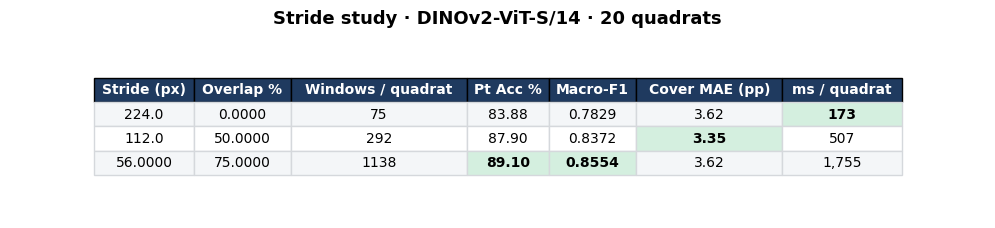

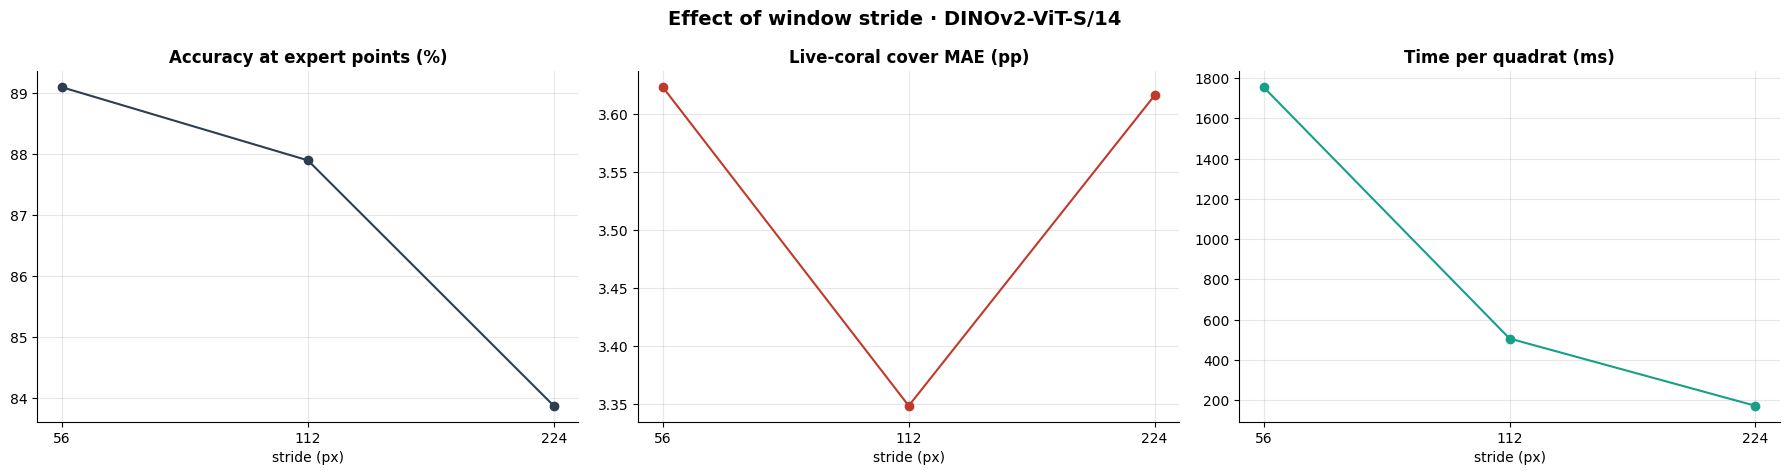

'/content/coral_final/figures/sw_06_stride_study.png'

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 16 · SLIDING-WINDOW STRIDE STUDY (best validation-score model): accuracy / cover error / time vs stride
# ═══════════════════════════════════════════════════════════════════════════
BEST_MODEL = max(MODEL_ORDER, key=lambda n: VAL_SCORE[n])
STRIDES = [224, 112, 56] if PROFILE in ('full', 'fast') else [224, 112]
st_names = [n for n in sw_names if n in pts_by_img][:P['stride_imgs']]
print(f'Stride study with {BEST_MODEL} (best val score {VAL_SCORE[BEST_MODEL]:.4f}) on {len(st_names)} quadrats')
ST = {s: dict(y=[], p=[], cov=[], ms=[], nwin=[]) for s in STRIDES}; st_true_cov = []
for nm in tqdm(st_names, desc='stride study'):
    _, img, _ = read_quadrat(nm)
    if img is None: continue
    g = pts_by_img[nm]; rows, cols = g['Row'].values, g['Column'].values; H, W = img.shape[:2]; st_true_cov.append(exp_cover[nm])
    for s in STRIDES:
        win, ny, nx = make_windows(img, s); sync(); t0 = time.perf_counter()
        dense = blend(predict_windows(MODELS[BEST_MODEL], win, TAU[BEST_MODEL]), ny, nx, s); sync(); dt = (time.perf_counter() - t0) * 1000
        pp, cov, _, _ = score_dense(dense, rows, cols, H, W)
        ST[s]['y'].append(g['Health_Category'].map(CLASS_TO_IDX).values); ST[s]['p'].append(pp); ST[s]['cov'].append(cov); ST[s]['ms'].append(dt); ST[s]['nwin'].append(ny * nx); del win
st_rows = []
for s in STRIDES:
    yy, pp = np.concatenate(ST[s]['y']), np.concatenate(ST[s]['p'])
    st_rows.append({'Stride (px)': s, 'Overlap %': round((1 - s / CROP) * 100), 'Windows / quadrat': np.mean(ST[s]['nwin']), 'Pt Acc %': accuracy_score(yy, pp) * 100, 'Macro-F1': f1_score(yy, pp, average='macro'),
                    'Cover MAE (pp)': np.mean(np.abs(np.array(ST[s]['cov']) - np.array(st_true_cov))), 'ms / quadrat': np.mean(ST[s]['ms'])})
st_df = pd.DataFrame(st_rows)
table_png(st_df, 'table_10_stride_study', f'Stride study · {BEST_MODEL} · {len(st_names)} quadrats', fmt={'Windows / quadrat': '{:.0f}', 'Pt Acc %': '{:.2f}', 'Macro-F1': '{:.4f}', 'Cover MAE (pp)': '{:.2f}', 'ms / quadrat': '{:,.0f}'},
          best_max=['Pt Acc %', 'Macro-F1'], best_min=['Cover MAE (pp)', 'ms / quadrat'])
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8)); fig.suptitle(f'Effect of window stride · {BEST_MODEL}', fontsize=14, fontweight='bold')
ax[0].plot(st_df['Stride (px)'], st_df['Pt Acc %'], '-o', color='#2c3e50'); ax[0].set_title('Accuracy at expert points (%)')
ax[1].plot(st_df['Stride (px)'], st_df['Cover MAE (pp)'], '-o', color='#c0392b'); ax[1].set_title('Live-coral cover MAE (pp)')
ax[2].plot(st_df['Stride (px)'], st_df['ms / quadrat'], '-o', color='#16a085'); ax[2].set_title('Time per quadrat (ms)')
for a in ax: a.set_xlabel('stride (px)'); a.set_xscale('log', base=2); a.set_xticks(STRIDES); a.set_xticklabels(STRIDES)
plt.tight_layout(); save_fig(fig, 'sw_06_stride_study')


## 17 · Grad-CAM explainability
Best transfer-learning model · CoralCNN-SE · DINOv2 ViT – galleries, mistakes, class-specific maps, layer study and quantitative checks.

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 17 · EXPLAINABILITY · Grad-CAM for (a) the best transfer-learning model, (b) the SE-CNN, (c) the DINOv2 ViT
#      Grad-CAM = ReLU(Σ_k α_k A_k),  α_k = GAP(∂y_c/∂A_k)  – computed on the last spatial feature map of each network
#      (CNNs: 7×7 map · ViT: the 16×16 patch-token grid of the last transformer block, tokens reshaped to a grid)
# ═══════════════════════════════════════════════════════════════════════════
BEST_TL = max(TL_NAMES, key=lambda n: VAL_SCORE[n])          # chosen on VALIDATION score (no test leakage)
GC_NAMES = [BEST_TL, 'CoralCNN-SE', 'DINOv2-ViT-S/14']
print(f'Best transfer-learning model (val score {VAL_SCORE[BEST_TL]:.4f}): {BEST_TL}  → Grad-CAM will be shown for {GC_NAMES}')

def target_layer(model, name, which='default'):
    n = model.net
    return {'MobileNetV2': lambda: n.features, 'ResNet18': lambda: n.layer4, 'EfficientNet-B0': lambda: n.features, 'ShuffleNetV2': lambda: n.conv5,
            'CoralCNN-SE': lambda: (n.stage3 if which == 'stage3' else n.stage4), 'DINOv2-ViT-S/14': lambda: n.backbone.blocks[-1]}[name]()
def vit_grid(t):                                              # (B, 1+256, C) tokens → (B, C, 16, 16)
    g = CROP // 14; t = t[:, -g * g:, :]; return t.reshape(t.shape[0], g, g, t.shape[2]).permute(0, 3, 1, 2)

class GradCAM:
    def __init__(self, model, layer, reshape=None):
        self.model, self.reshape, self.acts, self.grads = model, reshape, None, None
        self.h = layer.register_forward_hook(self._fwd)
    def _fwd(self, m, i, o):
        self.acts = o
        if o.requires_grad: o.register_hook(lambda g: setattr(self, 'grads', g))
    def remove(self): self.h.remove()
    def __call__(self, x01, class_idx):
        """x01: float RGB [0,1] (B,3,H,W); class_idx: LongTensor (B,) – class whose evidence is explained. → cams (B,H,W) ≥ 0, probs (B,3)"""
        self.model.eval(); x = x01.detach().clone().to(DEVICE).requires_grad_(True)
        ci = torch.as_tensor(class_idx, device=DEVICE, dtype=torch.long)
        with torch.enable_grad():
            self.model.zero_grad(set_to_none=True); logits = self.model(x)
            logits.gather(1, ci.view(-1, 1)).sum().backward()
        A, G = self.acts, self.grads
        if self.reshape is not None: A, G = self.reshape(A), self.reshape(G)
        cam = F.relu((G.mean((2, 3), keepdim=True) * A).sum(1, keepdim=True)).detach()
        cam = F.interpolate(cam.float(), size=x.shape[-2:], mode='bilinear', align_corners=False)[:, 0]
        return cam.cpu().numpy(), torch.softmax(logits.detach().float(), 1).cpu().numpy()

def make_gc(name, which='default'):
    m = MODELS[name]; return GradCAM(m, target_layer(m, name, which), vit_grid if name.startswith('DINO') else None)
def norm01(c): return c / (c.max(axis=(-2, -1), keepdims=True) + 1e-8)
def overlay(img, cam, a=0.45): return np.clip((1 - a) * img + a * plt.get_cmap('jet')(cam)[..., :3], 0, 1)
def test_batch(ids): return torch.from_numpy(np.ascontiguousarray(DATA['test']['x'][ids])).permute(0, 3, 1, 2).float().div_(255.0)
def cam_for(gc, ids, class_idx, bs=16):
    x = test_batch(ids); cs, ps = [], []
    for i in range(0, len(ids), bs):
        c, p = gc(x[i:i + bs], np.asarray(class_idx)[i:i + bs]); cs.append(c); ps.append(p)
    return norm01(np.concatenate(cs)), np.concatenate(ps), x.permute(0, 2, 3, 1).numpy()

def pick(name, correct=True, k=4):
    p = PRED[name]['test_adj']; pred, conf = p.argmax(1), p.max(1); out = {}
    for c in range(3):
        ids = np.where((yt == c) & ((pred == c) if correct else (pred != c)))[0]; out[c] = ids[np.argsort(-conf[ids])][:k]
    return out

def gallery(name, mode='correct', k=4):
    gc = make_gc(name); ex = pick(name, mode == 'correct', k); p = PRED[name]['test_adj']; pred, conf = p.argmax(1), p.max(1)
    fig, axes = plt.subplots(3, 3 * k, figsize=(2.15 * 3 * k, 7.4)); lay = target_layer(MODELS[name], name)
    fig.suptitle(f'Grad-CAM · {name} [{FAMILY[name]}] · {"most confident CORRECT" if mode=="correct" else "most confident MISTAKES"} test crops per true class  (jet: red = strong evidence for the predicted class)', fontsize=13, fontweight='bold', y=1.03)
    for c in range(3):
        ids = ex[c]
        if len(ids) == 0:
            for j in range(k):
                for r_ in range(3): axes[r_, c * k + j].axis('off')
            continue
        cams, _, imgs = cam_for(gc, ids, pred[ids])
        for j, i in enumerate(ids):
            col = c * k + j; ok = pred[i] == yt[i]
            axes[0, col].imshow(imgs[j]); axes[0, col].plot(HALF, HALF, 'w+', ms=9, mew=1.5)
            axes[0, col].set_title(f'true: {CLASS_NAMES[yt[i]].split()[0]}\npred: {CLASS_NAMES[pred[i]].split()[0]} {conf[i]:.0%}', fontsize=8, color='#1e8449' if ok else '#c0392b', fontweight='bold')
            axes[1, col].imshow(cams[j], cmap='jet', vmin=0, vmax=1); axes[2, col].imshow(overlay(imgs[j], cams[j]))
    for a in axes.flat: a.axis('off'); a.grid(False)
    for r_, t in enumerate(('input', 'Grad-CAM', 'overlay')): axes[r_, 0].text(-0.06, 0.5, t, transform=axes[r_, 0].transAxes, rotation=90, va='center', ha='right', fontsize=10, fontweight='bold')
    plt.tight_layout(); gc.remove(); save_fig(fig, f'gradcam_{safe(name)}_{mode}')

hdr('Grad-CAM galleries (correct + most-confident mistakes)')
for nm in GC_NAMES:
    gallery(nm, 'correct'); gallery(nm, 'wrong')

hdr('Grad-CAM · same crops through the three explained models')
pm = {n: PRED[n]['test_adj'] for n in GC_NAMES}; allok = np.all([pm[n].argmax(1) == yt for n in GC_NAMES], axis=0); meanconf = np.mean([pm[n].max(1) for n in GC_NAMES], axis=0)
XS = []
for c in range(3):
    pool = np.where((yt == c) & allok)[0]
    if len(pool) < 2: pool = np.where(yt == c)[0]
    XS += list(pool[np.argsort(-meanconf[pool])][:2])
XS = np.array(XS)
fig, axes = plt.subplots(1 + len(GC_NAMES), len(XS), figsize=(2.6 * len(XS), 2.7 * (1 + len(GC_NAMES))))
fig.suptitle('Grad-CAM across architectures on identical test crops', fontsize=14, fontweight='bold', y=1.0)
imgs_x = test_batch(XS).permute(0, 2, 3, 1).numpy()
for j, i in enumerate(XS):
    axes[0, j].imshow(imgs_x[j]); axes[0, j].plot(HALF, HALF, 'w+', ms=9, mew=1.5); axes[0, j].set_title(f'true: {CLASS_NAMES[yt[i]]}', fontsize=9, color=CLS_COL[yt[i]], fontweight='bold')
for r_, nm in enumerate(GC_NAMES, start=1):
    gc = make_gc(nm); cams, _, _ = cam_for(gc, XS, pm[nm].argmax(1)[XS]); gc.remove()
    for j, i in enumerate(XS):
        axes[r_, j].imshow(overlay(imgs_x[j], cams[j])); axes[r_, j].set_title(f'{CLASS_NAMES[pm[nm][i].argmax()].split()[0]} {pm[nm][i].max():.0%}', fontsize=8)
    axes[r_, 0].text(-0.08, 0.5, nm, transform=axes[r_, 0].transAxes, rotation=90, va='center', ha='right', fontsize=9, fontweight='bold')
for a in axes.flat: a.axis('off'); a.grid(False)
plt.tight_layout(); save_fig(fig, 'gradcam_cross_model_comparison')

hdr('Grad-CAM · class-specific evidence (shared colour scale across the 3 class maps)')
for nm in GC_NAMES:
    gc = make_gc(nm); fig, axes = plt.subplots(len(XS), 4, figsize=(10.5, 2.6 * len(XS)))
    fig.suptitle(f'{nm} · class-specific Grad-CAM (same scale per row)', fontsize=12, fontweight='bold', y=1.0)
    cams_raw = []
    for c in range(3):                                   # un-normalised maps → shared scale
        x_ = test_batch(XS); cs = [gc(x_[i:i + 16], np.full(len(x_[i:i + 16]), c))[0] for i in range(0, len(XS), 16)]; cams_raw.append(np.concatenate(cs))
    for j, i in enumerate(XS):
        mx = max(cams_raw[c][j].max() for c in range(3)) + 1e-8
        axes[j, 0].imshow(imgs_x[j]); axes[j, 0].set_title(f'true: {CLASS_NAMES[yt[i]].split()[0]}', fontsize=8, color=CLS_COL[yt[i]], fontweight='bold')
        for c in range(3):
            axes[j, c + 1].imshow(overlay(imgs_x[j], np.clip(cams_raw[c][j] / mx, 0, 1))); axes[j, c + 1].set_title(f'CAM: {CLASS_NAMES[c].split()[0]}' if j == 0 else '', fontsize=9, color=CLS_COL[c], fontweight='bold')
    for a in axes.flat: a.axis('off'); a.grid(False)
    gc.remove(); plt.tight_layout(); save_fig(fig, f'gradcam_class_specific_{safe(nm)}')

hdr('Grad-CAM · CNN layer study (stage3 14×14 vs stage4 7×7)')
fig, axes = plt.subplots(3, len(XS), figsize=(2.6 * len(XS), 8)); fig.suptitle('CoralCNN-SE · Grad-CAM at two depths', fontsize=13, fontweight='bold', y=1.0)
cnn_pred = PRED['CoralCNN-SE']['test_adj'].argmax(1)
for j, i in enumerate(XS): axes[0, j].imshow(imgs_x[j]); axes[0, j].set_title(f'true {CLASS_NAMES[yt[i]].split()[0]}\npred {CLASS_NAMES[cnn_pred[i]].split()[0]}', fontsize=8)
for r_, lw in ((1, 'stage3'), (2, 'stage4')):
    gc = make_gc('CoralCNN-SE', lw); cams, _, _ = cam_for(gc, XS, cnn_pred[XS]); gc.remove()
    for j in range(len(XS)): axes[r_, j].imshow(overlay(imgs_x[j], cams[j]))
    axes[r_, 0].text(-0.08, 0.5, f'{lw} ({"14×14" if lw=="stage3" else "7×7"})', transform=axes[r_, 0].transAxes, rotation=90, va='center', ha='right', fontsize=10, fontweight='bold')
for a in axes.flat: a.axis('off'); a.grid(False)
plt.tight_layout(); save_fig(fig, 'gradcam_cnn_layer_study')

hdr('Grad-CAM · quantitative checks (does the heat-map sit on the labelled point and is it faithful?)')
NQ = min(300 if PROFILE in ('full', 'fast') else 48, len(yt)); qids = np.random.RandomState(SEED).choice(len(yt), NQ, replace=False)
yy_, xx_ = np.mgrid[0:CROP, 0:CROP]; dist = np.sqrt((yy_ - HALF) ** 2 + (xx_ - HALF) ** 2); disc56 = dist <= 56; disc32 = dist <= 32
rand_hit = disc32.mean() * 100; uni_mass = disc56.mean()
@torch.no_grad()
def deletion_drop(model, x, cls, cam, frac=0.2):
    thr = torch.quantile(cam.flatten(1), 1 - frac, dim=1).view(-1, 1, 1); mask = (cam >= thr).unsqueeze(1).float()
    fill = x.mean((2, 3), keepdim=True); xm = x * (1 - mask) + fill * mask
    p0 = torch.softmax(model(x), 1).gather(1, cls.view(-1, 1))[:, 0]; p1 = torch.softmax(model(xm), 1).gather(1, cls.view(-1, 1))[:, 0]
    return (p0 - p1).cpu().numpy()
gq = []
for nm in GC_NAMES:
    gc = make_gc(nm); pred_q = PRED[nm]['test_adj'].argmax(1)[qids]; cams, _, _ = cam_for(gc, qids, pred_q); gc.remove()
    cm_ = cams / (cams.sum((1, 2), keepdims=True) + 1e-8); center_mass = (cm_ * disc56).sum((1, 2)).mean()
    peaks = cams.reshape(len(cams), -1).argmax(1); hit = np.mean(disc32.reshape(-1)[peaks]) * 100
    x = test_batch(qids).to(DEVICE); cls_t = torch.as_tensor(pred_q, device=DEVICE); camt = torch.from_numpy(cams).to(DEVICE)
    rnd = F.interpolate(torch.rand(len(qids), 1, 7, 7, device=DEVICE), size=(CROP, CROP), mode='bilinear', align_corners=False)[:, 0]
    d_cam = np.mean([deletion_drop(MODELS[nm].eval(), x[i:i + 32], cls_t[i:i + 32], camt[i:i + 32]).mean() for i in range(0, len(x), 32)])
    d_rnd = np.mean([deletion_drop(MODELS[nm].eval(), x[i:i + 32], cls_t[i:i + 32], rnd[i:i + 32]).mean() for i in range(0, len(x), 32)])
    gq.append({'Model': nm, 'Family': FAMILY[nm], 'Explained layer': {'DINOv2-ViT-S/14': 'last block patch tokens (16×16)', 'CoralCNN-SE': 'stage4 (7×7)'}.get(nm, 'last conv map (7×7)'),
               'Centre-mass (r≤56px)': center_mass, 'Uniform baseline': uni_mass, 'Pointing hit % (r≤32px)': hit, 'Random-peak hit %': rand_hit,
               'Deletion drop (top-20% CAM)': d_cam, 'Deletion drop (random 20%)': d_rnd, 'Faithfulness ratio': d_cam / (abs(d_rnd) + 1e-6)})
gq = pd.DataFrame(gq)
table_png(gq, 'table_11_gradcam_quantitative', f'Grad-CAM quantitative evaluation ({NQ} test crops; ground truth = labelled point at the crop centre)',
          fmt={'Centre-mass (r≤56px)': '{:.3f}', 'Uniform baseline': '{:.3f}', 'Pointing hit % (r≤32px)': '{:.1f}', 'Random-peak hit %': '{:.1f}', 'Deletion drop (top-20% CAM)': '{:.3f}', 'Deletion drop (random 20%)': '{:.3f}', 'Faithfulness ratio': '{:.2f}'},
          best_max=['Centre-mass (r≤56px)', 'Pointing hit % (r≤32px)', 'Deletion drop (top-20% CAM)', 'Faithfulness ratio'], font=9)
fig, ax = plt.subplots(1, 3, figsize=(20, 5)); fig.suptitle('Grad-CAM quality metrics', fontsize=14, fontweight='bold'); x = np.arange(len(gq)); w = 0.38
for a, (k1, k2, ttl) in zip(ax, (('Centre-mass (r≤56px)', 'Uniform baseline', 'Share of CAM mass within 56 px of the labelled point'), ('Pointing hit % (r≤32px)', 'Random-peak hit %', 'Pointing game: CAM peak within 32 px of the point (%)'),
                                  ('Deletion drop (top-20% CAM)', 'Deletion drop (random 20%)', 'Confidence drop when top-20% evidence is erased'))):
    a.bar(x - w / 2, gq[k1], w, label='Grad-CAM', color=[FAMILY_COL[f] for f in gq['Family']], edgecolor='k'); a.bar(x + w / 2, gq[k2], w, label='random baseline', color='#bdc3c7', edgecolor='k')
    a.set_xticks(x); a.set_xticklabels(gq['Model'], rotation=12, fontsize=8); a.set_title(ttl, fontsize=10); a.legend()
plt.tight_layout(); save_fig(fig, 'gradcam_quantitative')


This cell output is too large and can only be displayed while logged in.


## 18 · Final comparison, verdict, saved weights & download bundle

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# 18 · FINAL COMPARISON · master table · ranking · radar · verdict · save weights/tables · zip for download
# ═══════════════════════════════════════════════════════════════════════════
hdr('MASTER COMPARISON TABLE (all models · both protocols · efficiency)')
master = pd.DataFrame([dict(Model=n, Family=FAMILY[n],
    **{'Crop Acc %': MET[n][MAIN]['acc'] * 100, 'Crop Macro-F1': MET[n][MAIN]['f1_macro'], 'Crop AUC': MET[n][MAIN]['auc'], 'Dead recall': MET[n][MAIN]['rec'][1],
       'SW Acc %': SWM[n]['acc'] * 100, 'SW Macro-F1': SWM[n]['f1_macro'], 'Cover MAE (pp)': SWM[n]['cover_mae'], 'Cover r': SWM[n]['cover_r'],
       'Params (M)': LAT[n]['params'], 'GFLOPs': LAT[n]['gflops'], 'GPU ms/crop': LAT[n]['gpu_mean'], 'CPU ms/crop': LAT[n]['cpu_mean'], 'SW ms/quadrat': SWM[n]['ms_mean'], 'Train min': HIST[n]['train_time_s'] / 60}) for n in MODEL_ORDER])
rk = lambda col, asc=False: master[col].rank(ascending=asc, method='min')
master['Accuracy rank'] = (rk('Crop Acc %') + rk('Crop Macro-F1') + rk('SW Macro-F1') + rk('Cover MAE (pp)', True)) / 4
master['Efficiency rank'] = (rk('GPU ms/crop', True) + rk('CPU ms/crop', True) + rk('Params (M)', True)) / 3
master['Overall rank'] = ((master['Accuracy rank'] * 4 + rk('GPU ms/crop', True)) / 5).rank(method='min').astype(int)
fmt_master = {'Crop Acc %': '{:.2f}', 'Crop Macro-F1': '{:.4f}', 'Crop AUC': '{:.4f}', 'Dead recall': '{:.3f}', 'SW Acc %': '{:.2f}', 'SW Macro-F1': '{:.4f}', 'Cover MAE (pp)': '{:.2f}', 'Cover r': '{:.3f}',
              'Params (M)': '{:.2f}', 'GFLOPs': '{:.2f}', 'GPU ms/crop': '{:.2f}', 'CPU ms/crop': '{:.1f}', 'SW ms/quadrat': '{:,.0f}', 'Train min': '{:.1f}', 'Accuracy rank': '{:.2f}', 'Efficiency rank': '{:.2f}'}
table_png(master, 'table_12_MASTER_comparison', 'Master comparison · TL vs CNN-from-scratch vs ViT · point-crop & sliding-window', fmt=fmt_master,
          best_max=['Crop Acc %', 'Crop Macro-F1', 'Crop AUC', 'Dead recall', 'SW Acc %', 'SW Macro-F1', 'Cover r'], best_min=['Cover MAE (pp)', 'Params (M)', 'GFLOPs', 'GPU ms/crop', 'CPU ms/crop', 'SW ms/quadrat', 'Train min', 'Accuracy rank', 'Efficiency rank', 'Overall rank'], font=8)

prev = pd.DataFrame([  # numbers copied from the Review-2 deck (image-level / frozen-ViT protocols → NOT directly comparable, shown for the improvement narrative)
    ('MobileNetV2', 'whole image (369)', 81.0, 0.821, 0.709), ('ResNet18', 'whole image (369)', 82.4, 0.835, 0.732), ('EfficientNet-B0', 'whole image (369)', 82.1, 0.827, 0.704),
    ('ShuffleNetV2', 'whole image (369)', 84.3, 0.852, 0.763), ('CoralCNN + SE', 'whole image (361)', 65.7, 0.687, 0.524), ('DINOv2 ViT-S/14 (frozen)', 'point crop (4000)', 77.7, 0.851, np.nan)],
    columns=['Review-2 model', 'Unit / test set', 'Acc %', 'F1 weighted', 'F1 macro'])
table_png(prev, 'table_13_review2_reference', 'Reference: Review-2 results (different protocol – whole-image labels; not directly comparable)', fmt={'Acc %': '{:.1f}', 'F1 weighted': '{:.3f}', 'F1 macro': '{:.3f}'}, font=9)

def minmax(v, inv=False):
    v = np.asarray(v, float); z = (v - v.min()) / (v.max() - v.min() + 1e-12); z = 1 - z if inv else z; return 0.08 + 0.92 * z
axes_lbl = ['Crop accuracy', 'Crop macro-F1', 'Sliding-window\nmacro-F1', 'Cover accuracy\n(1/MAE)', 'GPU speed', 'Compactness\n(1/params)']
R = np.stack([minmax(master['Crop Acc %']), minmax(master['Crop Macro-F1']), minmax(master['SW Macro-F1']), minmax(master['Cover MAE (pp)'], True), minmax(np.log(master['GPU ms/crop']), True), minmax(np.log(master['Params (M)']), True)], 1)
ang = np.linspace(0, 2 * np.pi, len(axes_lbl), endpoint=False).tolist(); ang += ang[:1]
fig = plt.figure(figsize=(16, 7.5)); ax = fig.add_subplot(1, 2, 1, polar=True)
for i, n in enumerate(MODEL_ORDER):
    v = R[i].tolist() + R[i, :1].tolist(); ax.plot(ang, v, lw=2, color=MODEL_COL[n], label=n); ax.fill(ang, v, alpha=0.06, color=MODEL_COL[n])
ax.set_xticks(ang[:-1]); ax.set_xticklabels(axes_lbl, fontsize=9); ax.set_yticklabels([]); ax.set_title('Normalised profile (outer = better)', pad=22); ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.12), fontsize=8)
ax2 = fig.add_subplot(1, 2, 2); rank_df = master.sort_values('Overall rank'); b = ax2.barh(rank_df['Model'][::-1], (rank_df['Accuracy rank'])[::-1], color=[MODEL_COL[n] for n in rank_df['Model'][::-1]], edgecolor='k')
for bi, (_, r) in zip(b, rank_df[::-1].iterrows()): ax2.text(bi.get_width(), bi.get_y() + bi.get_height() / 2, f'  overall #{int(r["Overall rank"])}', va='center', fontweight='bold')
ax2.set_xlabel('mean accuracy-rank (lower = better)'); ax2.set_title('Ranking (accuracy criteria: crop acc, crop F1, SW F1, cover MAE)')
plt.tight_layout(); save_fig(fig, 'result_06_radar_and_ranking')

fig, ax = plt.subplots(1, 3, figsize=(24, 5.8)); fig.suptitle('Family-level comparison', fontsize=15, fontweight='bold')
for a, (col, ttl) in zip(ax, (('Crop Macro-F1', 'Point-crop macro-F1'), ('SW Macro-F1', 'Sliding-window macro-F1'), ('Cover MAE (pp)', 'Cover MAE (pp, lower = better)'))):
    for fam, g in master.groupby('Family'): a.scatter([short(n).replace('\n', ' ') for n in g['Model']], g[col], s=170, color=FAMILY_COL[fam], edgecolor='k', label=fam, zorder=3)
    a.set_title(ttl); a.tick_params(axis='x', rotation=30, labelsize=8)
ax[0].legend(); plt.tight_layout(); save_fig(fig, 'result_07_family_comparison')

# ─── verdict (auto-generated from the numbers) ───
pf = pareto_front([LAT[n]['gpu_mean'] for n in MODEL_ORDER], [MET[n][MAIN]['f1_macro'] for n in MODEL_ORDER]); pareto_models = [MODEL_ORDER[i] for i in pf]
best = lambda col, asc=False: master.loc[master[col].idxmin() if asc else master[col].idxmax(), 'Model']
fam_best = {f: master[master['Family'] == f].sort_values('Crop Macro-F1', ascending=False).iloc[0] for f in master['Family'].unique()}
rec = rank_df[rank_df['Model'].isin(pareto_models)].iloc[0]['Model']
verdict = [
    f'Best point-crop accuracy      : {best("Crop Acc %")} ({master["Crop Acc %"].max():.2f}%)',
    f'Best point-crop macro-F1      : {best("Crop Macro-F1")} ({master["Crop Macro-F1"].max():.4f})',
    f'Best sliding-window macro-F1  : {best("SW Macro-F1")} ({master["SW Macro-F1"].max():.4f})',
    f'Most accurate reef-cover map  : {best("Cover MAE (pp)", True)} (MAE {master["Cover MAE (pp)"].min():.2f} pp)',
    f'Fastest on GPU / CPU          : {best("GPU ms/crop", True)} ({master["GPU ms/crop"].min():.2f} ms) / {best("CPU ms/crop", True)} ({master["CPU ms/crop"].min():.1f} ms)',
    f'Smallest model                : {best("Params (M)", True)} ({master["Params (M)"].min():.2f} M params)',
    f'Pareto-optimal (F1 vs GPU ms) : {", ".join(pareto_models)}',
    f'Recommended trade-off model   : {rec}',
    f'Best per family (crop macro-F1): ' + ' | '.join(f'{f}: {r["Model"]} ({r["Crop Macro-F1"]:.3f})' for f, r in fam_best.items()),
    f'Grad-CAM shown for            : {GC_NAMES[0]} (best TL by validation) · CoralCNN-SE · DINOv2-ViT-S/14']
print('\n'.join(['═' * 90, 'VERDICT', '═' * 90] + verdict))

# ─── save weights, configs, results JSON, README, loader example ───
hdr('Saving weights & result files')
jdump({'profile': PROFILE, 'seed': SEED, 'device': str(DEVICE), 'gpu': torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None, 'torch': torch.__version__, 'crop': CROP, 'filter': APPLY_FILTER,
       'pretrained': PRETRAINED, 'tau': TAU, 'model_cfg': MODEL_CFG, 'class_names': CLASS_NAMES, 'nat_prior_train_split': NAT_PRIOR, 'sw': dict(stride=SW_STRIDE, quadrats=len(cov_true), points=int(len(y_sw))),
       'point_crop_metrics': {n: {k: v for k, v in MET[n][MAIN].items() if k not in ('cm',)} for n in MODEL_ORDER}, 'point_crop_cm': {n: MET[n][MAIN]['cm'] for n in MODEL_ORDER},
       'sliding_window_metrics': {n: {k: v for k, v in SWM[n].items() if k not in ('cov', 'ded', 'cm')} for n in MODEL_ORDER}, 'verdict': verdict}, os.path.join(OUT_DIR, 'results_master.json'))
open(os.path.join(OUT_DIR, 'load_and_predict_example.py'), 'w').write(textwrap.dedent('''
    """Reload any saved model:  python load_and_predict_example.py models/ResNet18.pt some_crop.jpg"""
    import sys, torch, numpy as np
    from PIL import Image
    from coral_model_defs import build_model, CLASS_NAMES
    ck = torch.load(sys.argv[1], map_location='cpu', weights_only=False)
    model = build_model(ck['name'], pretrained=False, mean=ck['data_mean'], std=ck['data_std'])
    model.load_state_dict(ck['state_dict']); model.eval()
    img = Image.open(sys.argv[2]).convert('RGB').resize((224, 224))                    # a 224x224 crop centred on the point of interest
    x = torch.from_numpy(np.asarray(img)).permute(2, 0, 1).float().div(255).unsqueeze(0)  # RGB in [0,1] - normalisation is inside the model
    with torch.no_grad(): p = torch.softmax(model(x), 1)[0]
    print({c: round(float(v), 4) for c, v in zip(CLASS_NAMES, p)})
    '''))
open(os.path.join(OUT_DIR, 'README_results.md'), 'w').write('# Coral reef final benchmark – results folder\n\n' + '\n'.join(f'- {v}' for v in verdict) + textwrap.dedent(f'''

    ## Folder map
    - `figures/`  – EDA (`eda_*`), training (`train_*`), comparison (`result_*`, `latency_*`), sliding-window (`sw_*`), Grad-CAM (`gradcam_*`) PNGs (200 dpi)
    - `tables/`   – every table as report-ready PNG **and** CSV (`table_12_MASTER_comparison` is the headline table; `table_epochs_*` = per-epoch logs)
    - `models/`   – `<model>.pt` (best-epoch weights `state_dict` + training history + config; reload with `load_and_predict_example.py`)
    - `logs/`     – training histories (JSON) + `training_log_all_models.csv`
    - `coral_model_defs.py`, `load_and_predict_example.py` – reload & use the weights
    - `results_master.json` – all metrics

    ## Protocol notes
    - Split: grouped by quadrat image (70/15/15, seed {SEED}); train crops class-balanced, val/test crops natural distribution.
    - Headline numbers use ONE forward pass + prior-shift correction τ tuned on the validation set (`table_06` shows raw / +τ / +τ+TTA).
    - Sliding window: 224 px windows, stride {SW_STRIDE} px, Gaussian blending (σ=0.35), scored at all expert points of {len(cov_true)} held-out quadrats.
    - Latency: single 224×224 crop, fp32, CUDA-synchronised ({'T4' if DEVICE.type=='cuda' else 'CPU'}); CPU column uses {os.cpu_count()} vCPU.
    '''))

zip_path = os.path.join(os.path.dirname(OUT_DIR.rstrip('/')), 'coral_reef_final_results.zip')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for root, _, fs in os.walk(OUT_DIR):
        for f in fs: z.write(os.path.join(root, f), os.path.relpath(os.path.join(root, f), OUT_DIR))
print(f'\n📦 {len(SAVED_FIGS)} figures · {len(SAVED_TABLES)} table images · weights for {len(MODEL_ORDER)} models → {zip_path} ({os.path.getsize(zip_path)/2**20:.0f} MB)')
for sub in ('figures', 'tables', 'models', 'logs'): print(f'  {sub:8s}: {len(os.listdir(os.path.join(OUT_DIR, sub)))} files')
if IN_COLAB:
    from google.colab import files; files.download(zip_path)
